# Pakistan COVID-19: Forecasting, K-Means Clustering and PCA (Complete Notebook)

One notebook, run top to bottom (**Run All**). It replaces the earlier `KMeans_Clustering_Analysis` notebook and keeps all of its work.

| Part | Content |
|:--|:--|
| 0 | Setup, data loading and cleaning (shared) |
| **A. Time Series Forecasting** (A1-A20) | Daily series, decomposition, stationarity (ADF/KPSS), ACF/PACF, train/test split, Naive, Holt-Winters, ARIMA, SARIMA, optional Auto-ARIMA and Prophet, model comparison, 14-day forecast, province forecasts, 21-day confidence intervals, cross-validation, Excel export, dashboard, interpretation |
| **B. K-Means Clustering** (sections 3-19) | Aggregation, scaling, optimal K, K-Means, visualisations, quality metrics, province / weekly / travel clustering, hierarchical, consensus K, export, interpretation, dashboard, DBSCAN, GMM, extra checks |
| **C. Dimensionality Reduction: PCA** (C1-C32) | Correlation, Bartlett/KMO/VIF, scree, loadings, bootstrap, biplot, 2D/3D/interactive, K-Means in PC space, temporal PCA, Kernel PCA, t-SNE, Isomap/LLE/ICA/NMF/UMAP, LDA, reconstruction, scaling variants, anomalies, dashboard, export, interpretation |

Outputs are written to `outputs/forecasting/`, `outputs/clustering/` and `outputs/pca/`. Set `SAVE_OUTPUTS = False` in the first cell to only display.

**Needs:** pandas, numpy, matplotlib, seaborn, scikit-learn, scipy, openpyxl, **statsmodels**. Optional: plotly, pmdarima, prophet (skipped automatically if missing).

# PART 0: Setup and Data

In [1]:
# ============================================================
# 1. SETUP AND IMPORTS
# ============================================================
import warnings
from collections import Counter
from math import pi
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_samples, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)

try:
    import plotly.express as px
    HAS_PLOTLY = True
except ImportError:
    HAS_PLOTLY = False

warnings.filterwarnings("ignore")
np.random.seed(42)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (14, 7)

SAVE_OUTPUTS = True          # False = only display, write nothing
K_OPTIMAL = 3
colors = ["#E63946", "#2A9D8F", "#F4A261"]
markers = ["o", "s", "^"]

# If the automatic search fails, put the full path of your csv here, e.g. r"D:\DA projects\Covid-19-portfolio\data\raw\PK COVID-19-3jun.csv"
CSV_PATH = None

def find_csv():
    if CSV_PATH:
        return Path(CSV_PATH)
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        found = [p for p in folder.rglob("*.csv")
                 if "covid" in p.name.lower() and not any(x in p.parts for x in ("outputs", "venv", ".venv", "site-packages"))
                 and not p.name.lower().startswith(("arima", "kmeans", "ml_", "city_", "province_", "travel_"))]
        if found:
            found.sort(key=lambda p: ("clean" not in p.name.lower(), len(str(p))))   # cleaned file first, else the raw one
            return found[0]
    raise FileNotFoundError("No COVID csv found. Set CSV_PATH in this cell to the full path of your data file.")

CSV = find_csv()
BASE = Path.cwd().resolve().parent if Path.cwd().resolve().name == "notebooks" else Path.cwd().resolve()
OUTD = BASE / "outputs" / "clustering"
if SAVE_OUTPUTS:
    OUTD.mkdir(parents=True, exist_ok=True)

def out(name):
    return OUTD / name

def save_fig(name):
    if SAVE_OUTPUTS:
        plt.savefig(out(name), dpi=150, bbox_inches="tight")

print("All libraries loaded | plotly available:", HAS_PLOTLY)
print("Data file :", CSV)
print("Outputs to:", OUTD if SAVE_OUTPUTS else "(not saving)")

All libraries loaded | plotly available: True
Data file : D:\DA projects\Covid-19-portfolio\data\processed\PK_COVID_19_cleaned.csv
Outputs to: D:\DA projects\Covid-19-portfolio\outputs\clustering


In [2]:
df = pd.read_csv(CSV)
df["Date"] = pd.to_datetime(df["Date"], format="mixed", errors="coerce")
df = df.dropna(subset=["Date"])

# Clean strings (blank travel history becomes "Unknown", as in the guide)
df["Travel_history"] = df["Travel_history"].fillna("Unknown").astype(str).str.strip()
for col in ["Province", "City"]:
    df[col] = df[col].astype(str).str.strip().str.replace(r"\s+", " ", regex=True).str.title()

# Extra cleaning beyond the guide: misspelt city names and exact duplicate rows
CITY_FIXES = {"Bhakhar": "Bhakkar", "Dira Ismail Khan": "Dera Ismail Khan", "Jehlum": "Jhelum", "Kolai Pllas": "Kolai Pallas",
              "Kurrum": "Kurram", "Mirpur Khas": "Mirpurkhas", "Nankana": "Nankana Sahib", "Sahewal": "Sahiwal",
              "Shujawal": "Sujawal", "Tando Alahyar": "Tando Allahyar", "Torghar": "Tor Ghar"}
df["City"] = df["City"].replace(CITY_FIXES)
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df)} exact duplicate rows")

df_unclipped = df.copy()                       # kept for Section 18 (matches the Excel sheets, which keep negative corrections)

# Clean negatives (data errors): a few Recovered values are negative corrections
print("Negative values clipped to 0:", {c: int((df[c] < 0).sum()) for c in ["Cases", "Deaths", "Recovered"]})
for col in ["Cases", "Deaths", "Recovered"]:
    df[col] = df[col].clip(lower=0)

# Derived columns
df["Active"] = df["Cases"] - df["Deaths"] - df["Recovered"]
df["Day_Num"] = (df["Date"] - df["Date"].min()).dt.days + 1

print(f"Shape: {df.shape}")
print(f"Date range: {df['Date'].min().date()} -> {df['Date'].max().date()}")
print(f"Cities: {df['City'].nunique()}, Provinces: {df['Province'].nunique()}")

Removed 0 exact duplicate rows
Negative values clipped to 0: {'Cases': 0, 'Deaths': 0, 'Recovered': 3}
Shape: (2711, 23)
Date range: 2020-02-26 -> 2020-06-03
Cities: 114, Provinces: 8


# PART A: Time Series Forecasting

Daily cases are forecast with a naive baseline, Holt-Winters, ARIMA, SARIMA and (when installed) Auto-ARIMA and Prophet. The last 14 days are held out as the test set. Everything after the data load is computed from your data, including the interpretation in A16.

Packages needed: `statsmodels` (already in the project's requirements). Optional: `pmdarima` and `prophet`. Without them those two methods are skipped and the rest runs normally.

Files are written to `outputs/forecasting/`.

In [3]:
# ============================================================
# A1. TIME SERIES SETUP
# ============================================================
import statsmodels
from itertools import product
from scipy import stats
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox

try:
    import pmdarima as pm
    HAS_PM = True
except ImportError:
    HAS_PM = False
try:
    from prophet import Prophet
    HAS_PROPHET = True
except ImportError:
    HAS_PROPHET = False

OUT_TS = BASE / "outputs" / "forecasting"
if SAVE_OUTPUTS:
    OUT_TS.mkdir(parents=True, exist_ok=True)

def save_ts(name):
    if SAVE_OUTPUTS:
        plt.savefig(OUT_TS / name, dpi=150, bbox_inches="tight")

FORECAST_HORIZON = 14
print("Statsmodels version:", statsmodels.__version__)
print(f"pmdarima available: {HAS_PM} | prophet available: {HAS_PROPHET}")
print("Outputs to:", OUT_TS if SAVE_OUTPUTS else "(not saving)")

Statsmodels version: 0.15.0
pmdarima available: False | prophet available: False
Outputs to: D:\DA projects\Covid-19-portfolio\outputs\forecasting


## A2. Daily Time Series

In [4]:
# Daily aggregation (df is the cleaned data from Part 0)
daily_ts = df.groupby("Date")[["Cases", "Deaths", "Recovered"]].sum().sort_index()
full_range = pd.date_range(daily_ts.index.min(), daily_ts.index.max(), freq="D")
daily_ts = daily_ts.reindex(full_range).fillna(0)          # regular daily frequency: days with no records become 0
daily_ts.index.name = "Date"
daily_ts["Active"] = daily_ts["Cases"] - daily_ts["Deaths"] - daily_ts["Recovered"]
series = daily_ts["Cases"].astype(float)

n_zero = int((series == 0).sum())
print(f"Time series length: {len(daily_ts)} days | {daily_ts.index.min().date()} -> {daily_ts.index.max().date()}")
print(f"Days with no reported cases (filled with 0): {n_zero}")
print("\nBasic statistics:")
print(daily_ts.describe().round(1).to_string())

Time series length: 99 days | 2020-02-26 -> 2020-06-03
Days with no reported cases (filled with 0): 9

Basic statistics:
        Cases  Deaths  Recovered  Active
count    99.0    99.0       99.0    99.0
mean    848.3    17.5      250.1   580.8
std    1008.5    21.0      451.0   689.5
min       0.0     0.0        0.0    -1.0
25%      97.0     1.0        0.5    62.0
50%     512.0     8.0       39.0   254.0
75%    1401.5    30.0      217.0   874.5
max    4677.0    88.0     2072.0  3390.0


## A3. Exploratory Time Series Analysis

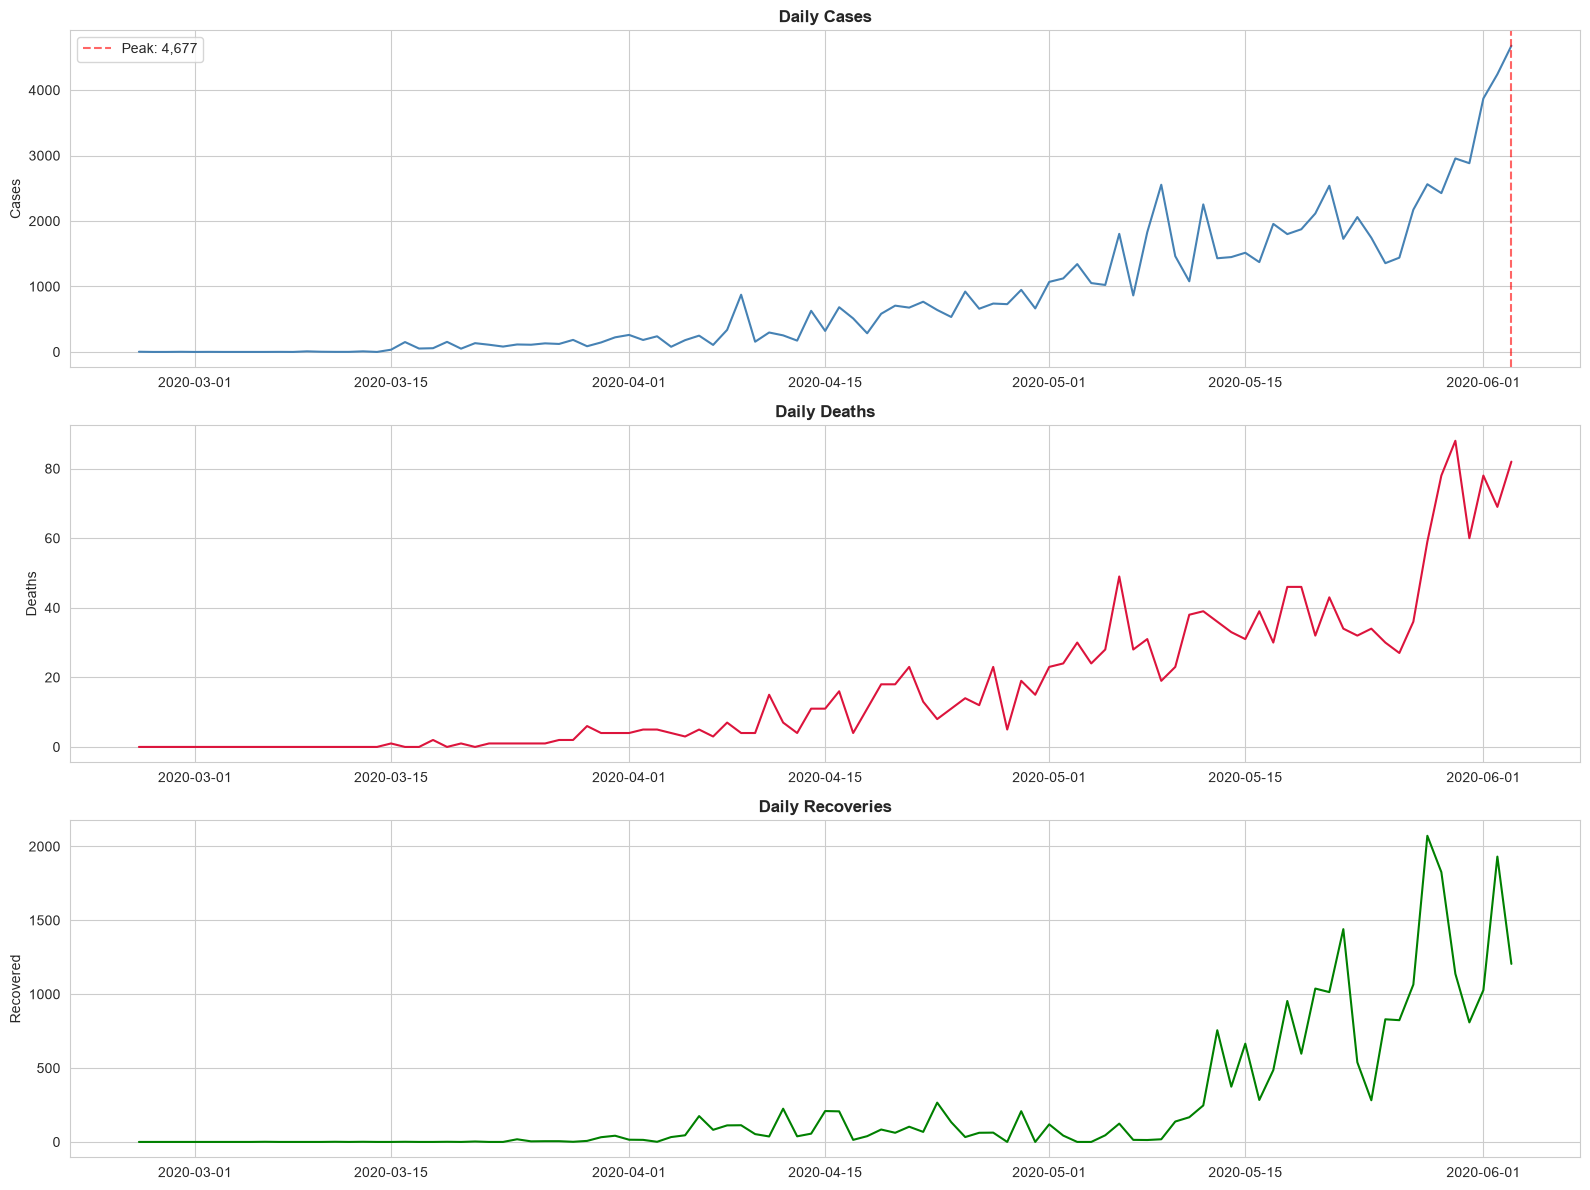

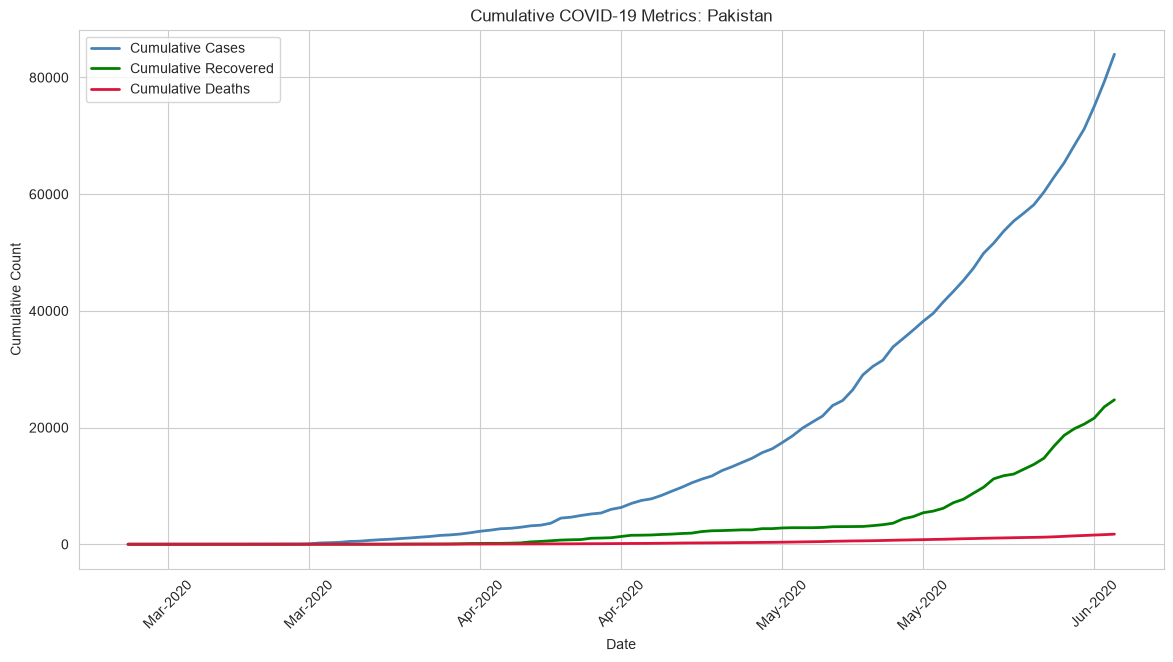

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12))
axes[0].plot(daily_ts.index, daily_ts["Cases"], color="steelblue", linewidth=1.5)
axes[0].set_title("Daily Cases", fontsize=12, fontweight="bold"); axes[0].set_ylabel("Cases")
axes[0].axvline(x=daily_ts["Cases"].idxmax(), color="red", linestyle="--", alpha=0.6, label=f"Peak: {daily_ts['Cases'].max():,.0f}")
axes[0].legend()
axes[1].plot(daily_ts.index, daily_ts["Deaths"], color="crimson", linewidth=1.5)
axes[1].set_title("Daily Deaths", fontsize=12, fontweight="bold"); axes[1].set_ylabel("Deaths")
axes[2].plot(daily_ts.index, daily_ts["Recovered"], color="green", linewidth=1.5)
axes[2].set_title("Daily Recoveries", fontsize=12, fontweight="bold"); axes[2].set_ylabel("Recovered")
plt.tight_layout()
save_ts("ts_basic_plots.png")
plt.show()

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(daily_ts.index, daily_ts["Cases"].cumsum(), color="steelblue", linewidth=2, label="Cumulative Cases")
ax.plot(daily_ts.index, daily_ts["Recovered"].cumsum(), color="green", linewidth=2, label="Cumulative Recovered")
ax.plot(daily_ts.index, daily_ts["Deaths"].cumsum(), color="crimson", linewidth=2, label="Cumulative Deaths")
ax.set(title="Cumulative COVID-19 Metrics: Pakistan", xlabel="Date", ylabel="Cumulative Count")
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%Y"))
plt.xticks(rotation=45)
save_ts("ts_cumulative.png")
plt.show()

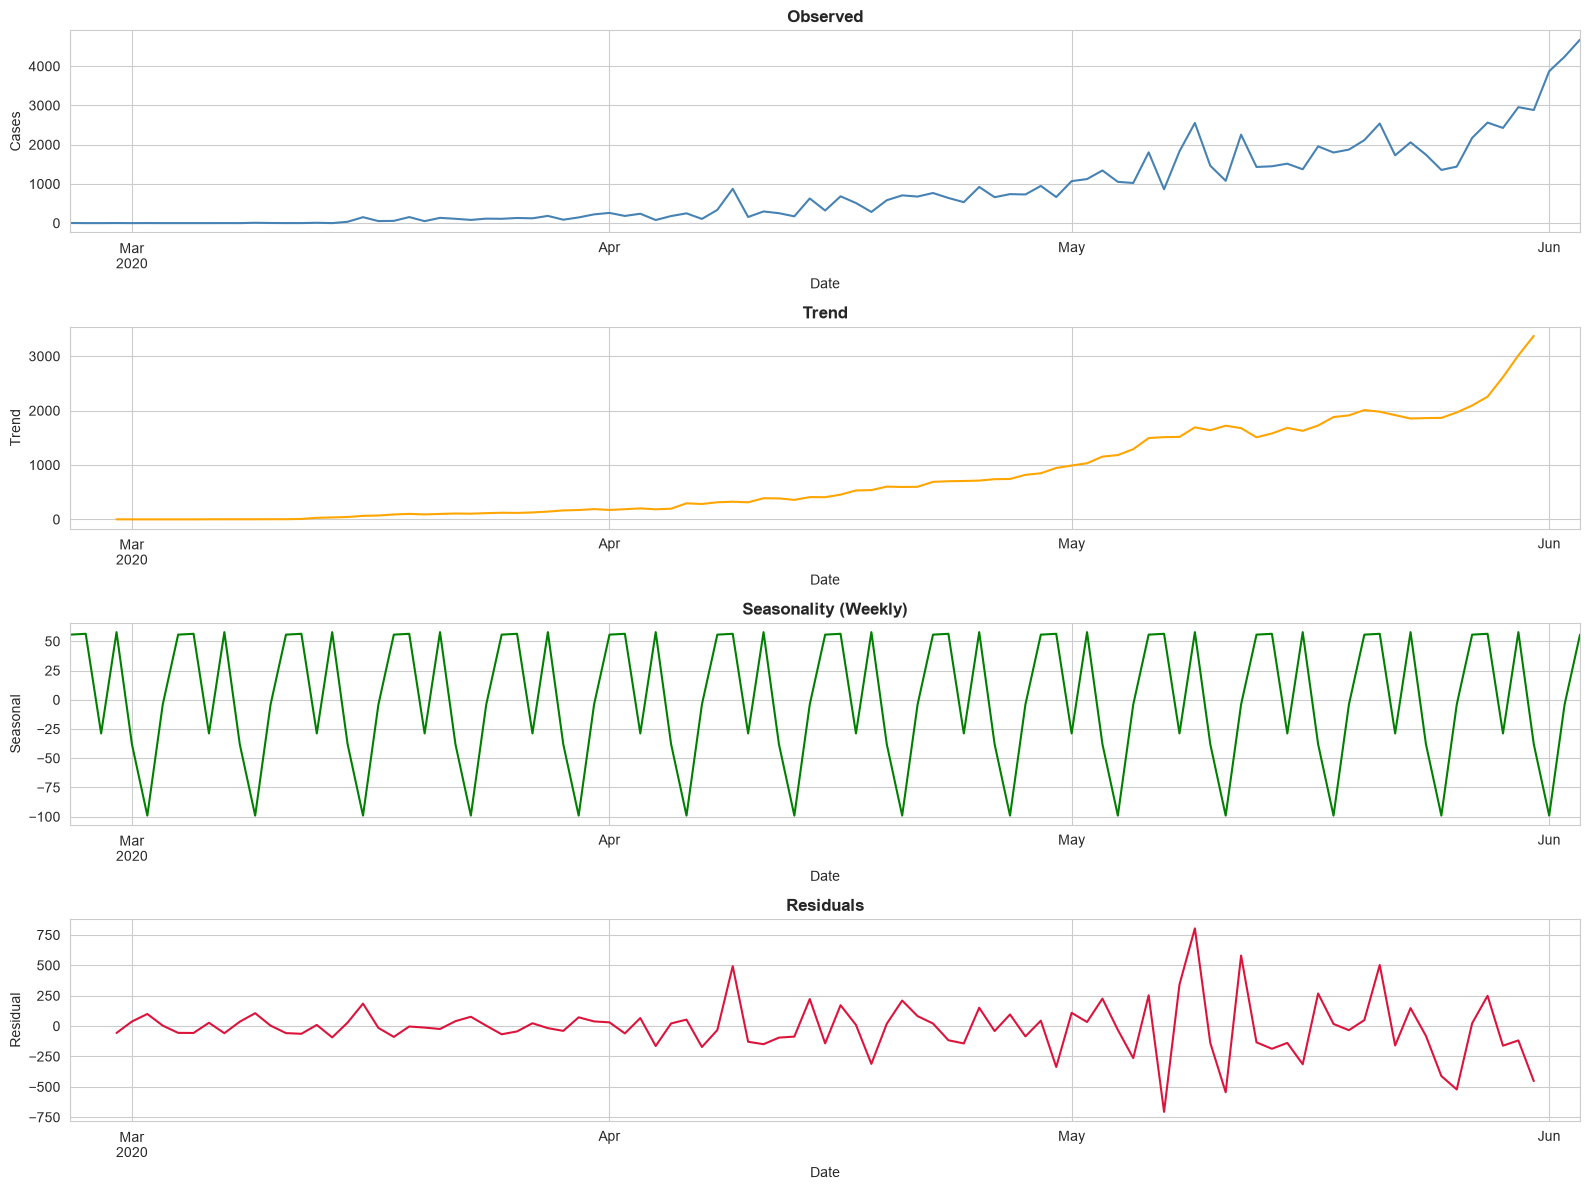

Additive weekly seasonal swing: 157 cases | multiplicative weekly factor range: 0.84 to 1.20
STL seasonal swing (robust): 1,625 cases


In [6]:
# Decomposition: trend, weekly seasonality, residual
decomp = seasonal_decompose(series, model="additive", period=7)
fig, axes = plt.subplots(4, 1, figsize=(16, 12))
decomp.observed.plot(ax=axes[0], color="steelblue"); axes[0].set_title("Observed", fontweight="bold"); axes[0].set_ylabel("Cases")
decomp.trend.plot(ax=axes[1], color="orange"); axes[1].set_title("Trend", fontweight="bold"); axes[1].set_ylabel("Trend")
decomp.seasonal.plot(ax=axes[2], color="green"); axes[2].set_title("Seasonality (Weekly)", fontweight="bold"); axes[2].set_ylabel("Seasonal")
decomp.resid.plot(ax=axes[3], color="crimson"); axes[3].set_title("Residuals", fontweight="bold"); axes[3].set_ylabel("Residual")
plt.tight_layout()
save_ts("ts_decomposition.png")
plt.show()

decomp_mul = seasonal_decompose(series + 1, model="multiplicative", period=7)      # use when the weekly swing grows with the level
stl = STL(series, period=7, robust=True).fit()                                      # robust to the very large late days
seasonal_amp_add = decomp.seasonal.max() - decomp.seasonal.min()
print(f"Additive weekly seasonal swing: {seasonal_amp_add:,.0f} cases | multiplicative weekly factor range: "
      f"{decomp_mul.seasonal.min():.2f} to {decomp_mul.seasonal.max():.2f}")
print(f"STL seasonal swing (robust): {stl.seasonal.max() - stl.seasonal.min():,.0f} cases")

## A4. Stationarity Tests and the Choice of d

ARIMA needs a stationary series. ADF tests the null hypothesis 'not stationary'; KPSS tests the null hypothesis 'stationary'. When they disagree, be cautious.

In [7]:
def stationarity_report(s, name="Series"):
    print(f"\n{'=' * 60}\nSTATIONARITY TESTS: {name}\n{'=' * 60}")
    adf = adfuller(s.dropna(), autolag="AIC")
    print(f"ADF  statistic {adf[0]:.4f} | p-value {adf[1]:.4f} | critical 5%: {adf[4]['5%']:.4f}")
    print("  ->", "Stationary (reject H0)" if adf[1] < 0.05 else "Non-stationary (fail to reject H0)")
    kp = kpss(s.dropna(), regression="c", nlags="auto")
    print(f"KPSS statistic {kp[0]:.4f} | p-value {kp[1]:.4f}")
    print("  ->", "Stationary (fail to reject H0)" if kp[1] > 0.05 else "Non-stationary (reject H0)")
    return adf[1], kp[1]

p_orig, k_orig = stationarity_report(series, "Original Cases")
diff_1 = series.diff().dropna()
p_diff, k_diff = stationarity_report(diff_1, "First Difference")
diff_2 = series.diff().diff().dropna()
p_diff2, k_diff2 = stationarity_report(diff_2, "Second Difference")

if p_orig < 0.05:
    d_rec = 0
elif p_diff < 0.05:
    d_rec = 1
else:
    d_rec = 2
print(f"\n{'=' * 60}\nRECOMMENDATION (ADF): d = {d_rec}\n{'=' * 60}")


STATIONARITY TESTS: Original Cases
ADF  statistic 3.1765 | p-value 1.0000 | critical 5%: -2.8922
  -> Non-stationary (fail to reject H0)
KPSS statistic 1.5303 | p-value 0.0100
  -> Non-stationary (reject H0)

STATIONARITY TESTS: First Difference
ADF  statistic -0.0563 | p-value 0.9536 | critical 5%: -2.8962
  -> Non-stationary (fail to reject H0)
KPSS statistic 0.4006 | p-value 0.0769
  -> Stationary (fail to reject H0)

STATIONARITY TESTS: Second Difference
ADF  statistic -4.8430 | p-value 0.0000 | critical 5%: -2.8962
  -> Stationary (reject H0)
KPSS statistic 0.1103 | p-value 0.1000
  -> Stationary (fail to reject H0)

RECOMMENDATION (ADF): d = 2


C:\Users\NLP\AppData\Local\Temp\ipykernel_15804\1149862820.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp = kpss(s.dropna(), regression="c", nlags="auto")
C:\Users\NLP\AppData\Local\Temp\ipykernel_15804\1149862820.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp = kpss(s.dropna(), regression="c", nlags="auto")


## A5. ACF and PACF

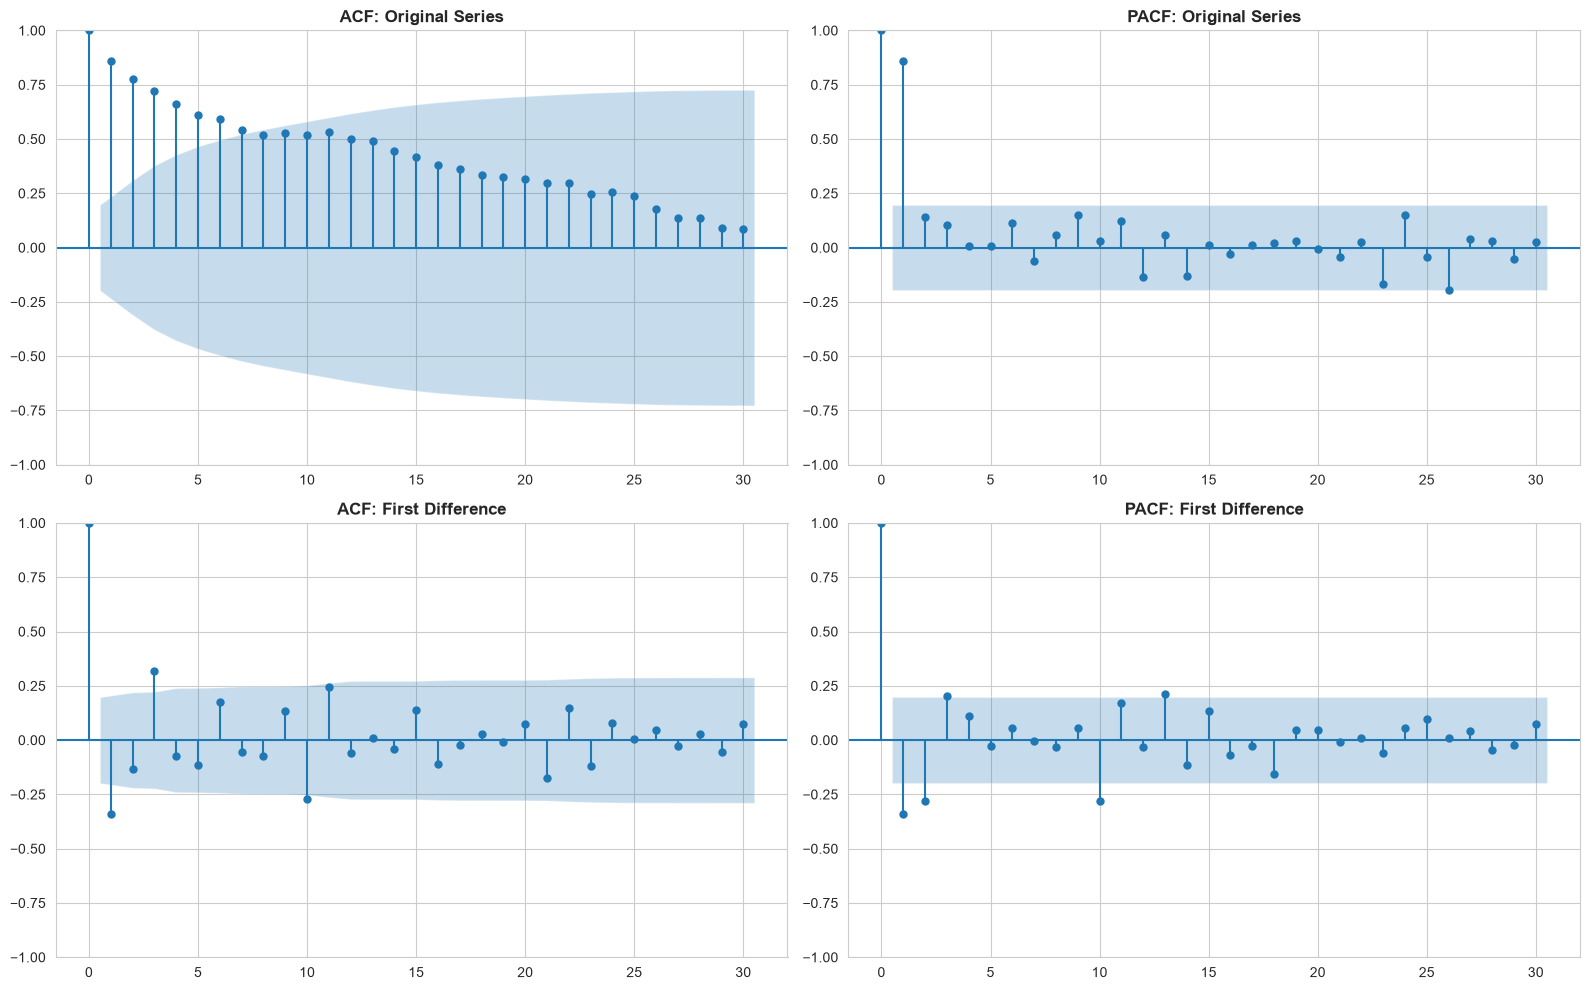

HOW TO READ ACF/PACF
Pattern                                 Model
PACF cuts off after lag p, ACF decays   AR(p)
ACF cuts off after lag q, PACF decays   MA(q)
Both decay gradually                    ARMA(p, q)
ACF has spikes at multiples of s        Seasonal component (here s = 7)


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plot_acf(series.dropna(), lags=30, ax=axes[0, 0], alpha=0.05); axes[0, 0].set_title("ACF: Original Series", fontweight="bold")
plot_pacf(series.dropna(), lags=30, ax=axes[0, 1], alpha=0.05, method="ywm"); axes[0, 1].set_title("PACF: Original Series", fontweight="bold")
plot_acf(diff_1, lags=30, ax=axes[1, 0], alpha=0.05); axes[1, 0].set_title("ACF: First Difference", fontweight="bold")
plot_pacf(diff_1, lags=30, ax=axes[1, 1], alpha=0.05, method="ywm"); axes[1, 1].set_title("PACF: First Difference", fontweight="bold")
plt.tight_layout()
save_ts("ts_acf_pacf.png")
plt.show()
print("""HOW TO READ ACF/PACF
Pattern                                 Model
PACF cuts off after lag p, ACF decays   AR(p)
ACF cuts off after lag q, PACF decays   MA(q)
Both decay gradually                    ARMA(p, q)
ACF has spikes at multiples of s        Seasonal component (here s = 7)""")

## A6. Train/Test Split, Metrics and Naive Baselines

In [9]:
train = series.iloc[:-FORECAST_HORIZON]
test = series.iloc[-FORECAST_HORIZON:]
print(f"Train size: {len(train)} days | {train.index.min().date()} -> {train.index.max().date()}")
print(f"Test size : {len(test)} days | {test.index.min().date()} -> {test.index.max().date()}")

def evaluate(y_true, y_pred, model_name):
    """MAE, RMSE, MAPE (days with zero actuals skipped) and SMAPE."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mask = y_true != 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-10)) * 100
    return {"Model": model_name, "MAE": mae, "RMSE": rmse, "MAPE (%)": mape, "SMAPE (%)": smape}

results = []
preds = {}                                   # model name -> test-period forecast (numpy array), used by the plots

preds["Naive"] = np.repeat(train.iloc[-1], FORECAST_HORIZON)
results.append(evaluate(test, preds["Naive"], "Naive"))
preds["Seasonal Naive"] = np.array([train.iloc[-7 + i % 7] for i in range(FORECAST_HORIZON)])
results.append(evaluate(test, preds["Seasonal Naive"], "Seasonal Naive"))
print("\nBaselines added: Naive (last value) and Seasonal Naive (same weekday last week)")

Train size: 85 days | 2020-02-26 -> 2020-05-20
Test size : 14 days | 2020-05-21 -> 2020-06-03

Baselines added: Naive (last value) and Seasonal Naive (same weekday last week)


## A7. Holt-Winters Exponential Smoothing

In [10]:
hw_add = ExponentialSmoothing(train, seasonal_periods=7, trend="add", seasonal="add", initialization_method="estimated").fit()
preds["Holt-Winters (Additive)"] = np.asarray(hw_add.forecast(FORECAST_HORIZON))
results.append(evaluate(test, preds["Holt-Winters (Additive)"], "Holt-Winters (Additive)"))

hw_mul = ExponentialSmoothing(train + 1, seasonal_periods=7, trend="add", seasonal="mul", initialization_method="estimated").fit()
preds["Holt-Winters (Multiplicative)"] = np.asarray(hw_mul.forecast(FORECAST_HORIZON)) - 1
results.append(evaluate(test, preds["Holt-Winters (Multiplicative)"], "Holt-Winters (Multiplicative)"))

print("Holt-Winters (additive) parameters:")
print(f"  alpha (level)    = {hw_add.params['smoothing_level']:.4f}")
print(f"  beta  (trend)    = {hw_add.params['smoothing_trend']:.4f}")
print(f"  gamma (seasonal) = {hw_add.params['smoothing_seasonal']:.4f}")

Holt-Winters (additive) parameters:
  alpha (level)    = 0.1282
  beta  (trend)    = 0.1282
  gamma (seasonal) = 0.0000


C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


## A8. ARIMA

**Choosing the order.** The guide ranks every (p, d, q) by AIC. AIC values are only comparable between models with the same d, because differencing changes the data the likelihood is computed on. This notebook therefore searches p and q for each d, shows the best of each, and picks the order with the lowest AIC *for the d recommended by the ADF test* (A4).

In [11]:
def arima_grid_search(s, p_range, d_range, q_range):
    rows, models = [], {}
    for p, d, q in product(p_range, d_range, q_range):
        try:
            m = ARIMA(s, order=(p, d, q)).fit()
            rows.append({"p": p, "d": d, "q": q, "AIC": m.aic, "BIC": m.bic})
            models[(p, d, q)] = m
        except Exception:
            continue
    return pd.DataFrame(rows), models

grid_df, grid_models = arima_grid_search(train, range(0, 4), range(0, 3), range(0, 4))

print("=" * 60)
print("ARIMA GRID SEARCH: best order for each d")
print("=" * 60)
best_per_d = grid_df.loc[grid_df.groupby("d")["AIC"].idxmin()]
print(best_per_d.round(2).to_string(index=False))
print("\nTop 10 by AIC within d =", d_rec)
print(grid_df[grid_df["d"] == d_rec].nsmallest(10, "AIC").round(2).to_string(index=False))

pool = grid_df[grid_df["d"] == d_rec] if (grid_df["d"] == d_rec).any() else grid_df
row = pool.loc[pool["AIC"].idxmin()]
best_order = (int(row["p"]), int(row["d"]), int(row["q"]))
print(f"\nBest order (d = {d_rec}): {best_order} | AIC {row['AIC']:.2f}")

C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Pyt

ARIMA GRID SEARCH: best order for each d
 p  d  q     AIC     BIC
 3  0  0 1186.37 1198.58
 2  1  0 1165.91 1173.20
 2  2  1 1156.52 1166.20

Top 10 by AIC within d = 2
 p  d  q     AIC     BIC
 2  2  1 1156.52 1166.20
 2  2  3 1156.66 1171.18
 2  2  2 1157.06 1169.16
 3  2  3 1157.97 1174.90
 3  2  1 1158.14 1170.24
 3  2  2 1158.51 1173.02
 1  2  3 1158.82 1170.92
 0  2  2 1160.70 1167.95
 1  2  2 1162.47 1172.15
 0  2  3 1165.91 1175.58

Best order (d = 2): (2, 2, 1) | AIC 1156.52


In [12]:
arima_model = grid_models[best_order]
print(arima_model.summary())
print("\nCoefficients:")
print(arima_model.params.round(4).to_string())
print(f"\nAIC: {arima_model.aic:.4f} | BIC: {arima_model.bic:.4f}")

fc = arima_model.get_forecast(steps=FORECAST_HORIZON)
arima_pred = fc.predicted_mean
arima_ci = fc.conf_int(alpha=0.05)
arima_name = f"ARIMA{best_order}"
preds[arima_name] = np.asarray(arima_pred)
results.append(evaluate(test, arima_pred, arima_name))

print(f"\nForecast ({FORECAST_HORIZON} days):")
print(pd.DataFrame({"Actual": test.values, "Forecast": np.asarray(arima_pred), "Lower 95%": np.asarray(arima_ci.iloc[:, 0]),
                    "Upper 95%": np.asarray(arima_ci.iloc[:, 1])}, index=test.index).round(1).to_string())

                               SARIMAX Results                                
Dep. Variable:                  Cases   No. Observations:                   85
Model:                 ARIMA(2, 2, 1)   Log Likelihood                -574.262
Date:                Sat, 24 Oct 2026   AIC                           1156.523
Time:                        10:07:28   BIC                           1166.199
Sample:                    02-26-2020   HQIC                          1160.410
                         - 05-20-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7296      0.072    -10.077      0.000      -0.871      -0.588
ar.L2         -0.5883      0.079     -7.495      0.000      -0.742      -0.434
ma.L1         -0.9995      0.961     -1.040      0.2

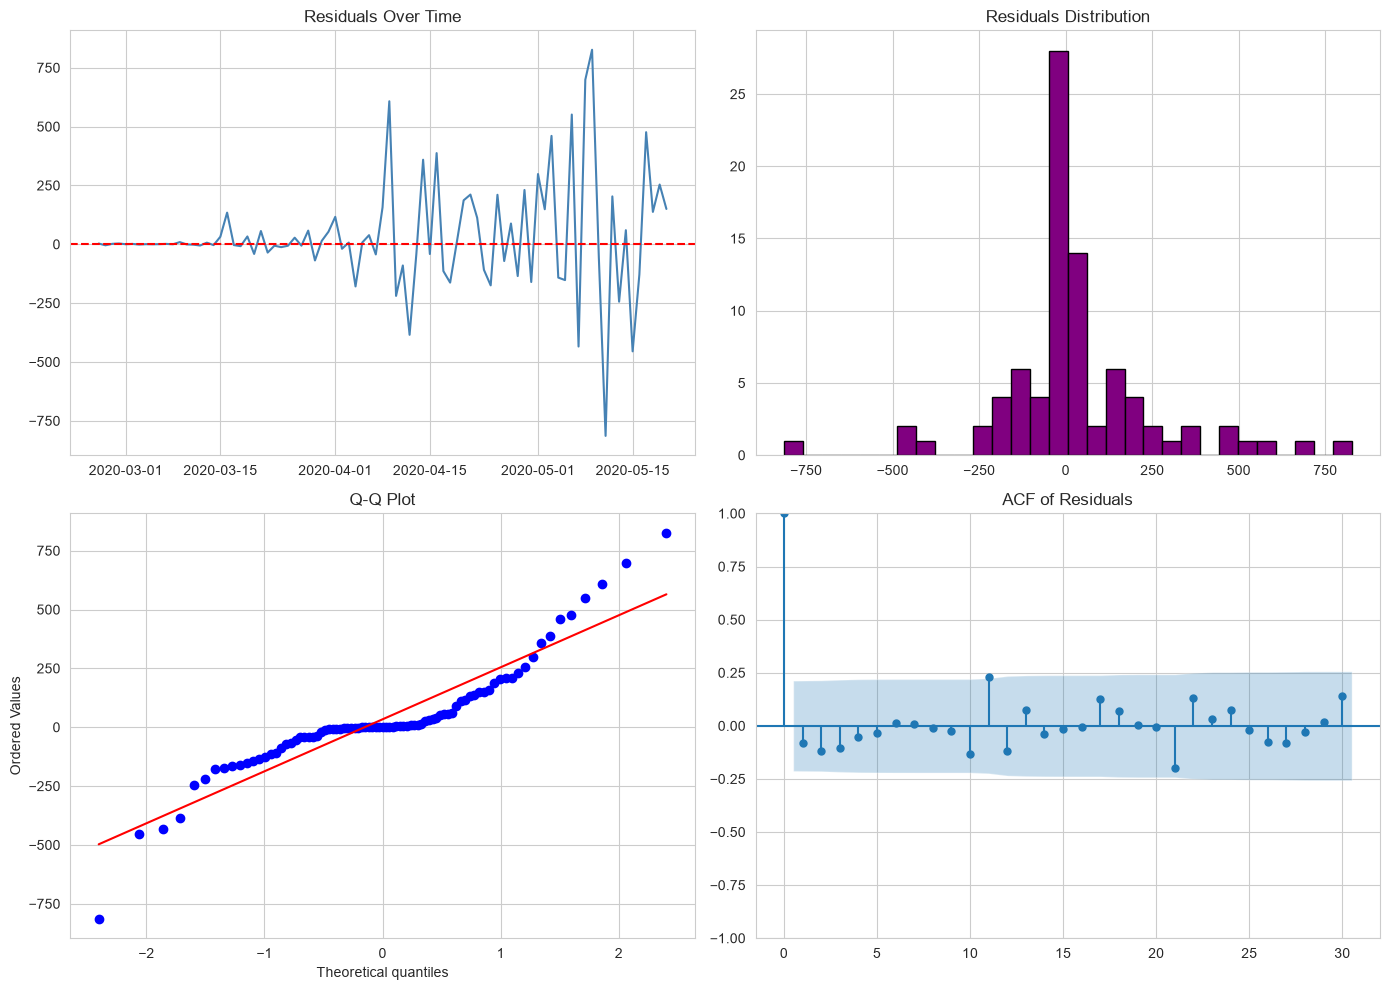

Ljung-Box test (H0: residuals are white noise):
    lb_stat  lb_pvalue
10   5.0418     0.8884
20  14.7857     0.7885
30  26.5028     0.6492
Residuals look like white noise


In [13]:
# ARIMA diagnostics: residuals should look like white noise
residuals = pd.Series(np.asarray(arima_model.resid), index=train.index)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].plot(residuals, color="steelblue"); axes[0, 0].axhline(0, color="red", linestyle="--"); axes[0, 0].set_title("Residuals Over Time")
axes[0, 1].hist(residuals, bins=30, color="purple", edgecolor="black"); axes[0, 1].set_title("Residuals Distribution")
stats.probplot(residuals, dist="norm", plot=axes[1, 0]); axes[1, 0].set_title("Q-Q Plot")
plot_acf(residuals, lags=30, ax=axes[1, 1], alpha=0.05); axes[1, 1].set_title("ACF of Residuals")
plt.tight_layout()
save_ts("ts_arima_diagnostics.png")
plt.show()

lb = acorr_ljungbox(residuals, lags=[10, 20, 30], return_df=True)
print("Ljung-Box test (H0: residuals are white noise):")
print(lb.round(4).to_string())
print("Residuals look like white noise" if (lb["lb_pvalue"] > 0.05).all() else
      "Some autocorrelation remains in the residuals (p < 0.05): the model has not captured all the structure.")

## A9. SARIMA (Seasonal ARIMA)

Seasonal part fixed at (1, 0, 1, 7). The (p, d, q) search uses the same rule as ARIMA: d from the ADF test, p and q by AIC.

In [14]:
def sarima_grid_search(s, d, seasonal=(1, 0, 1, 7)):
    rows, models = [], {}
    for p, q in product(range(0, 3), range(0, 3)):
        try:
            m = SARIMAX(s, order=(p, d, q), seasonal_order=seasonal, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            rows.append({"p": p, "d": d, "q": q, "AIC": m.aic, "BIC": m.bic})
            models[(p, d, q)] = m
        except Exception:
            continue
    return pd.DataFrame(rows), models

sarima_grid, sarima_models = sarima_grid_search(train, min(d_rec, 1))      # d capped at 1 for the seasonal model
best_sarima_order = tuple(int(v) for v in sarima_grid.loc[sarima_grid["AIC"].idxmin(), ["p", "d", "q"]])
best_sarima = sarima_models[best_sarima_order]
sarima_name = f"SARIMA{best_sarima_order}(1,0,1,7)"
print(sarima_grid.sort_values("AIC").head(5).round(2).to_string(index=False))
print(f"\nBest SARIMA: {best_sarima_order} x (1,0,1,7) | AIC {best_sarima.aic:.2f}")

sarima_fc = best_sarima.get_forecast(steps=FORECAST_HORIZON)
sarima_pred = sarima_fc.predicted_mean
sarima_ci = sarima_fc.conf_int(alpha=0.05)
preds[sarima_name] = np.asarray(sarima_pred)
results.append(evaluate(test, sarima_pred, sarima_name))

 p  d  q     AIC     BIC
 2  1  2 1043.19 1059.32
 0  1  2 1050.14 1061.66
 1  1  2 1052.21 1066.04
 2  1  0 1052.82 1064.41
 2  1  1 1054.82 1068.72

Best SARIMA: (2, 1, 2) x (1,0,1,7) | AIC 1043.19


## A10. Optional Methods: Auto-ARIMA and Prophet

In [15]:
auto_model = None
if HAS_PM:
    auto_model = pm.auto_arima(train, start_p=0, max_p=4, start_q=0, max_q=4, d=None, seasonal=True, m=7, start_P=0, max_P=2,
                               start_Q=0, max_Q=2, D=None, information_criterion="aic", stepwise=True, suppress_warnings=True, random_state=42)
    print(auto_model.summary())
    preds["Auto-ARIMA"] = np.asarray(auto_model.predict(n_periods=FORECAST_HORIZON))
    results.append(evaluate(test, preds["Auto-ARIMA"], "Auto-ARIMA"))
else:
    print("pmdarima is not installed: Auto-ARIMA skipped (pip install pmdarima).")

prophet_model = None
if HAS_PROPHET:
    prophet_model = Prophet(yearly_seasonality=False, weekly_seasonality=True, daily_seasonality=False, interval_width=0.95)
    prophet_model.fit(pd.DataFrame({"ds": train.index, "y": train.values}))
    prophet_fc = prophet_model.predict(prophet_model.make_future_dataframe(periods=FORECAST_HORIZON))
    preds["Prophet"] = prophet_fc.tail(FORECAST_HORIZON)["yhat"].to_numpy()
    results.append(evaluate(test, preds["Prophet"], "Prophet"))
    prophet_model.plot_components(prophet_fc)
    save_ts("ts_prophet_components.png")
    plt.show()
else:
    print("prophet is not installed: Prophet skipped (pip install prophet).")

pmdarima is not installed: Auto-ARIMA skipped (pip install pmdarima).
prophet is not installed: Prophet skipped (pip install prophet).


## A11. Model Comparison

In [16]:
results_df = pd.DataFrame(results).round(4)
results_df["Rank"] = results_df["RMSE"].rank().astype(int)
print("=" * 70)
print("FORECAST MODEL COMPARISON (test set = last 14 days)")
print("=" * 70)
print(results_df.sort_values("RMSE").to_string(index=False))

best_model_name = results_df.loc[results_df["RMSE"].idxmin(), "Model"]
naive_rmse = results_df.loc[results_df["Model"] == "Naive", "RMSE"].iloc[0]
best_rmse = results_df["RMSE"].min()
print(f"\nBest model (lowest RMSE): {best_model_name}")
print(f"Improvement over the naive baseline: {(1 - best_rmse / naive_rmse) * 100:.1f}%" if best_model_name != "Naive" else
      "No model beats the naive baseline on this test window. That is a real result: for a fast-growing series, 'tomorrow = today' is hard to beat.")

FORECAST MODEL COMPARISON (test set = last 14 days)
                        Model       MAE      RMSE  MAPE (%)  SMAPE (%)  Rank
      Holt-Winters (Additive)  664.9326  881.3120   25.0385    25.1927     1
Holt-Winters (Multiplicative)  670.1296  895.7697   24.5774    25.3213     2
               ARIMA(2, 2, 1)  757.9375 1025.2201   26.6267    28.7480     3
                        Naive  824.4286 1110.7892   28.8721    31.6004     4
     SARIMA(2, 1, 2)(1,0,1,7)  875.3230 1185.9372   29.0905    33.8938     5
               Seasonal Naive 1048.2857 1310.4563   35.5150    43.9690     6

Best model (lowest RMSE): Holt-Winters (Additive)
Improvement over the naive baseline: 20.7%


## A12. Forecast Visualisation: All Models

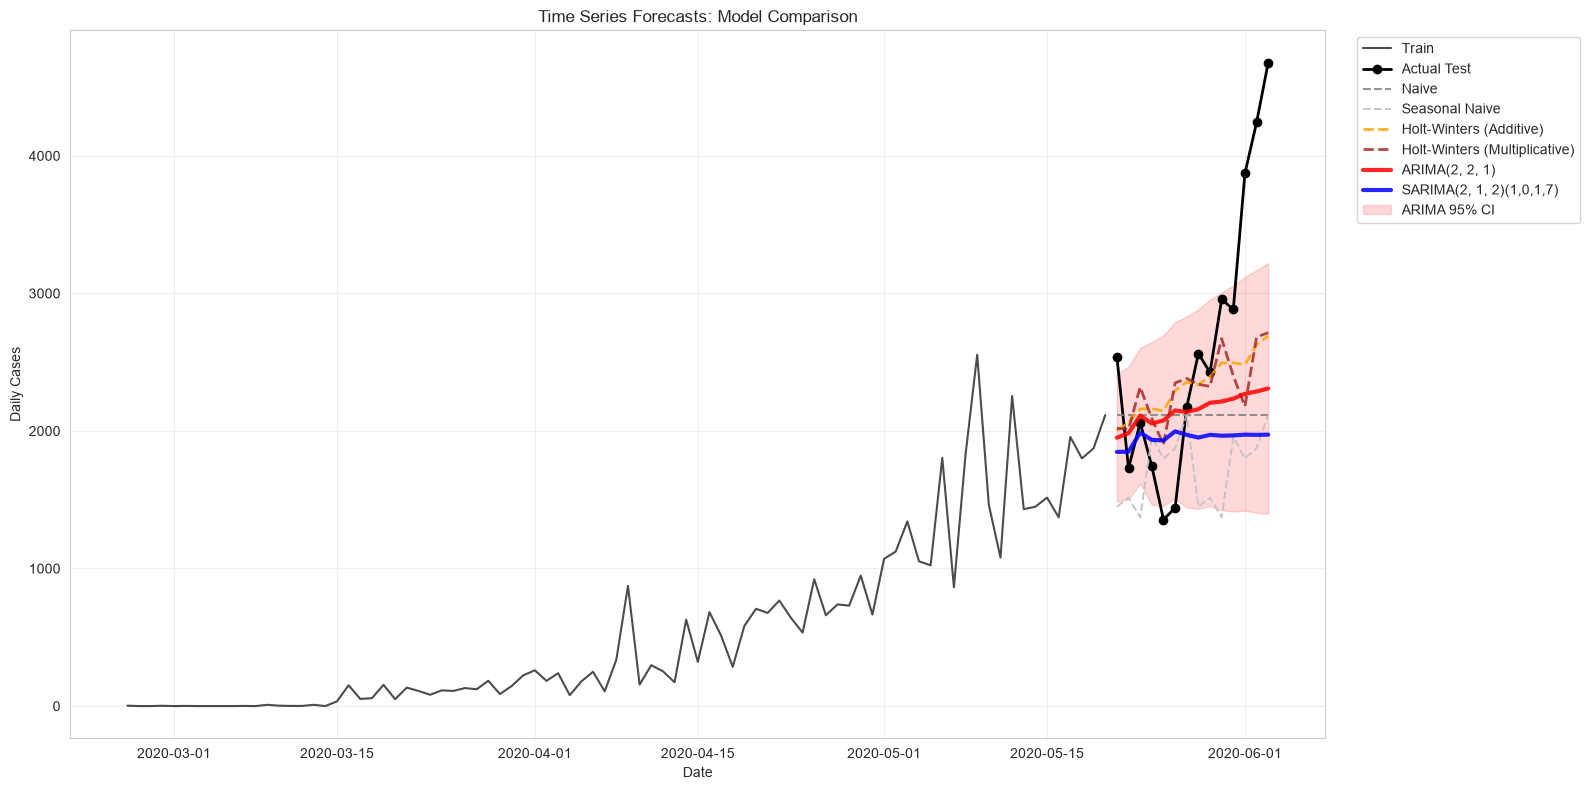

In [17]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(train.index, train.values, "k-", linewidth=1.5, label="Train", alpha=0.7)
ax.plot(test.index, test.values, "o-", color="black", linewidth=2, markersize=6, label="Actual Test")
style = {"Naive": ("gray", "--", 1.5), "Seasonal Naive": ("silver", "--", 1.5), "Holt-Winters (Additive)": ("orange", "--", 2),
         "Holt-Winters (Multiplicative)": ("brown", "--", 2), arima_name: ("red", "-", 3), sarima_name: ("blue", "-", 3),
         "Auto-ARIMA": ("green", "-", 2), "Prophet": ("purple", "-", 2)}
for name, p in preds.items():
    colour, ls, lw = style.get(name, ("teal", "-", 2))
    ax.plot(test.index, p, ls, color=colour, linewidth=lw, label=name, alpha=0.85)
ax.fill_between(test.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], color="red", alpha=0.15, label="ARIMA 95% CI")
ax.set(title="Time Series Forecasts: Model Comparison", xlabel="Date", ylabel="Daily Cases")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
save_ts("ts_forecast_comparison.png")
plt.show()

## A13. Final Refit on All Data and Future Forecast

The best model from A11 is refitted on the whole series and used to forecast the next 14 days. If a baseline won, the forecast is that baseline.

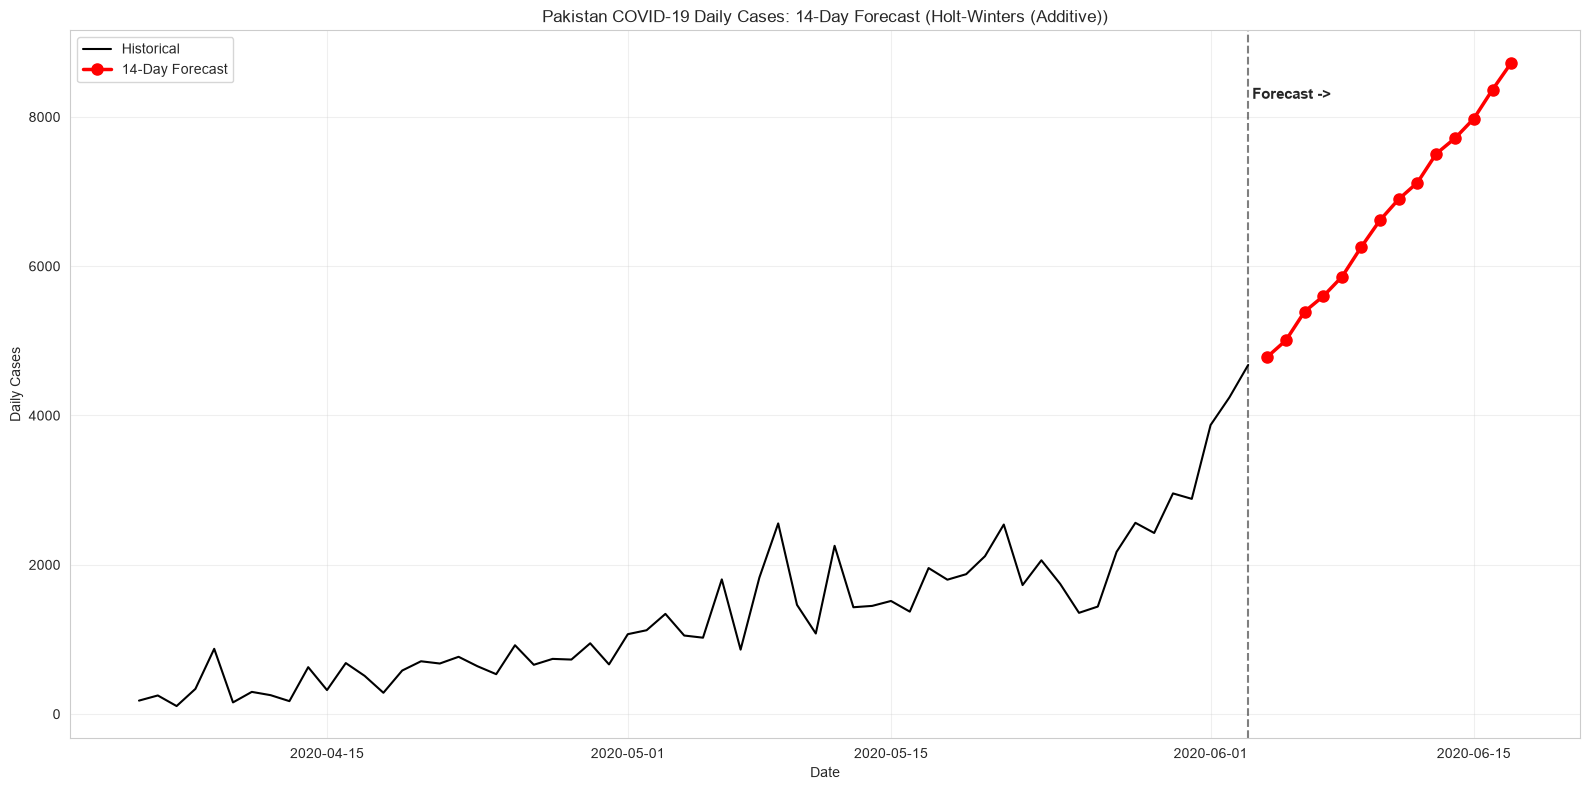

Final 14-Day Forecast:
      Date  Forecast
2020-06-04    4781.9
2020-06-05    5004.9
2020-06-06    5391.2
2020-06-07    5599.6
2020-06-08    5861.8
2020-06-09    6252.2
2020-06-10    6612.7
2020-06-11    6896.5
2020-06-12    7119.6
2020-06-13    7505.8
2020-06-14    7714.2
2020-06-15    7976.4
2020-06-16    8366.8
2020-06-17    8727.3


In [18]:
def future_forecast(name, steps):
    """Refit the named model on ALL data. Returns (mean forecast array, 95% interval DataFrame or None)."""
    if name == "Naive":
        return np.repeat(series.iloc[-1], steps), None
    if name == "Seasonal Naive":
        return np.array([series.iloc[-7 + i % 7] for i in range(steps)]), None
    if name.startswith("ARIMA"):
        f = ARIMA(series, order=best_order).fit().get_forecast(steps=steps)
        return np.asarray(f.predicted_mean), f.conf_int(alpha=0.05)
    if name.startswith("SARIMA"):
        f = SARIMAX(series, order=best_sarima_order, seasonal_order=(1, 0, 1, 7), enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False).get_forecast(steps=steps)
        return np.asarray(f.predicted_mean), f.conf_int(alpha=0.05)
    if name == "Holt-Winters (Additive)":
        m = ExponentialSmoothing(series, seasonal_periods=7, trend="add", seasonal="add", initialization_method="estimated").fit()
        return np.asarray(m.forecast(steps)), None
    if name == "Holt-Winters (Multiplicative)":
        m = ExponentialSmoothing(series + 1, seasonal_periods=7, trend="add", seasonal="mul", initialization_method="estimated").fit()
        return np.asarray(m.forecast(steps)) - 1, None
    if name == "Auto-ARIMA" and HAS_PM:
        m = pm.auto_arima(series, seasonal=True, m=7, suppress_warnings=True, random_state=42)
        mean, ci = m.predict(n_periods=steps, return_conf_int=True)
        return np.asarray(mean), pd.DataFrame(ci)
    if name == "Prophet" and HAS_PROPHET:
        m = Prophet(yearly_seasonality=False, weekly_seasonality=True, daily_seasonality=False, interval_width=0.95)
        m.fit(pd.DataFrame({"ds": series.index, "y": series.values}))
        f = m.predict(m.make_future_dataframe(periods=steps)).tail(steps)
        return f["yhat"].to_numpy(), pd.DataFrame({"lo": f["yhat_lower"].to_numpy(), "hi": f["yhat_upper"].to_numpy()})
    raise ValueError(f"No refit rule for {name}")

future_dates = pd.date_range(series.index.max() + pd.Timedelta(days=1), periods=14)
future_pred, future_ci = future_forecast(best_model_name, 14)

fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(series.iloc[-60:].index, series.iloc[-60:].values, "k-", linewidth=1.5, label="Historical")
ax.plot(future_dates, future_pred, "r-", linewidth=2.5, marker="o", markersize=8, label="14-Day Forecast")
if future_ci is not None:
    ax.fill_between(future_dates, future_ci.iloc[:, 0], future_ci.iloc[:, 1], color="red", alpha=0.2, label="95% Confidence Interval")
ax.axvline(x=series.index.max(), color="black", linestyle="--", alpha=0.5)
ax.text(series.index.max(), ax.get_ylim()[1] * 0.9, " Forecast ->", fontsize=11, fontweight="bold")
ax.set(title=f"Pakistan COVID-19 Daily Cases: 14-Day Forecast ({best_model_name})", xlabel="Date", ylabel="Daily Cases")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
save_ts("ts_final_forecast.png")
plt.show()

forecast_summary = pd.DataFrame({"Date": future_dates.date, "Forecast": np.round(future_pred, 1)})
if future_ci is not None:
    forecast_summary["Lower 95%"] = np.round(np.asarray(future_ci.iloc[:, 0]), 1)
    forecast_summary["Upper 95%"] = np.round(np.asarray(future_ci.iloc[:, 1]), 1)
print("Final 14-Day Forecast:")
print(forecast_summary.to_string(index=False))

## A14. Per-Province Forecasts

Uses Auto-ARIMA when `pmdarima` is installed; otherwise a small ARIMA search (d = 1, p and q from 0 to 2) per province. Forecasts below zero are set to zero because case counts cannot be negative.

C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Pyt

Model used per province: {'Azad Jammu Kashmir': 'ARIMA(0, 1, 2)', 'Balochistan': 'ARIMA(2, 1, 2)', 'Federally Administered Tribal Areas': 'ARIMA(0, 1, 1)', 'Gilgit-Baltistan': 'ARIMA(1, 1, 0)', 'Islamabad Capital Territory': 'ARIMA(2, 1, 2)', 'Khyber Pakhtunkhwa': 'ARIMA(1, 1, 0)', 'Punjab': 'ARIMA(2, 1, 0)', 'Sindh': 'ARIMA(1, 1, 0)'}


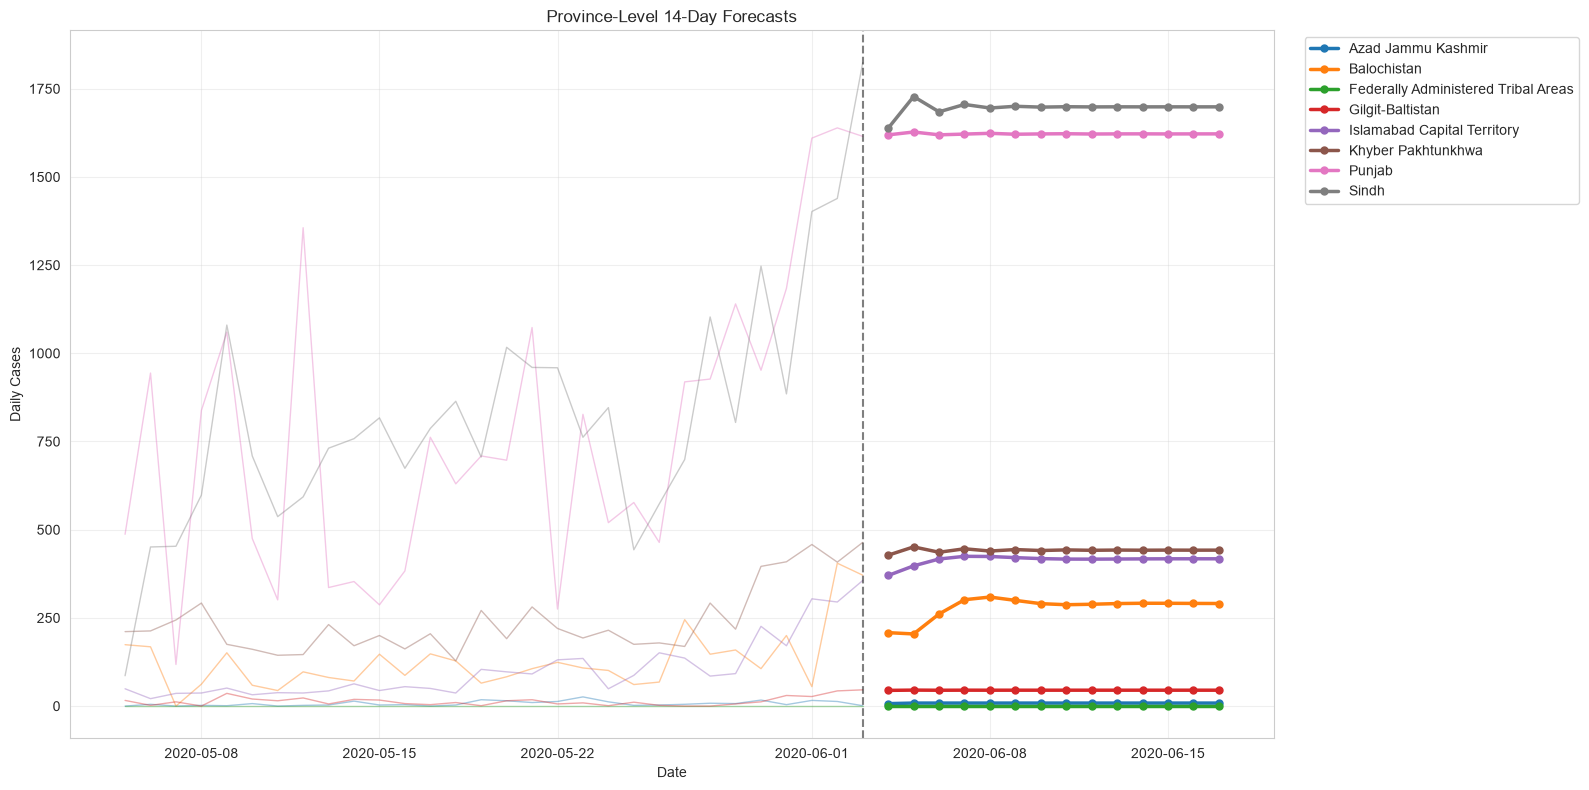

Azad Jammu Kashmir                       111
Balochistan                             3904
Federally Administered Tribal Areas        0
Gilgit-Baltistan                         629
Islamabad Capital Territory             5790
Khyber Pakhtunkhwa                      6180
Punjab                                 22707
Sindh                                  23741


In [19]:
province_daily = df.groupby(["Date", "Province"])["Cases"].sum().reset_index()
prov_pivot = province_daily.pivot(index="Date", columns="Province", values="Cases").fillna(0).sort_index()
prov_pivot = prov_pivot.reindex(pd.date_range(prov_pivot.index.min(), prov_pivot.index.max(), freq="D")).fillna(0)

def province_forecast(s, steps=14):
    if HAS_PM:
        m = pm.auto_arima(s, start_p=0, max_p=3, start_q=0, max_q=3, d=None, seasonal=True, m=7, start_P=0, max_P=1, start_Q=0, max_Q=1,
                          information_criterion="aic", stepwise=True, suppress_warnings=True, random_state=42)
        return np.asarray(m.predict(n_periods=steps)), "Auto-ARIMA"
    best, best_aic = None, np.inf
    for p, q in product(range(3), range(3)):
        try:
            m = ARIMA(s, order=(p, 1, q)).fit()
            if m.aic < best_aic:
                best, best_aic, order = m, m.aic, (p, 1, q)
        except Exception:
            continue
    if best is None:
        return np.repeat(s.iloc[-7:].mean(), steps), "7-day mean (fallback)"
    return np.asarray(best.forecast(steps)), f"ARIMA{order}"

province_forecasts, province_models = {}, {}
for prov in prov_pivot.columns:
    try:
        f, how = province_forecast(prov_pivot[prov])
        province_forecasts[prov] = np.clip(f, 0, None)
        province_models[prov] = how
    except Exception as e:
        print(f"Skipped {prov}: {e}")
print("Model used per province:", province_models)

fig, ax = plt.subplots(figsize=(16, 8))
prov_future_dates = pd.date_range(prov_pivot.index.max() + pd.Timedelta(days=1), periods=14)
cmap = plt.cm.tab10
for i, (prov, f) in enumerate(province_forecasts.items()):
    ax.plot(prov_pivot.index[-30:], prov_pivot[prov].iloc[-30:], color=cmap(i), alpha=0.4, linewidth=1)
    ax.plot(prov_future_dates, f, color=cmap(i), linewidth=2.5, marker="o", markersize=5, label=prov)
ax.axvline(x=prov_pivot.index.max(), color="black", linestyle="--", alpha=0.5)
ax.set(title="Province-Level 14-Day Forecasts", xlabel="Date", ylabel="Daily Cases")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
save_ts("ts_province_forecasts.png")
plt.show()
print(pd.DataFrame(province_forecasts, index=prov_future_dates.date).round(0).astype(int).sum().rename("14-day total").to_string())

## A15. Forecast with Confidence Intervals (21 Days)

The ARIMA model is refitted on all data so the 21 days really lie after the last observation. The shaded band widens with the horizon.

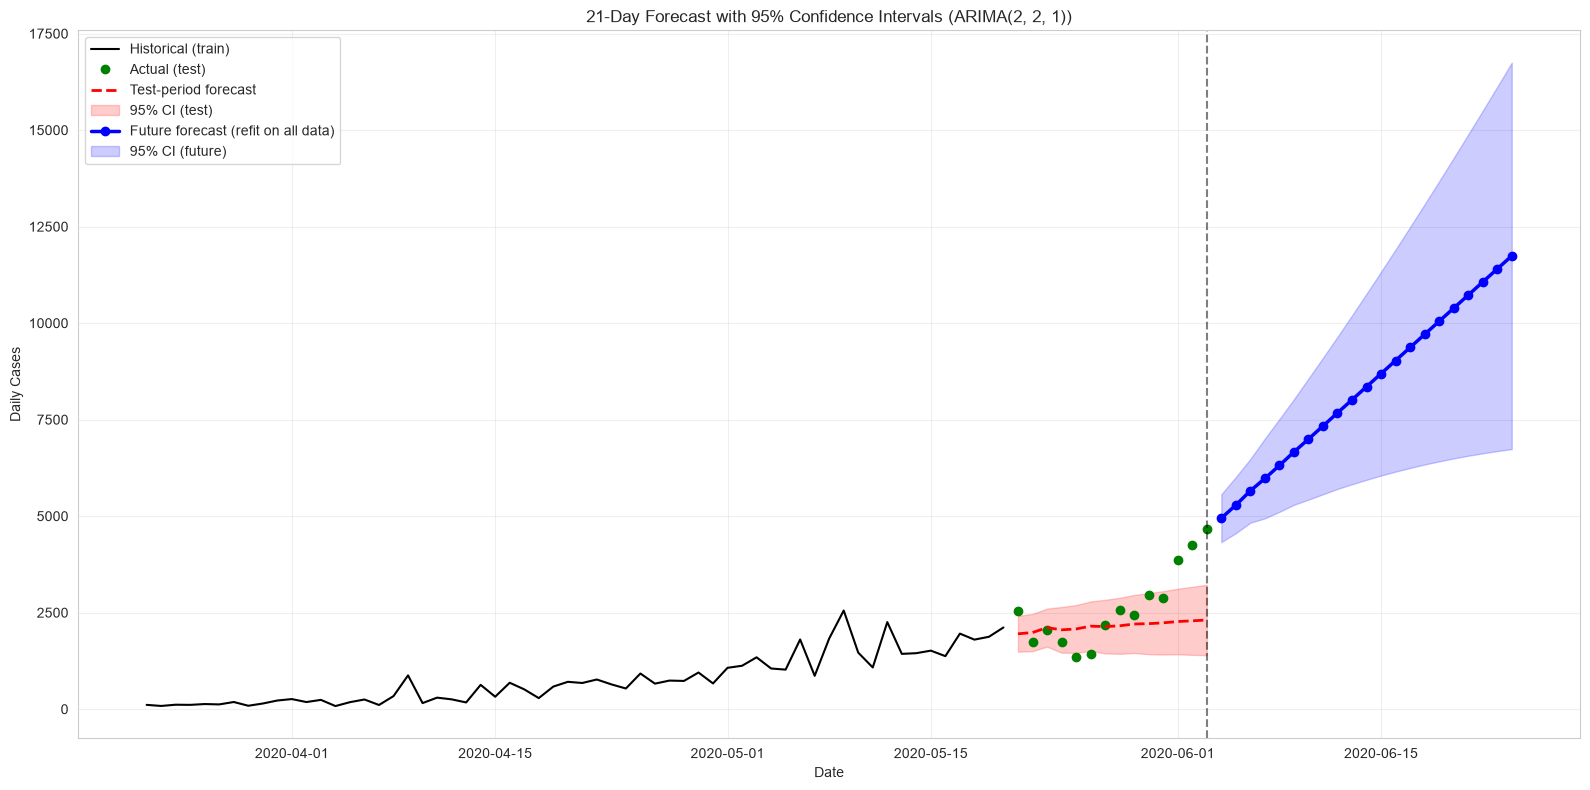

Interval width: day 1 = 1,238 | day 7 = 3,137 | day 14 = 6,243 | day 21 = 10,011


In [20]:
final_arima = ARIMA(series, order=best_order).fit()
f21 = final_arima.get_forecast(steps=21)
mean21 = np.asarray(f21.predicted_mean)
ci21 = f21.conf_int(alpha=0.05)
future_dates21 = pd.date_range(series.index.max() + pd.Timedelta(days=1), periods=21)

fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(train.index[-60:], train.values[-60:], "k-", label="Historical (train)", linewidth=1.5)
ax.plot(test.index, test.values, "o", color="green", markersize=6, label="Actual (test)")
ax.plot(test.index, arima_pred, "r--", linewidth=2, label="Test-period forecast")
ax.fill_between(test.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], color="red", alpha=0.2, label="95% CI (test)")
ax.plot(future_dates21, mean21, "b-", linewidth=2.5, marker="o", label="Future forecast (refit on all data)")
ax.fill_between(future_dates21, ci21.iloc[:, 0], ci21.iloc[:, 1], color="blue", alpha=0.2, label="95% CI (future)")
ax.axvline(x=series.index.max(), color="black", linestyle="--", alpha=0.5)
ax.set(title=f"21-Day Forecast with 95% Confidence Intervals (ARIMA{best_order})", xlabel="Date", ylabel="Daily Cases")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
save_ts("ts_forecast_ci.png")
plt.show()
width = np.asarray(ci21.iloc[:, 1]) - np.asarray(ci21.iloc[:, 0])
print(f"Interval width: day 1 = {width[0]:,.0f} | day 7 = {width[6]:,.0f} | day 14 = {width[13]:,.0f} | day 21 = {width[20]:,.0f}")

## A16. Rolling-Origin Cross-Validation

In [21]:
tscv = TimeSeriesSplit(n_splits=5)
rows = []
for fold, (tr_idx, te_idx) in enumerate(tscv.split(series), 1):
    tr, te = series.iloc[tr_idx], series.iloc[te_idx]
    try:
        pred = ARIMA(tr, order=best_order).fit().forecast(steps=len(te))
        naive = np.repeat(tr.iloc[-1], len(te))
        rows.append({"Fold": fold, "Train Size": len(tr), "Test Size": len(te),
                     "MAE": mean_absolute_error(te, pred), "RMSE": np.sqrt(mean_squared_error(te, pred)),
                     "Naive RMSE": np.sqrt(mean_squared_error(te, naive))})
    except Exception as e:
        print(f"Fold {fold} skipped: {e}")
cv_df = pd.DataFrame(rows)
print("Time series cross-validation (expanding window):")
print(cv_df.round(2).to_string(index=False))
print(f"\nMean RMSE: ARIMA {cv_df['RMSE'].mean():.2f} +/- {cv_df['RMSE'].std():.2f} | Naive {cv_df['Naive RMSE'].mean():.2f}")

C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\NLP\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Time series cross-validation (expanding window):
 Fold  Train Size  Test Size    MAE    RMSE  Naive RMSE
    1          19         16  46.65   60.18       96.81
    2          35         16 138.08  222.67      233.90
    3          51         16 136.46  181.96      210.09
    4          67         16 447.20  584.91      617.77
    5          83         16 757.58 1058.98     1204.37

Mean RMSE: ARIMA 421.74 +/- 406.37 | Naive 472.59


## A17. Export All Results

In [22]:
if SAVE_OUTPUTS:
    with pd.ExcelWriter(OUT_TS / "Forecasting_Report.xlsx", engine="openpyxl") as writer:
        daily_ts.reset_index().assign(Date=lambda d: d["Date"].dt.date).to_excel(writer, sheet_name="Daily_Data", index=False)
        train.rename_axis("Date").rename("Cases").reset_index().assign(Date=lambda d: d["Date"].dt.date).to_excel(writer, sheet_name="Train", index=False)
        test.rename_axis("Date").rename("Cases").reset_index().assign(Date=lambda d: d["Date"].dt.date).to_excel(writer, sheet_name="Test", index=False)
        results_df.to_excel(writer, sheet_name="Model_Comparison", index=False)
        pd.DataFrame({"Date": test.index.date, "Actual": test.values, "ARIMA_Forecast": np.asarray(arima_pred),
                      "ARIMA_Lower": np.asarray(arima_ci.iloc[:, 0]), "ARIMA_Upper": np.asarray(arima_ci.iloc[:, 1])}).to_excel(
            writer, sheet_name="Test_Forecast", index=False)
        pd.DataFrame({"Date": future_dates21.date, "ARIMA_Forecast": mean21, "Lower_95": np.asarray(ci21.iloc[:, 0]),
                      "Upper_95": np.asarray(ci21.iloc[:, 1])}).to_excel(writer, sheet_name="Future_Forecast_21d", index=False)
        forecast_summary.to_excel(writer, sheet_name="Best_Model_Forecast_14d", index=False)
        cv_df.to_excel(writer, sheet_name="CV_Results", index=False)
        pd.DataFrame(province_forecasts, index=prov_future_dates.date).to_excel(writer, sheet_name="Province_Forecasts")
        grid_df.to_excel(writer, sheet_name="ARIMA_Grid", index=False)
    print("Exported:", OUT_TS / "Forecasting_Report.xlsx")
else:
    print("SAVE_OUTPUTS is False: nothing exported.")

Exported: D:\DA projects\Covid-19-portfolio\outputs\forecasting\Forecasting_Report.xlsx


## A18. Forecasting Dashboard

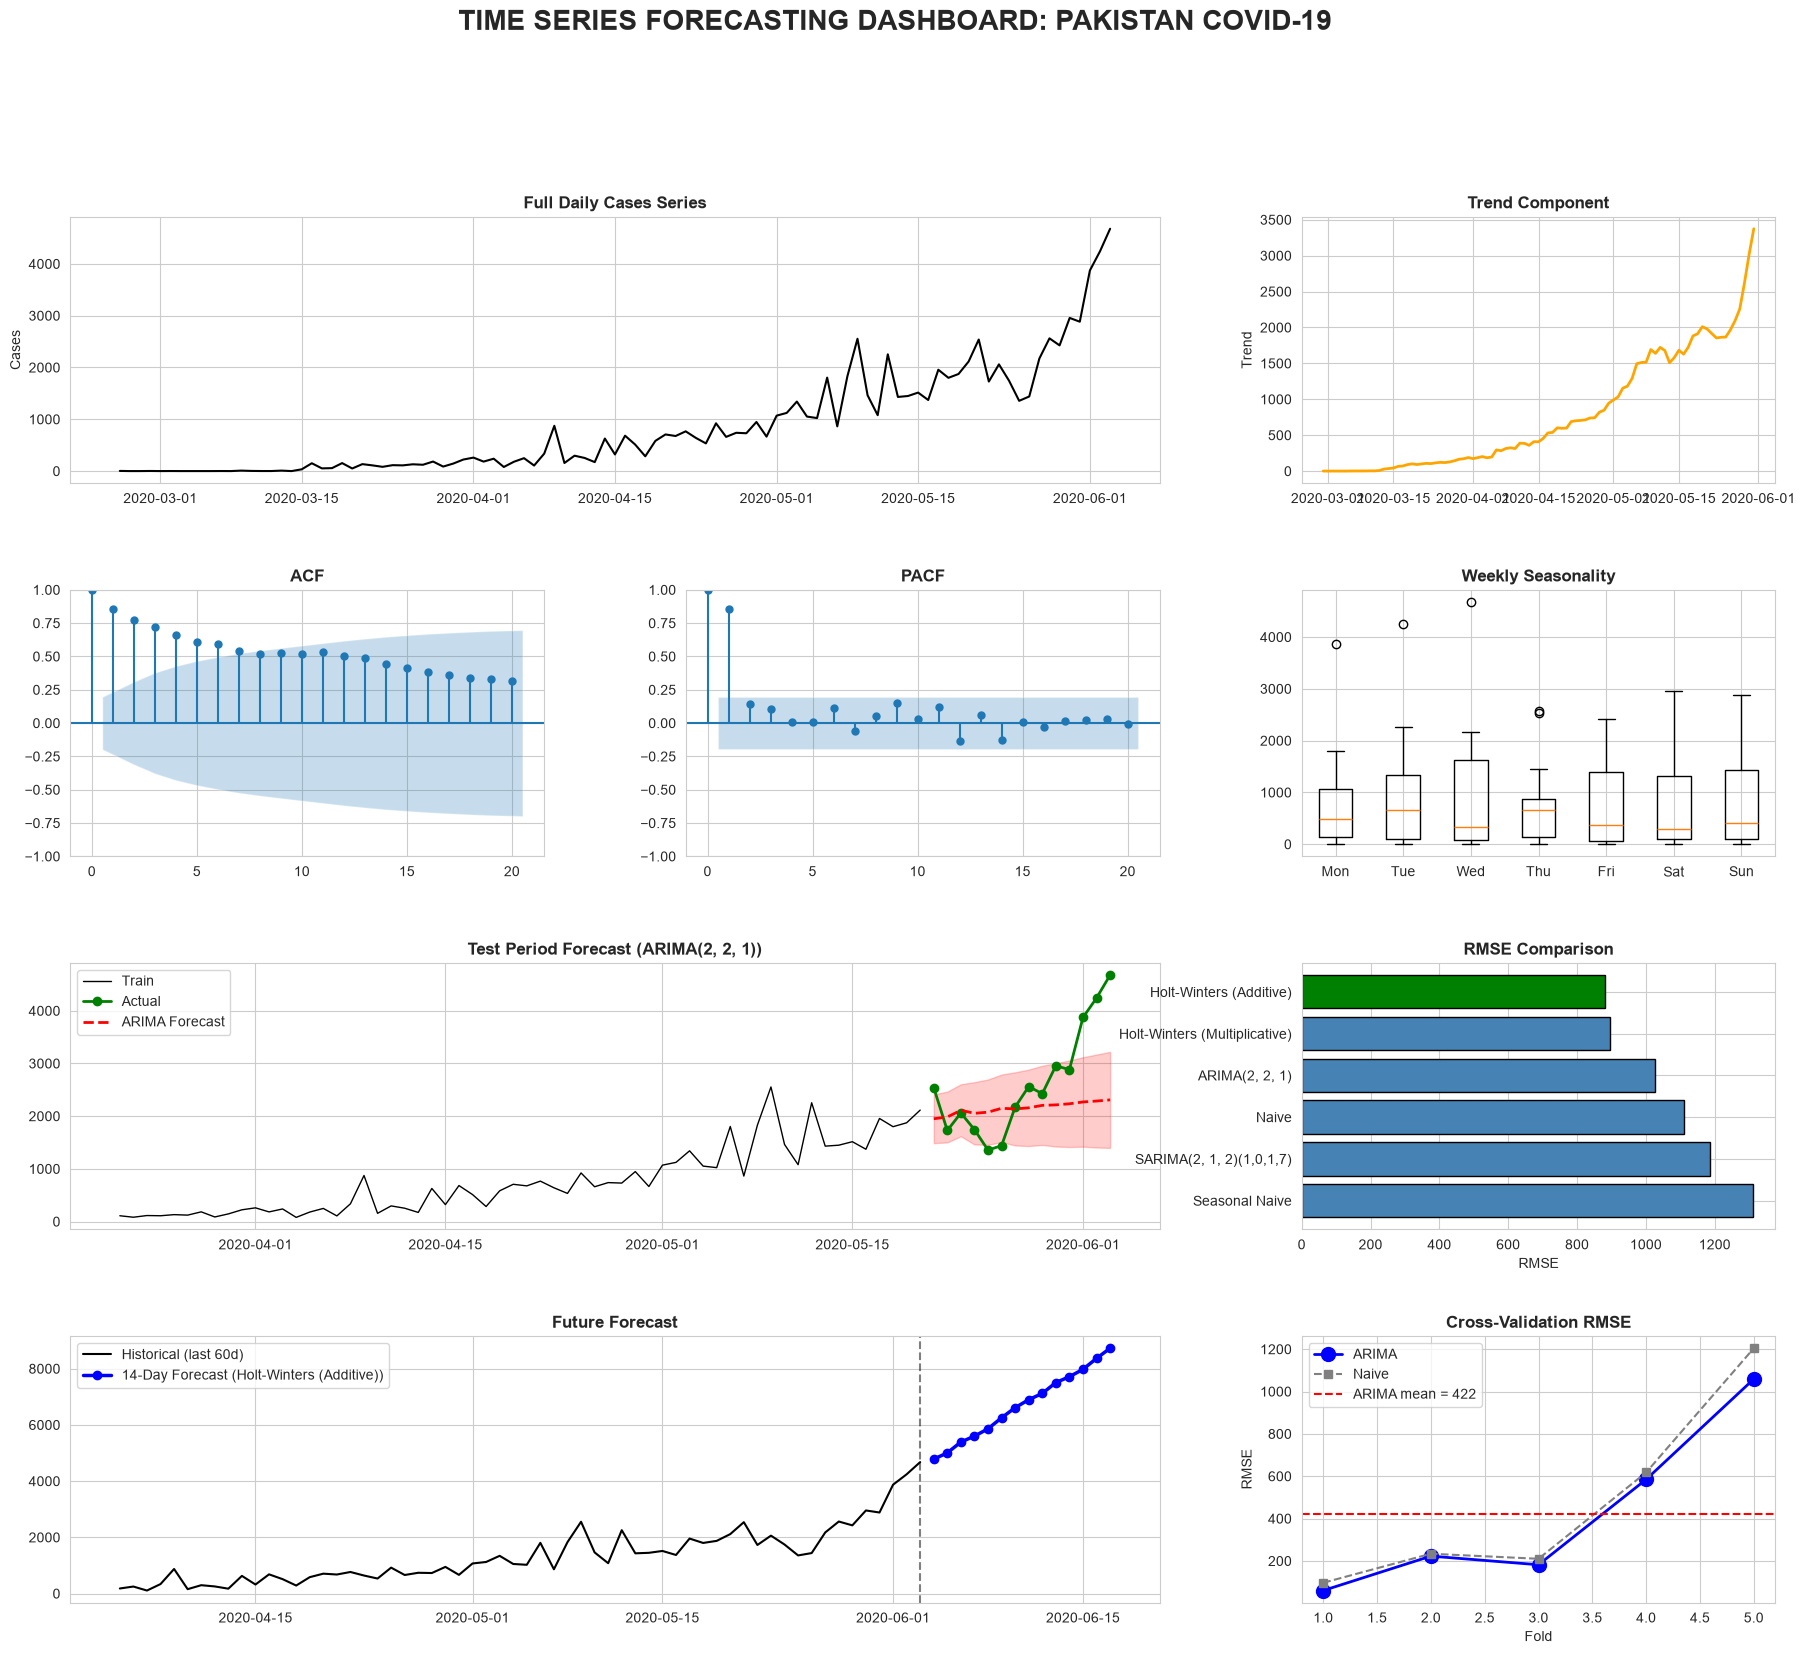

In [23]:
fig = plt.figure(figsize=(22, 18))
gs = fig.add_gridspec(4, 3, hspace=0.4, wspace=0.3)

ax1 = fig.add_subplot(gs[0, :2]); ax1.plot(daily_ts.index, daily_ts["Cases"], "k-", linewidth=1.5)
ax1.set_title("Full Daily Cases Series", fontweight="bold"); ax1.set_ylabel("Cases")

ax2 = fig.add_subplot(gs[0, 2]); ax2.plot(decomp.trend.index, decomp.trend.values, color="orange", linewidth=2)
ax2.set_title("Trend Component", fontweight="bold"); ax2.set_ylabel("Trend")

ax3 = fig.add_subplot(gs[1, 0]); plot_acf(series.dropna(), lags=20, ax=ax3, alpha=0.05); ax3.set_title("ACF", fontweight="bold")
ax4 = fig.add_subplot(gs[1, 1]); plot_pacf(series.dropna(), lags=20, ax=ax4, alpha=0.05, method="ywm"); ax4.set_title("PACF", fontweight="bold")

ax5 = fig.add_subplot(gs[1, 2])
dow = [series[series.index.dayofweek == d].values for d in range(7)]
ax5.boxplot(dow)
ax5.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax5.set_title("Weekly Seasonality", fontweight="bold")

ax6 = fig.add_subplot(gs[2, :2])
ax6.plot(train.index[-60:], train.values[-60:], "k-", label="Train", linewidth=1)
ax6.plot(test.index, test.values, "go-", label="Actual", linewidth=2)
ax6.plot(test.index, arima_pred, "r--", linewidth=2, label="ARIMA Forecast")
ax6.fill_between(test.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], color="red", alpha=0.2)
ax6.set_title(f"Test Period Forecast (ARIMA{best_order})", fontweight="bold"); ax6.legend()

ax7 = fig.add_subplot(gs[2, 2])
scores_sorted = results_df.sort_values("RMSE")
ax7.barh(scores_sorted["Model"], scores_sorted["RMSE"], color=["green" if i == 0 else "steelblue" for i in range(len(scores_sorted))], edgecolor="black")
ax7.set_title("RMSE Comparison", fontweight="bold"); ax7.invert_yaxis(); ax7.set_xlabel("RMSE")

ax8 = fig.add_subplot(gs[3, :2])
ax8.plot(series.index[-60:], series.values[-60:], "k-", label="Historical (last 60d)", linewidth=1.5)
ax8.plot(future_dates, future_pred, "b-", marker="o", linewidth=2.5, label=f"14-Day Forecast ({best_model_name})")
if future_ci is not None:
    ax8.fill_between(future_dates, future_ci.iloc[:, 0], future_ci.iloc[:, 1], color="blue", alpha=0.2, label="95% CI")
ax8.axvline(x=series.index.max(), color="black", linestyle="--", alpha=0.5)
ax8.set_title("Future Forecast", fontweight="bold"); ax8.legend()

ax9 = fig.add_subplot(gs[3, 2])
ax9.plot(cv_df["Fold"], cv_df["RMSE"], "bo-", linewidth=2, markersize=10, label="ARIMA")
ax9.plot(cv_df["Fold"], cv_df["Naive RMSE"], "s--", color="gray", label="Naive")
ax9.axhline(cv_df["RMSE"].mean(), color="red", linestyle="--", label=f"ARIMA mean = {cv_df['RMSE'].mean():.0f}")
ax9.set_title("Cross-Validation RMSE", fontweight="bold"); ax9.set_xlabel("Fold"); ax9.set_ylabel("RMSE"); ax9.legend()

plt.suptitle("TIME SERIES FORECASTING DASHBOARD: PAKISTAN COVID-19", fontsize=20, fontweight="bold", y=0.995)
save_ts("ts_dashboard.png")
plt.show()

## A19. Interpretation (computed from your data)

In [24]:
print("=" * 70)
print("KEY FINDINGS")
print("=" * 70)

# Stationarity
print(f"1. Stationarity: ADF p-value is {p_orig:.3f} for the original series and {p_diff:.3f} after one difference -> recommended d = {d_rec}.")
if (p_orig < 0.05) != (k_orig > 0.05):
    print("   ADF and KPSS disagree on the original series, so treat the choice of d as a judgement call.")

# Weekly pattern: ratio of each weekday to the centred 7-day mean
ratio = (series / series.rolling(7, center=True).mean()).dropna()
by_dow = ratio.groupby(ratio.index.dayofweek).mean()
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hi, lo = by_dow.idxmax(), by_dow.idxmin()
print(f"2. Weekly pattern: {names[hi]} is the highest reporting day ({by_dow[hi]:.2f}x its weekly average) and "
      f"{names[lo]} the lowest ({by_dow[lo]:.2f}x). A swing of this size is {'visible' if by_dow.max() - by_dow.min() > 0.2 else 'modest'} but not dominant.")

# Models
print(f"3. Best model on the 14-day test window: {best_model_name} (RMSE {best_rmse:,.0f}; naive {naive_rmse:,.0f}).")
print(f"   Chosen ARIMA order: {best_order}; SARIMA order: {best_sarima_order}x(1,0,1,7).")

# Accuracy by horizon for ARIMA
err = np.abs(np.asarray(arima_pred) - test.values)
print(f"4. Accuracy by horizon (ARIMA): mean absolute error days 1-7 = {err[:7].mean():,.0f}, days 8-14 = {err[7:].mean():,.0f} "
      f"(average actual {test.values.mean():,.0f} cases/day).")

# Interval growth
print(f"5. Uncertainty: the 95% interval is {width[0]:,.0f} wide on day 1 and {width[13]:,.0f} on day 14 ({width[13] / width[0]:.1f}x wider).")
inside = ((test.values >= np.asarray(arima_ci.iloc[:, 0])) & (test.values <= np.asarray(arima_ci.iloc[:, 1]))).mean()
print(f"   {inside:.0%} of the test days fell inside the ARIMA 95% interval.")

# Outliers
res_z = (residuals - residuals.mean()) / residuals.std()
big = res_z[res_z.abs() > 3].drop(residuals.index[:1], errors="ignore")
print("6. Unusual days (ARIMA residual beyond 3 standard deviations): " + (", ".join(f"{d:%d %b} ({series[d]:,.0f} cases)" for d in big.index) or "none"))
peak_day = series.idxmax()
print(f"   Highest day: {peak_day:%d %b %Y} with {series.max():,.0f} cases ({'the last day of the data, so the peak had not passed' if peak_day == series.index[-1] else 'inside the data'}).")

# Next 14 days
print(f"7. Next 14 days ({best_model_name}): {future_pred[0]:,.0f} cases on {future_dates[0]:%d %b} to {future_pred[-1]:,.0f} on {future_dates[-1]:%d %b}; "
      f"average {np.mean(future_pred):,.0f}/day versus {series.iloc[-7:].mean():,.0f}/day over the last 7 observed days.")

KEY FINDINGS
1. Stationarity: ADF p-value is 1.000 for the original series and 0.954 after one difference -> recommended d = 2.
2. Weekly pattern: Mon is the highest reporting day (1.32x its weekly average) and Sun the lowest (0.77x). A swing of this size is visible but not dominant.
3. Best model on the 14-day test window: Holt-Winters (Additive) (RMSE 881; naive 1,111).
   Chosen ARIMA order: (2, 2, 1); SARIMA order: (2, 1, 2)x(1,0,1,7).
4. Accuracy by horizon (ARIMA): mean absolute error days 1-7 = 381, days 8-14 = 1,135 (average actual 2,618 cases/day).
5. Uncertainty: the 95% interval is 1,238 wide on day 1 and 6,243 on day 14 (5.0x wider).
   57% of the test days fell inside the ARIMA 95% interval.
6. Unusual days (ARIMA residual beyond 3 standard deviations): 09 May (2,554 cases), 11 May (1,079 cases)
   Highest day: 03 Jun 2020 with 4,677 cases (the last day of the data, so the peak had not passed).
7. Next 14 days (Holt-Winters (Additive)): 4,782 cases on 04 Jun to 8,727 on 17

### How to use these forecasts

- **Short term (about 7 days):** the most reliable window; compare the horizon errors in finding 4.
- **Two weeks:** read the direction of the trend, not the exact numbers. The interval width grows with every day.
- **Beyond three weeks:** very uncertain for a series that was still accelerating; do not plan on it.
- A baseline that beats the models is not a failure of the analysis. It tells you the extra structure (weekly pattern, curvature) is small compared with the noise in 99 days of data.
- Forecasts assume the process keeps behaving as it did; policy changes, testing capacity and reporting delays can break that.

# PART B: K-Means Clustering

The data (`df`) was loaded and cleaned in Part 0.

## 3. Aggregation Levels (City, Province, Daily, Weekly)

In [25]:
def add_rates(frame):
    frame["CFR"] = np.where(frame["Total_Cases"] > 0, frame["Total_Deaths"] / frame["Total_Cases"] * 100, 0)
    frame["Recovery_Rate"] = np.where(frame["Total_Cases"] > 0, frame["Total_Recovered"] / frame["Total_Cases"] * 100, 0)
    return frame

# LEVEL 1: city
city_agg = df.groupby(["City", "Province"]).agg(
    Total_Cases=("Cases", "sum"), Total_Deaths=("Deaths", "sum"), Total_Recovered=("Recovered", "sum"),
    Active=("Active", "sum"), Records=("Cases", "count")).reset_index()
city_agg = add_rates(city_agg)
n_all_cities = len(city_agg)
city_agg = city_agg[city_agg["Total_Cases"] >= 5].reset_index(drop=True)      # cities with enough data
print(f"Cities with >= 5 cases: {len(city_agg)} of {n_all_cities}")
print(city_agg.sort_values("Total_Cases", ascending=False).head(10).to_string(index=False))

# LEVEL 2: province
province_agg = df.groupby("Province").agg(
    Total_Cases=("Cases", "sum"), Total_Deaths=("Deaths", "sum"), Total_Recovered=("Recovered", "sum"),
    Active=("Active", "sum"), Records=("Cases", "count")).reset_index()
province_agg = add_rates(province_agg)
print("\nProvince summary:")
print(province_agg.round(2).to_string(index=False))

# LEVEL 3: daily and weekly
daily = df.groupby("Date").agg(Cases=("Cases", "sum"), Deaths=("Deaths", "sum"), Recovered=("Recovered", "sum")).reset_index()
daily["Active"] = daily["Cases"] - daily["Deaths"] - daily["Recovered"]
daily["Day_Num"] = (daily["Date"] - daily["Date"].min()).dt.days + 1
daily["Week"] = daily["Date"].dt.isocalendar().week.astype(int)
weekly = daily.groupby("Week").agg(Cases=("Cases", "sum"), Deaths=("Deaths", "sum"), Recovered=("Recovered", "sum"),
                                   Active=("Active", "mean"), Days_in_Week=("Cases", "count")).reset_index()
print("\nWeekly aggregation shape:", weekly.shape)

Cities with >= 5 cases: 107 of 120
     City                    Province  Total_Cases  Total_Deaths  Total_Recovered  Active  Records      CFR  Recovery_Rate
  Karachi                       Sindh        29346           498            13248   15600       90 1.696994      45.144142
   Lahore                      Punjab        28015           582             3853   23580       84 2.077459      13.753346
   Quetta                 Balochistan         5109            49             1981    3079       78 0.959092      38.774711
 Peshawar          Khyber Pakhtunkhwa         4923           265              407    4251       81 5.382897       8.267317
Islamabad Islamabad Capital Territory         3523            36              460    3027       74 1.021856      13.057054
     Swat          Khyber Pakhtunkhwa          958            45              266     647       53 4.697286      27.766180
   Multan                      Punjab          712             2                1     709       18 0.280

## 4. Feature Selection and Scaling

In [26]:
features = ["Total_Cases", "Total_Deaths", "Total_Recovered", "CFR", "Recovery_Rate"]
X_city = city_agg[features].copy()

scaler = StandardScaler()
X_city_scaled = scaler.fit_transform(X_city)
X_city_scaled_df = pd.DataFrame(X_city_scaled, columns=features)

print("Scaled feature statistics (mean 0, std 1):")
print(X_city_scaled_df.describe().round(2).to_string())

Scaled feature statistics (mean 0, std 1):
       Total_Cases  Total_Deaths  Total_Recovered     CFR  Recovery_Rate
count       107.00        107.00           107.00  107.00         107.00
mean         -0.00         -0.00            -0.00   -0.00          -0.00
std           1.00          1.00             1.00    1.00           1.00
min          -0.20         -0.21            -0.17   -0.59          -0.78
25%          -0.19         -0.21            -0.17   -0.59          -0.71
50%          -0.18         -0.20            -0.16   -0.53          -0.25
75%          -0.15         -0.16            -0.13    0.19           0.19
max           7.28          7.33             9.77    5.93           6.49


## 5. Optimal K: Elbow, Silhouette, Davies-Bouldin, Calinski-Harabasz

 K     WCSS  Silhouette  Davies_Bouldin  Calinski_Harabasz
 2 258.5956      0.8649          0.3957           112.2311
 3 181.8030      0.6128          0.7302           101.0228
 4 130.2149      0.5651          0.6523           106.7283
 5  98.9083      0.4841          0.6813           112.4308
 6  73.0648      0.4801          0.5317           127.7098
 7  54.4091      0.4941          0.4825           147.2152
 8  42.4287      0.5041          0.4408           164.1901
 9  32.9862      0.4754          0.5040           186.4315
10  26.1469      0.4768          0.4515           209.7496


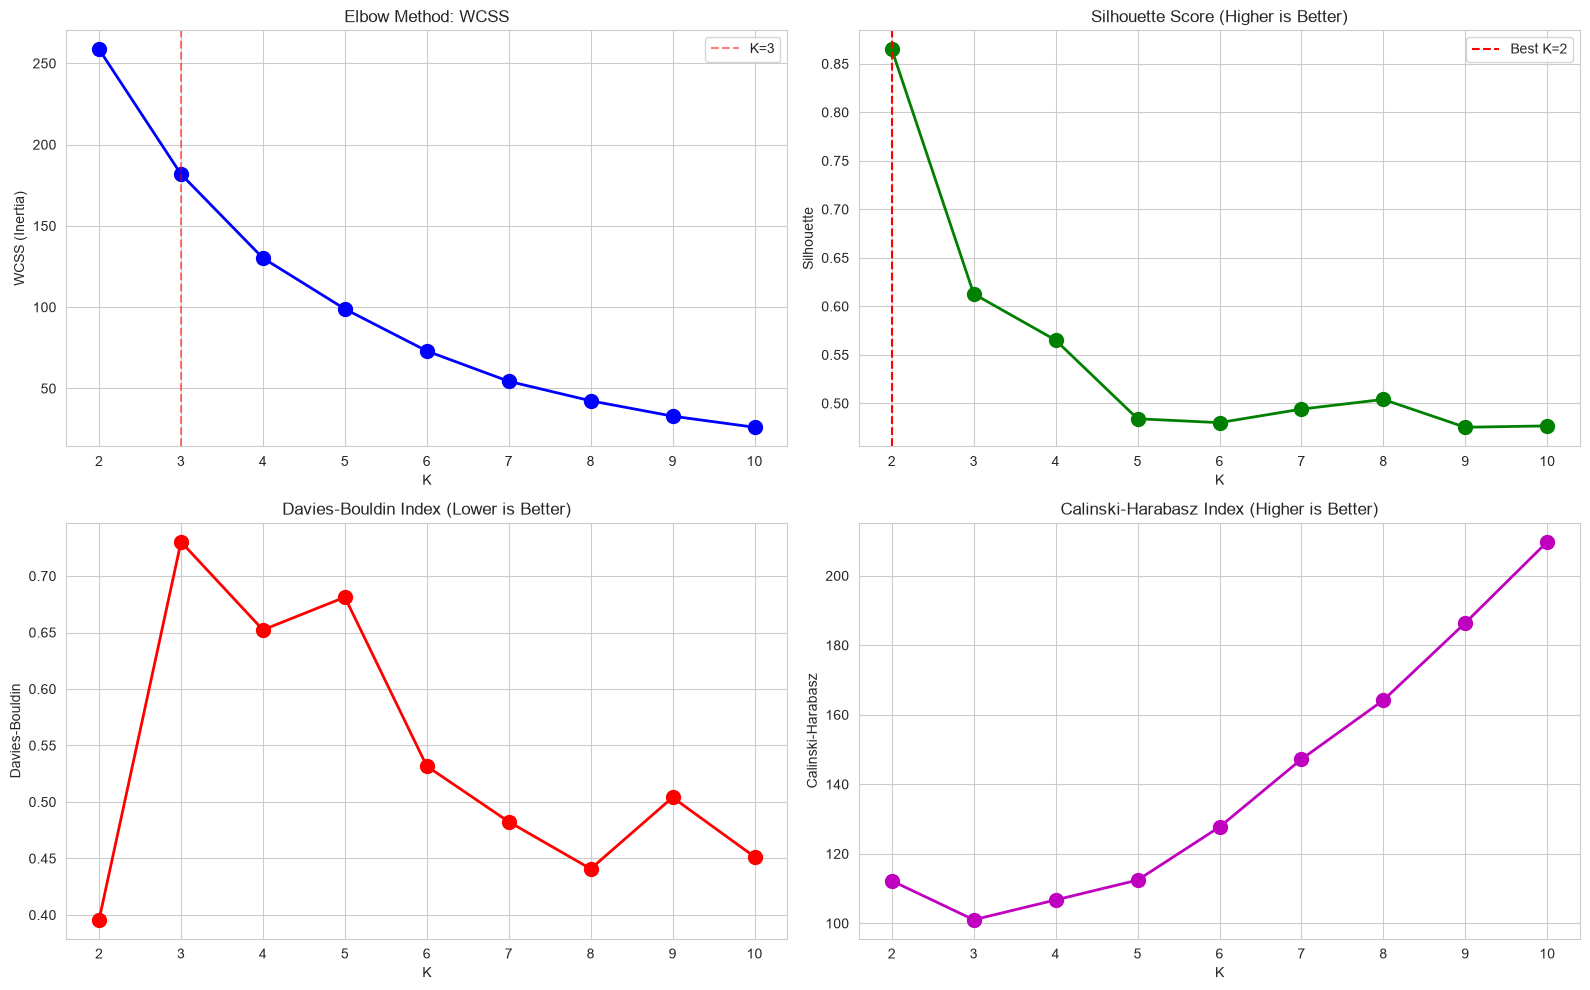

In [27]:
wcss, sil_scores, db_scores, ch_scores = [], [], [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_city_scaled)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_city_scaled, labels))
    db_scores.append(davies_bouldin_score(X_city_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_city_scaled, labels))

results_k = pd.DataFrame({"K": list(K_range), "WCSS": wcss, "Silhouette": sil_scores,
                          "Davies_Bouldin": db_scores, "Calinski_Harabasz": ch_scores})
print(results_k.round(4).to_string(index=False))

best_sil_k = int(results_k.loc[results_k["Silhouette"].idxmax(), "K"])
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].plot(results_k["K"], results_k["WCSS"], "bo-", linewidth=2, markersize=10)
axes[0, 0].set(title="Elbow Method: WCSS", xlabel="K", ylabel="WCSS (Inertia)")
axes[0, 0].axvline(x=3, color="red", linestyle="--", alpha=0.5, label="K=3")
axes[0, 0].legend()
axes[0, 1].plot(results_k["K"], results_k["Silhouette"], "go-", linewidth=2, markersize=10)
axes[0, 1].set(title="Silhouette Score (Higher is Better)", xlabel="K", ylabel="Silhouette")
axes[0, 1].axvline(x=best_sil_k, color="red", linestyle="--", label=f"Best K={best_sil_k}")
axes[0, 1].legend()
axes[1, 0].plot(results_k["K"], results_k["Davies_Bouldin"], "ro-", linewidth=2, markersize=10)
axes[1, 0].set(title="Davies-Bouldin Index (Lower is Better)", xlabel="K", ylabel="Davies-Bouldin")
axes[1, 1].plot(results_k["K"], results_k["Calinski_Harabasz"], "mo-", linewidth=2, markersize=10)
axes[1, 1].set(title="Calinski-Harabasz Index (Higher is Better)", xlabel="K", ylabel="Calinski-Harabasz")
plt.tight_layout()
save_fig("clustering_optimal_k.png")
plt.show()

## 6. Apply K-Means with the Chosen K

Cluster numbers (0, 1, 2) are arbitrary. The `Cluster_Name` column ranks the clusters by average cases: Epicenter (highest), Hotspot, Low-Burden.

In [28]:
kmeans_final = KMeans(n_clusters=K_OPTIMAL, init="k-means++", n_init=20, max_iter=300, random_state=42)
city_agg["Cluster"] = kmeans_final.fit_predict(X_city_scaled)

rank = city_agg.groupby("Cluster")["Total_Cases"].mean().rank(ascending=False).astype(int)
NAMES = {1: "Epicenter", 2: "Hotspot", 3: "Low-Burden"}
cluster_names = {c: NAMES[r] for c, r in rank.items()}
city_agg["Cluster_Name"] = city_agg["Cluster"].map(cluster_names)

print("Cluster distribution:")
print(city_agg.groupby(["Cluster", "Cluster_Name"]).size().to_string())

cluster_profile = city_agg.groupby("Cluster").agg(
    Cluster_Name=("Cluster_Name", "first"),
    Total_Cases_mean=("Total_Cases", "mean"), Total_Cases_sum=("Total_Cases", "sum"),
    Total_Deaths_mean=("Total_Deaths", "mean"), Total_Recovered_mean=("Total_Recovered", "mean"),
    CFR_mean=("CFR", "mean"), Recovery_Rate_mean=("Recovery_Rate", "mean"), N_Cities=("City", "count"))
print("\nCluster profiles:")
print(cluster_profile.round(2).to_string())

for c in range(K_OPTIMAL):
    print(f"\n--- Cluster {c} ({cluster_names[c]}), top 5 by cases ---")
    print(city_agg[city_agg["Cluster"] == c].nlargest(5, "Total_Cases")[["City", "Province", "Total_Cases", "Total_Deaths", "CFR"]].round(2).to_string(index=False))

Cluster distribution:
Cluster  Cluster_Name
0        Hotspot         95
1        Epicenter        2
2        Low-Burden      10

Cluster profiles:
        Cluster_Name  Total_Cases_mean  Total_Cases_sum  Total_Deaths_mean  Total_Recovered_mean  CFR_mean  Recovery_Rate_mean  N_Cities
Cluster                                                                                                                                 
0            Hotspot            271.37            25780               6.02                 77.01      0.99               33.57        95
1          Epicenter          28680.50            57361             540.00               8550.50      1.89               29.45         2
2         Low-Burden             82.00              820               7.50                 33.60      9.69               72.75        10

--- Cluster 0 (Hotspot), top 5 by cases ---
     City                    Province  Total_Cases  Total_Deaths  CFR
   Quetta                 Balochistan         5109   

## 7. Cluster Visualisation from Several Angles

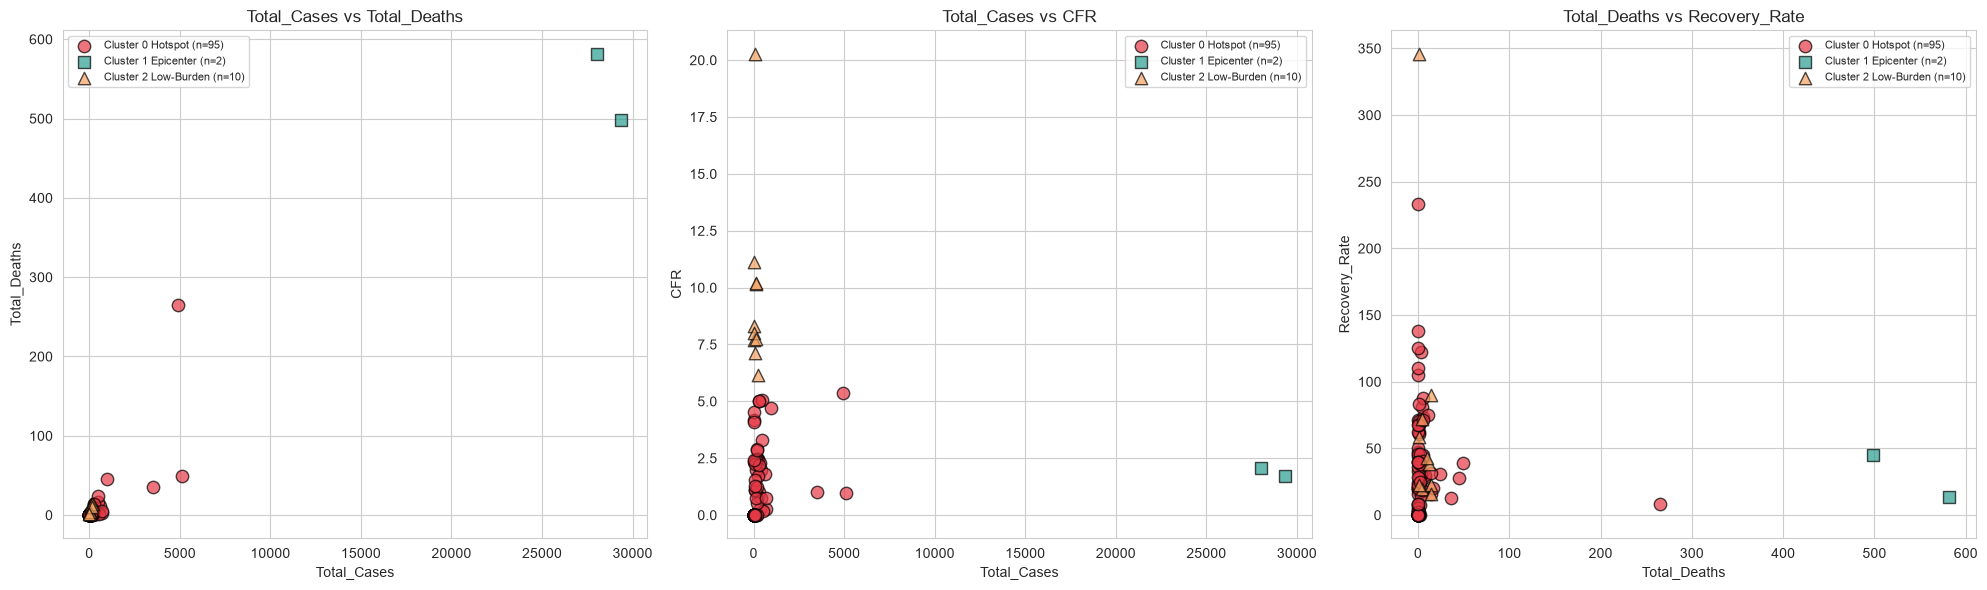

In [29]:
# Visualization 1: 2D scatter plots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (x_col, y_col) in zip(axes, [("Total_Cases", "Total_Deaths"), ("Total_Cases", "CFR"), ("Total_Deaths", "Recovery_Rate")]):
    for c in range(K_OPTIMAL):
        subset = city_agg[city_agg["Cluster"] == c]
        ax.scatter(subset[x_col], subset[y_col], c=colors[c], marker=markers[c], s=80, alpha=0.7, edgecolors="black",
                   label=f"Cluster {c} {cluster_names[c]} (n={len(subset)})")
    ax.set(xlabel=x_col, ylabel=y_col, title=f"{x_col} vs {y_col}")
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig("clustering_scatter_2d.png")
plt.show()

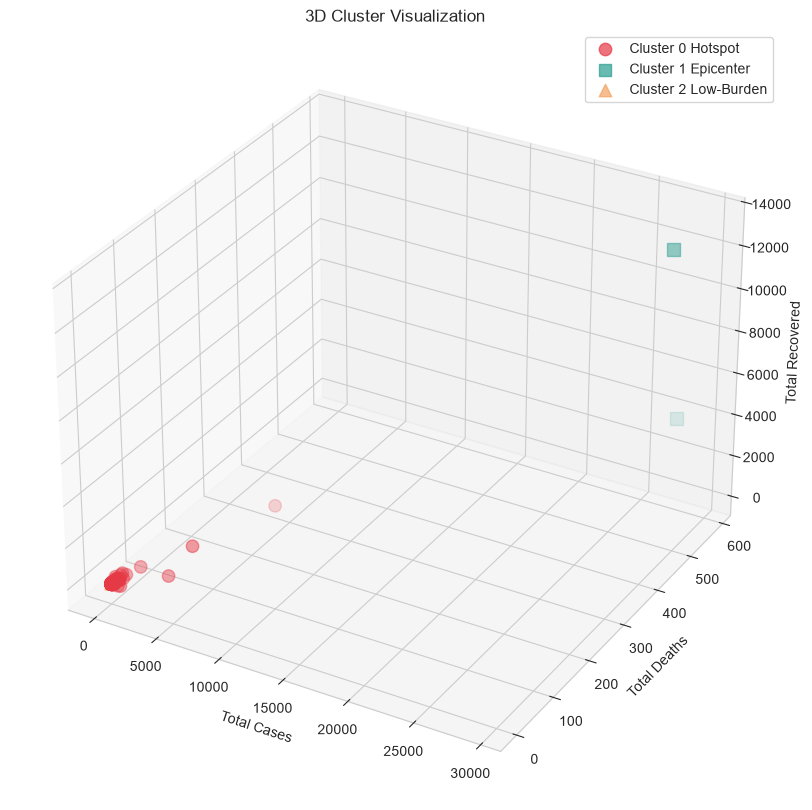

In [30]:
# Visualization 2: 3D scatter
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection="3d")
for c in range(K_OPTIMAL):
    subset = city_agg[city_agg["Cluster"] == c]
    ax.scatter(subset["Total_Cases"], subset["Total_Deaths"], subset["Total_Recovered"], c=colors[c], marker=markers[c],
               s=80, alpha=0.7, label=f"Cluster {c} {cluster_names[c]}")
ax.set(xlabel="Total Cases", ylabel="Total Deaths", zlabel="Total Recovered", title="3D Cluster Visualization")
ax.legend()
save_fig("clustering_scatter_3d.png")
plt.show()

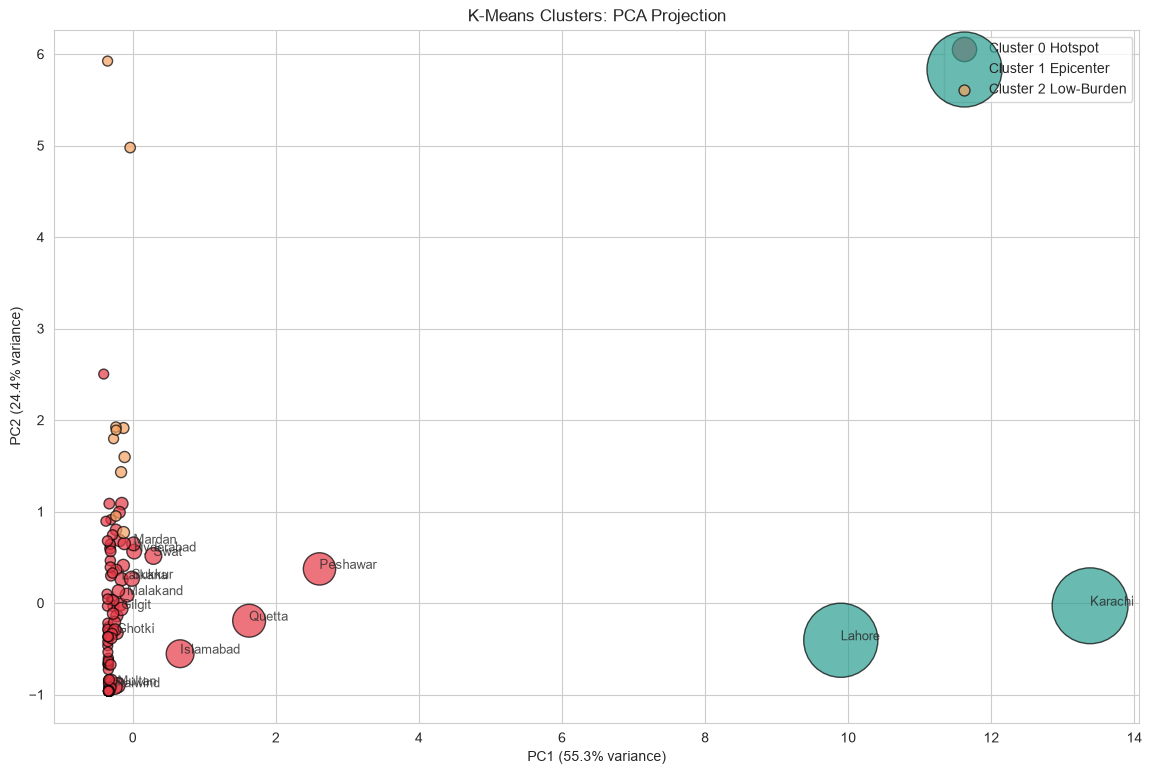

Total variance explained: 79.64%


In [31]:
# Visualization 3: PCA projection (5 features -> 2 components)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_city_scaled)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = city_agg["Cluster"].values
pca_df["City"] = city_agg["City"].values
pca_df["Cases"] = city_agg["Total_Cases"].values

fig, ax = plt.subplots(figsize=(14, 9))
for c in range(K_OPTIMAL):
    subset = pca_df[pca_df["Cluster"] == c]
    ax.scatter(subset["PC1"], subset["PC2"], c=colors[c], s=subset["Cases"] / 10 + 50, alpha=0.7, edgecolors="black",
               label=f"Cluster {c} {cluster_names[c]}")
for _, row in pca_df.nlargest(15, "Cases").iterrows():
    ax.annotate(row["City"], (row["PC1"], row["PC2"]), fontsize=9, alpha=0.8)
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)", title="K-Means Clusters: PCA Projection")
ax.legend()
save_fig("clustering_pca.png")
plt.show()
print(f"Total variance explained: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

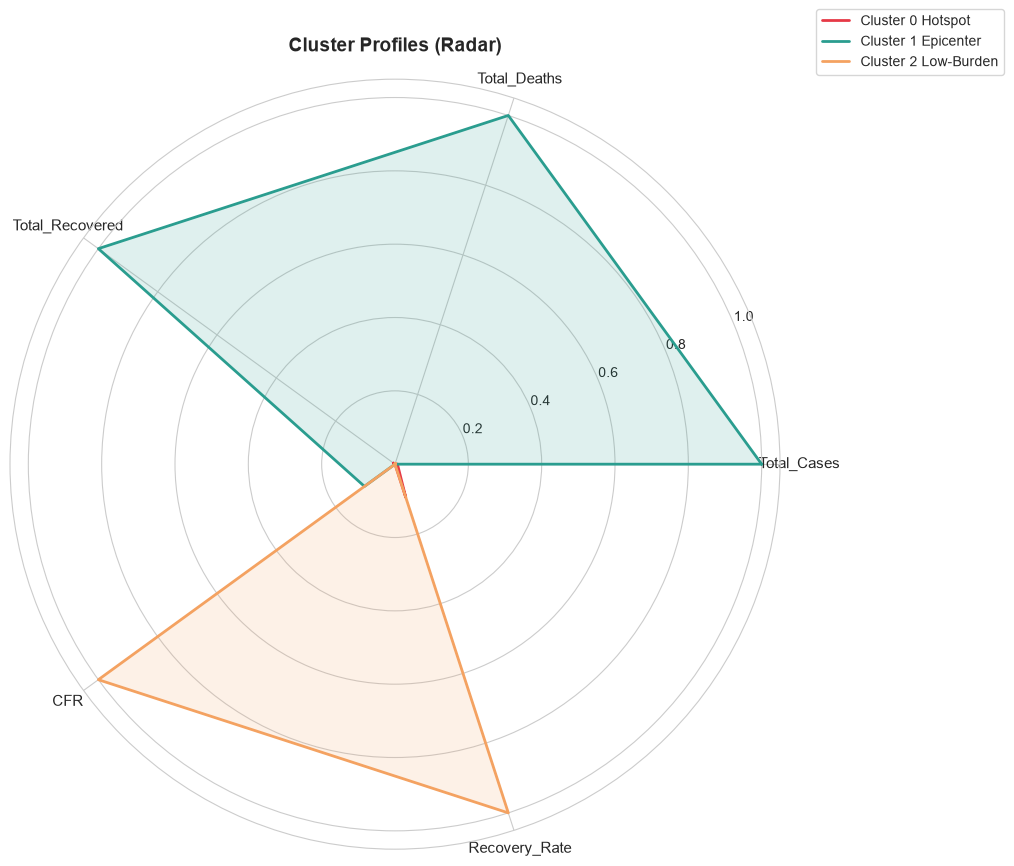

In [32]:
# Visualization 4: radar chart of cluster profiles
radar_features = features
radar_data = city_agg.groupby("Cluster")[radar_features].mean()
radar_norm = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min() + 1e-10)

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
angles = [n / len(radar_features) * 2 * pi for n in range(len(radar_features))]
angles += angles[:1]
for c in range(K_OPTIMAL):
    values = radar_norm.loc[c].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, color=colors[c], label=f"Cluster {c} {cluster_names[c]}")
    ax.fill(angles, values, alpha=0.15, color=colors[c])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_features, fontsize=11)
ax.set_title("Cluster Profiles (Radar)", fontsize=14, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
save_fig("clustering_radar.png")
plt.show()

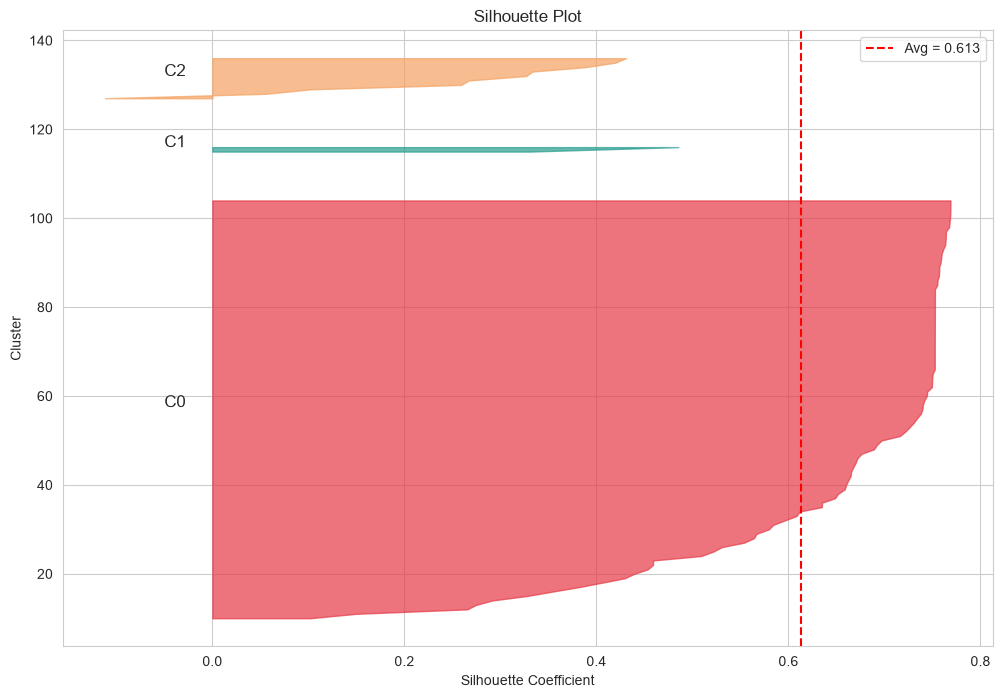

In [33]:
# Visualization 5: silhouette plot
silhouette_vals = silhouette_samples(X_city_scaled, city_agg["Cluster"])
avg_score = silhouette_score(X_city_scaled, city_agg["Cluster"])

fig, ax = plt.subplots(figsize=(12, 8))
y_lower = 10
for c in range(K_OPTIMAL):
    c_sil = np.sort(silhouette_vals[city_agg["Cluster"] == c])
    y_upper = y_lower + len(c_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil, facecolor=colors[c], edgecolor=colors[c], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * len(c_sil), f"C{c}", fontsize=12)
    y_lower = y_upper + 10
ax.axvline(avg_score, color="red", linestyle="--", label=f"Avg = {avg_score:.3f}")
ax.set(title="Silhouette Plot", xlabel="Silhouette Coefficient", ylabel="Cluster")
ax.legend()
save_fig("clustering_silhouette.png")
plt.show()

In [34]:
# Visualization 6: interactive 3D scatter (Plotly)
if HAS_PLOTLY:
    plot_df = city_agg.assign(Cluster_Label=city_agg["Cluster"].astype(str) + " " + city_agg["Cluster_Name"])
    fig = px.scatter_3d(plot_df, x="Total_Cases", y="Total_Deaths", z="Total_Recovered", color="Cluster_Label",
                        hover_name="City", hover_data=["Province", "CFR", "Recovery_Rate"],
                        title="Interactive 3D K-Means Clusters", color_discrete_sequence=colors)
    if SAVE_OUTPUTS:
        fig.write_html(out("clustering_3d_interactive.html"), include_plotlyjs="cdn")
    try:
        fig.show()
    except ValueError as e:
        print("Plotly chart could not be shown inside the notebook:", e)
        print("Run 'pip install nbformat', or open outputs/clustering/clustering_3d_interactive.html in your browser.")
else:
    print("plotly is not installed in this environment: run 'pip install plotly' to enable the interactive chart.")

Plotly chart could not be shown inside the notebook: Mime type rendering requires nbformat>=4.2.0 but it is not installed
Run 'pip install nbformat', or open outputs/clustering/clustering_3d_interactive.html in your browser.


## 8. Cluster Quality Metrics

In [35]:
sil = silhouette_score(X_city_scaled, city_agg["Cluster"])
db = davies_bouldin_score(X_city_scaled, city_agg["Cluster"])
ch = calinski_harabasz_score(X_city_scaled, city_agg["Cluster"])
inertia = kmeans_final.inertia_

print("=" * 60)
print("CLUSTERING QUALITY METRICS")
print("=" * 60)
print(f"Silhouette Score:       {sil:.4f}  (range -1 to 1, higher is better)")
print(f"Davies-Bouldin Index:   {db:.4f}  (lower is better)")
print(f"Calinski-Harabasz:      {ch:.2f}  (higher is better)")
print(f"Inertia (WCSS):         {inertia:.2f}")

CLUSTERING QUALITY METRICS
Silhouette Score:       0.6128  (range -1 to 1, higher is better)
Davies-Bouldin Index:   0.7302  (lower is better)
Calinski-Harabasz:      101.02  (higher is better)
Inertia (WCSS):         181.80


## 9. Province-Level Clustering

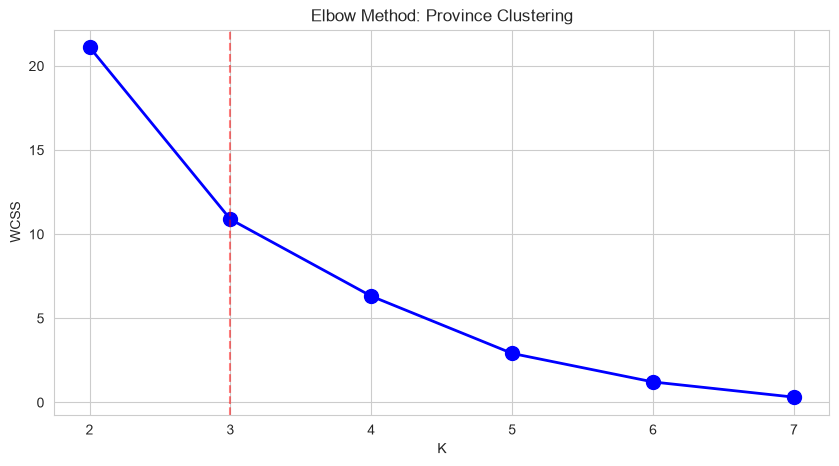

Province clusters:
                           Province  Total_Cases  CFR  Cluster_Prov
                 Khyber Pakhtunkhwa        10259 4.61             0
                             Punjab        31096 1.91             0
                 Azad Jammu Kashmir          285 2.11             1
                        Balochistan         5125 0.96             1
Federally Administered Tribal Areas           53 1.89             1
                   Gilgit-Baltistan          786 3.05             1
        Islamabad Capital Territory         3523 1.02             1
                              Sindh        32858 1.66             2


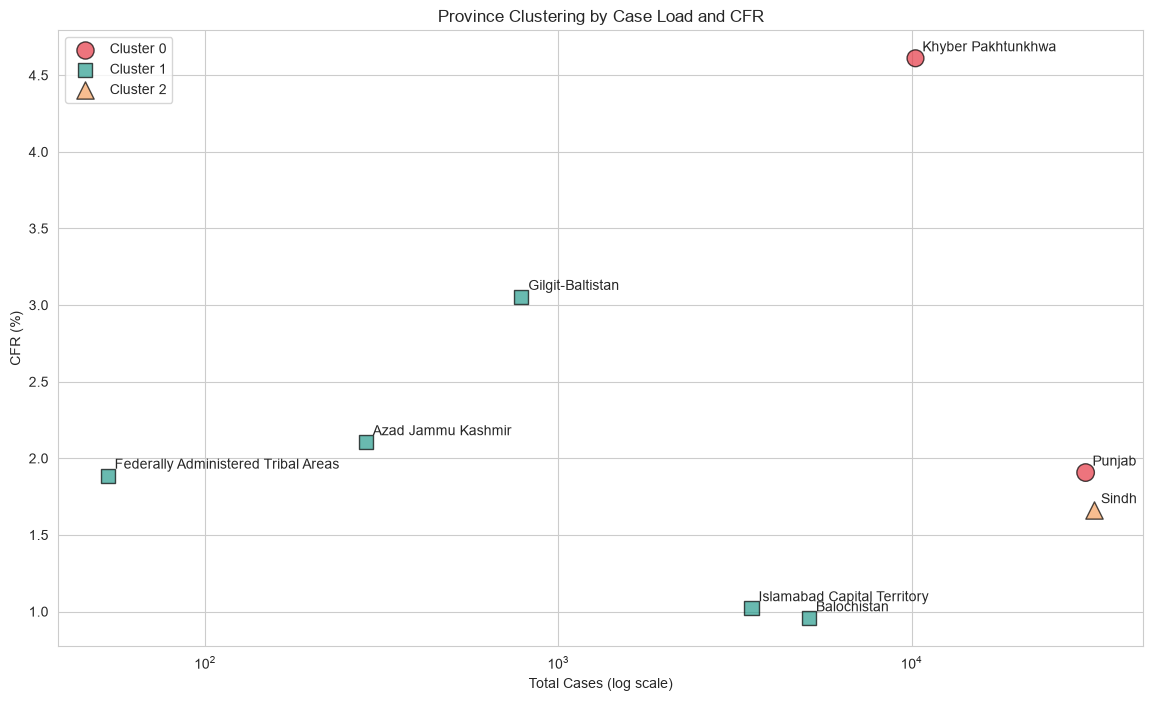

In [36]:
province_features = ["Total_Cases", "Total_Deaths", "Total_Recovered", "CFR", "Recovery_Rate"]
X_prov_scaled = StandardScaler().fit_transform(province_agg[province_features])

# Elbow for provinces (K must be smaller than the number of provinces)
k_prov = list(range(2, min(8, len(province_agg))))
wcss_prov = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_prov_scaled).inertia_ for k in k_prov]
plt.figure(figsize=(10, 5))
plt.plot(k_prov, wcss_prov, "bo-", linewidth=2, markersize=10)
plt.title("Elbow Method: Province Clustering")
plt.xlabel("K"); plt.ylabel("WCSS")
plt.axvline(x=3, color="red", linestyle="--", alpha=0.5)
save_fig("clustering_province_elbow.png")
plt.show()

km_prov = KMeans(n_clusters=3, n_init=20, random_state=42)
province_agg["Cluster_Prov"] = km_prov.fit_predict(X_prov_scaled)
print("Province clusters:")
print(province_agg[["Province", "Total_Cases", "CFR", "Cluster_Prov"]].sort_values("Cluster_Prov").round(2).to_string(index=False))

plt.figure(figsize=(14, 8))
for c in range(3):
    subset = province_agg[province_agg["Cluster_Prov"] == c]
    plt.scatter(subset["Total_Cases"], subset["CFR"], s=subset["Total_Deaths"] / 10 + 100, c=colors[c], marker=markers[c],
                alpha=0.7, edgecolors="black", label=f"Cluster {c}")
for _, row in province_agg.iterrows():
    plt.annotate(row["Province"], (row["Total_Cases"], row["CFR"]), xytext=(5, 5), textcoords="offset points", fontsize=10)
plt.xscale("log")
plt.xlabel("Total Cases (log scale)"); plt.ylabel("CFR (%)")
plt.title("Province Clustering by Case Load and CFR")
plt.legend()
save_fig("clustering_province_scatter.png")
plt.show()

## 10. Time-Period Clustering (Weekly Transmission Phases)

Weekly WCSS for K = 2..7: [16.64, 10.26, 5.13, 2.83, 1.73, 1.02]

Weekly phases:
 Week  Cases  Deaths  Active  Phase  Phase_Name
    9      5       0     2.5      0 Early / low
   10      2       0     0.3      0 Early / low
   11     57       1     9.0      0 Early / low
   12    708       4    99.9      0 Early / low
   13    830      14   110.9      0 Early / low
   14   1309      29   156.9      0 Early / low
   15   2273      45   204.4      0 Early / low
   16   3185      75   351.9      0 Early / low
   17   4908      99   583.0      0 Early / low
   18   6617     139   863.6      2      Growth
   19  10588     202  1433.4      2      Growth
   20  11056     246  1118.7      2      Growth
   21  13860     267  1104.1      1        Peak
   22  15796     378   979.1      1        Peak
   23  12791     229  2799.7      2      Growth


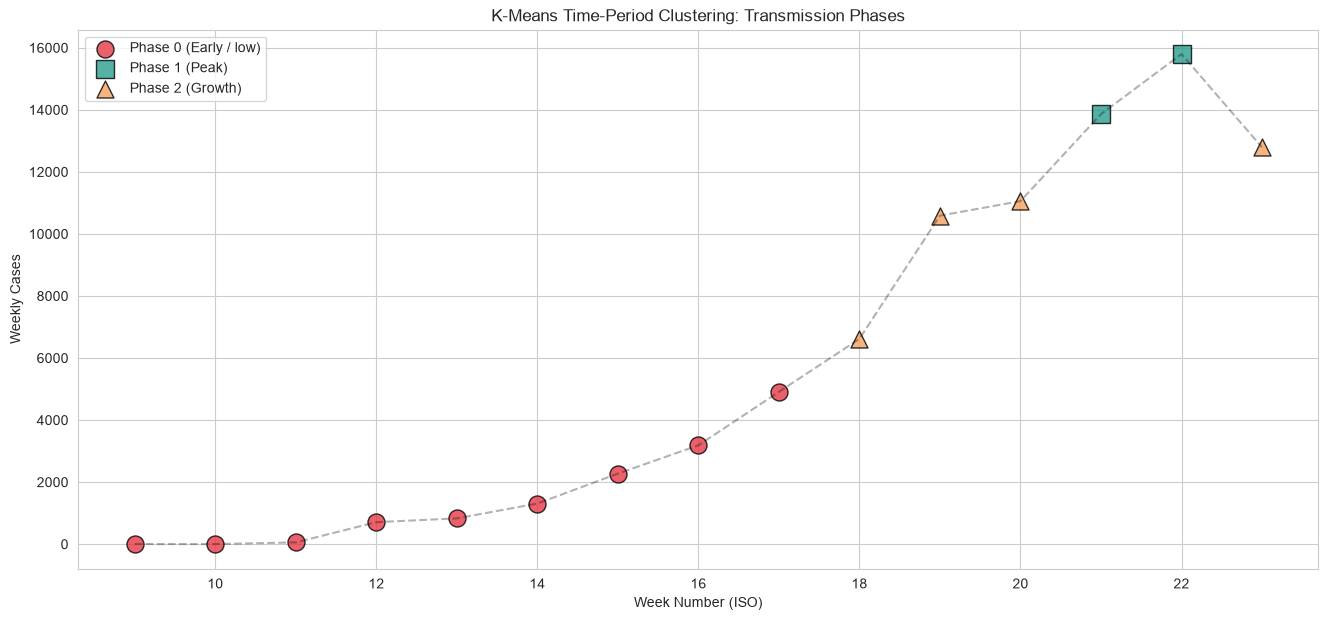

In [37]:
weekly_features = ["Cases", "Deaths", "Recovered", "Active"]
X_week_scaled = StandardScaler().fit_transform(weekly[weekly_features])

wcss_week = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_week_scaled).inertia_ for k in range(2, 8)]
print("Weekly WCSS for K = 2..7:", [round(w, 2) for w in wcss_week])

km_week = KMeans(n_clusters=3, n_init=20, random_state=42)
weekly["Phase"] = km_week.fit_predict(X_week_scaled)
phase_rank = weekly.groupby("Phase")["Cases"].mean().rank(ascending=True).astype(int)       # 1 = lowest activity
PHASE_NAMES = {1: "Early / low", 2: "Growth", 3: "Peak"}
weekly["Phase_Name"] = weekly["Phase"].map({p: PHASE_NAMES[r] for p, r in phase_rank.items()})

print("\nWeekly phases:")
print(weekly[["Week", "Cases", "Deaths", "Active", "Phase", "Phase_Name"]].round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(16, 7))
for c in range(3):
    subset = weekly[weekly["Phase"] == c]
    ax.scatter(subset["Week"], subset["Cases"], c=colors[c], s=150, marker=markers[c], alpha=0.8, edgecolors="black",
               label=f"Phase {c} ({subset['Phase_Name'].iloc[0] if len(subset) else ''})")
ax.plot(weekly["Week"], weekly["Cases"], "k--", alpha=0.3)
ax.set(xlabel="Week Number (ISO)", ylabel="Weekly Cases", title="K-Means Time-Period Clustering: Transmission Phases")
ax.legend()
save_fig("clustering_temporal.png")
plt.show()

## 11. Travel-History Clustering

In [38]:
travel_agg = df.groupby("Travel_history").agg(
    Total_Cases=("Cases", "sum"), Total_Deaths=("Deaths", "sum"), Records=("Cases", "count"),
    Avg_Cases_Per_Record=("Cases", "mean")).reset_index()
travel_agg["CFR"] = np.where(travel_agg["Total_Cases"] > 0, travel_agg["Total_Deaths"] / travel_agg["Total_Cases"] * 100, 0)

n_travel_all = len(travel_agg)
travel_agg = travel_agg[travel_agg["Records"] >= 3].reset_index(drop=True)          # keep categories with at least 3 records
print(f"Travel categories with >= 3 records: {len(travel_agg)} of {n_travel_all}")

travel_features = ["Total_Cases", "Total_Deaths", "Records", "Avg_Cases_Per_Record", "CFR"]
X_travel_scaled = StandardScaler().fit_transform(travel_agg[travel_features])
km_travel = KMeans(n_clusters=3, n_init=20, random_state=42)
travel_agg["Cluster_Travel"] = km_travel.fit_predict(X_travel_scaled)

print("\nTravel history clusters:")
print(travel_agg[["Travel_history", "Total_Cases", "Records", "CFR", "Cluster_Travel"]].sort_values("Cluster_Travel").round(2).to_string(index=False))

Travel categories with >= 3 records: 8 of 15

Travel history clusters:
         Travel_history  Total_Cases  Records  CFR  Cluster_Travel
                Unknown        22659      158 2.00               0
 Local - Social Contact        58918     2413 2.13               1
            Afghanistan           70        5 0.00               2
International Passenger           38        5 0.00               2
          Iran / Taftan         1053       88 1.04               2
                   Jail          107        5 0.00               2
       Tableeghi Jamaat         1115       23 0.45               2
                     UK            5        3 0.00               2


## 12. Hierarchical Clustering (Alternative to K-Means)

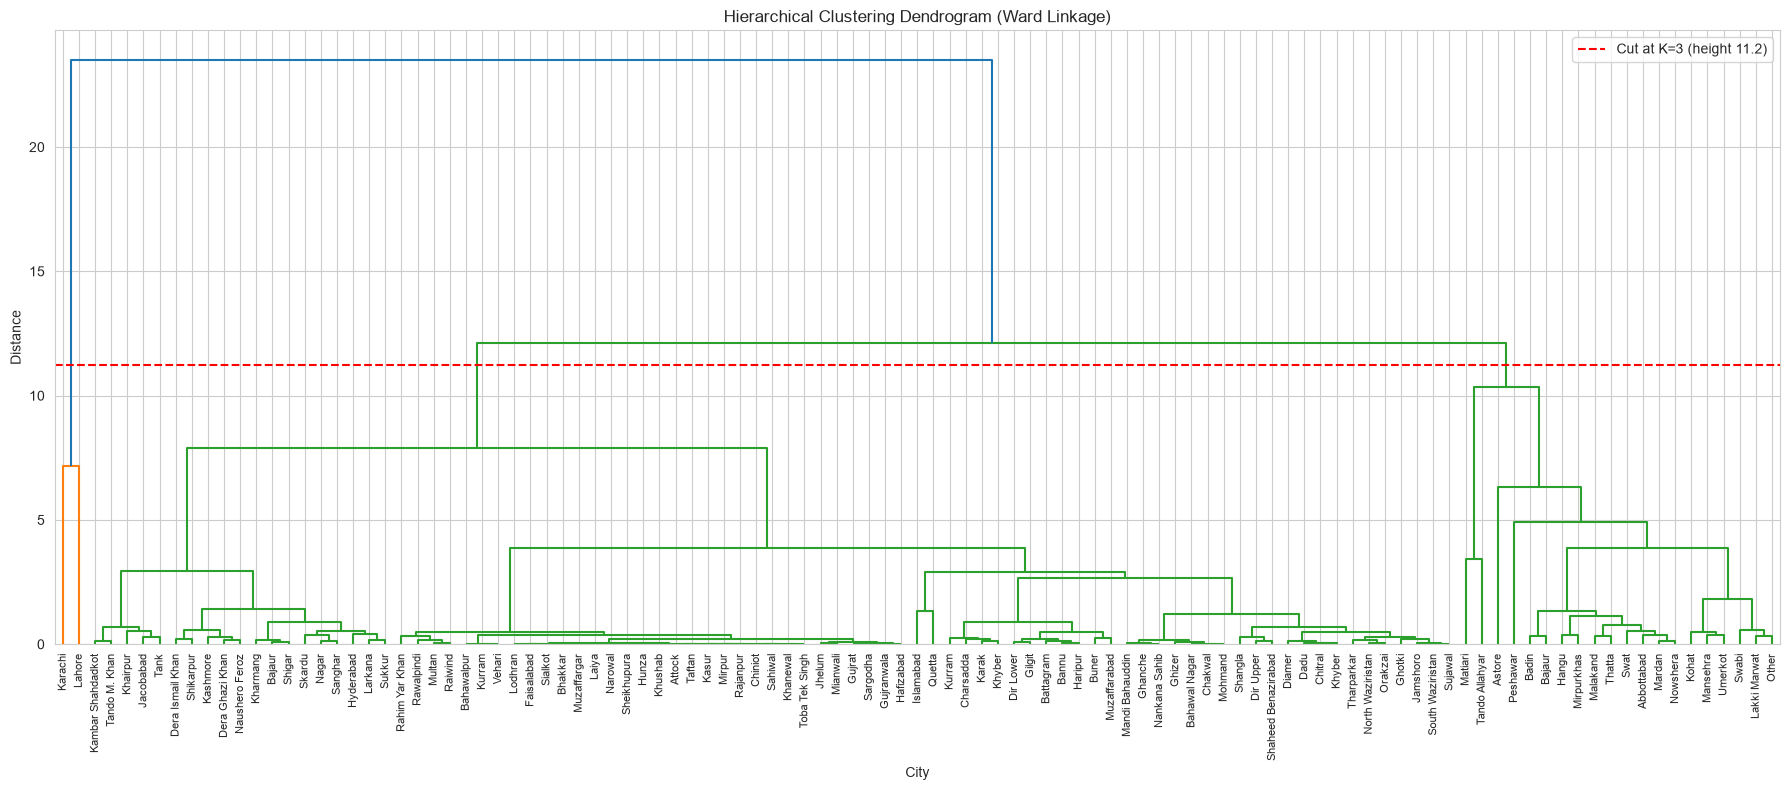

Agreement between K-Means (rows) and Hierarchical (columns):
Cluster_Hier   0  1   2
Cluster                
0             10  0  85
1              0  2   0
2             10  0   0
Adjusted Rand index: 0.585


In [39]:
link = linkage(X_city_scaled, method="ward")
cut_height = (link[-3, 2] + link[-2, 2]) / 2          # height that leaves exactly 3 clusters

fig, ax = plt.subplots(figsize=(18, 8))
dendrogram(link, labels=city_agg["City"].values, leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set(title="Hierarchical Clustering Dendrogram (Ward Linkage)", xlabel="City", ylabel="Distance")
ax.axhline(y=cut_height, color="red", linestyle="--", label=f"Cut at K=3 (height {cut_height:.1f})")
ax.legend()
plt.tight_layout()
save_fig("clustering_dendrogram.png")
plt.show()

agg_model = AgglomerativeClustering(n_clusters=3, linkage="ward")
city_agg["Cluster_Hier"] = agg_model.fit_predict(X_city_scaled)
agreement = pd.crosstab(city_agg["Cluster"], city_agg["Cluster_Hier"])
print("Agreement between K-Means (rows) and Hierarchical (columns):")
print(agreement.to_string())
print("Adjusted Rand index:", round(adjusted_rand_score(city_agg["Cluster"], city_agg["Cluster_Hier"]), 3))

## 13. Optimal K: Consensus of Several Metrics

In [40]:
print("=" * 70)
print("OPTIMAL K SELECTION: MULTIPLE METHODS")
print("=" * 70)
print(results_k.round(4).to_string(index=False))

best_k_sil = int(results_k.loc[results_k["Silhouette"].idxmax(), "K"])
best_k_db = int(results_k.loc[results_k["Davies_Bouldin"].idxmin(), "K"])
best_k_ch = int(results_k.loc[results_k["Calinski_Harabasz"].idxmax(), "K"])
print(f"\nBest K by Silhouette:        {best_k_sil}")
print(f"Best K by Davies-Bouldin:    {best_k_db}")
print(f"Best K by Calinski-Harabasz: {best_k_ch}")

votes = Counter([best_k_sil, best_k_db, best_k_ch])
consensus_k, n_votes = votes.most_common(1)[0]
print(f"\nConsensus K: {consensus_k} ({n_votes} of 3 metrics)" if n_votes > 1 else
      f"\nNo majority: the three metrics disagree {sorted(votes)}. Choose K from the elbow plot and the interpretation, not from one metric.")
print(f"K used for the final model: {K_OPTIMAL}")

OPTIMAL K SELECTION: MULTIPLE METHODS
 K     WCSS  Silhouette  Davies_Bouldin  Calinski_Harabasz
 2 258.5956      0.8649          0.3957           112.2311
 3 181.8030      0.6128          0.7302           101.0228
 4 130.2149      0.5651          0.6523           106.7283
 5  98.9083      0.4841          0.6813           112.4308
 6  73.0648      0.4801          0.5317           127.7098
 7  54.4091      0.4941          0.4825           147.2152
 8  42.4287      0.5041          0.4408           164.1901
 9  32.9862      0.4754          0.5040           186.4315
10  26.1469      0.4768          0.4515           209.7496

Best K by Silhouette:        2
Best K by Davies-Bouldin:    2
Best K by Calinski-Harabasz: 10

Consensus K: 2 (2 of 3 metrics)
K used for the final model: 3


## 14. Export Results

In [41]:
if SAVE_OUTPUTS:
    centroids_df = pd.DataFrame(kmeans_final.cluster_centers_, columns=features,
                                index=[f"Cluster_{i}" for i in range(K_OPTIMAL)])
    with pd.ExcelWriter(out("Clustering_Report.xlsx"), engine="openpyxl") as writer:
        df.assign(Date=df["Date"].dt.date).to_excel(writer, sheet_name="Clean_Data", index=False)
        city_agg.to_excel(writer, sheet_name="City_Aggregates", index=False)
        province_agg.to_excel(writer, sheet_name="Province_Aggregates", index=False)
        travel_agg.to_excel(writer, sheet_name="Travel_Aggregates", index=False)
        daily.assign(Date=daily["Date"].dt.date).to_excel(writer, sheet_name="Daily", index=False)
        weekly.to_excel(writer, sheet_name="Weekly", index=False)
        city_agg[["City", "Province", "Total_Cases", "Total_Deaths", "Total_Recovered", "CFR", "Cluster", "Cluster_Name"]].to_excel(
            writer, sheet_name="City_Clusters", index=False)
        province_agg[["Province", "Total_Cases", "Total_Deaths", "CFR", "Cluster_Prov"]].to_excel(writer, sheet_name="Province_Clusters", index=False)
        travel_agg[["Travel_history", "Total_Cases", "Records", "CFR", "Cluster_Travel"]].to_excel(writer, sheet_name="Travel_Clusters", index=False)
        results_k.to_excel(writer, sheet_name="Optimal_K", index=False)
        centroids_df.to_excel(writer, sheet_name="Centroids")
        cluster_profile.to_excel(writer, sheet_name="Cluster_Profiles")
    city_agg[["City", "Province", "Cluster", "Cluster_Name"]].to_csv(out("city_clusters.csv"), index=False)
    province_agg[["Province", "Cluster_Prov"]].to_csv(out("province_clusters.csv"), index=False)
    print("Exported:", out("Clustering_Report.xlsx").name, "| city_clusters.csv | province_clusters.csv")
    print("Folder  :", OUTD)
else:
    print("SAVE_OUTPUTS is False: nothing exported.")

Exported: Clustering_Report.xlsx | city_clusters.csv | province_clusters.csv
Folder  : D:\DA projects\Covid-19-portfolio\outputs\clustering


## 15. Interpreting the Results (computed from your data)

In [42]:
print("=" * 70)
print("CITY CLUSTERS (K = 3)")
print("=" * 70)
actions = {"Epicenter": "maximum hospital capacity, strictest measures",
           "Hotspot": "targeted testing and contact tracing",
           "Low-Burden": "awareness campaigns, prevent growth into hotspots"}
total_cases = city_agg["Total_Cases"].sum()
for c in sorted(cluster_names, key=lambda x: {"Epicenter": 0, "Hotspot": 1, "Low-Burden": 2}[cluster_names[x]]):
    g = city_agg[city_agg["Cluster"] == c]
    top = ", ".join(g.nlargest(5, "Total_Cases")["City"])
    print(f"\nCluster {c} - {cluster_names[c]}: {len(g)} cities, {g['Total_Cases'].sum() / total_cases:.0%} of cases")
    print(f"  average {g['Total_Cases'].mean():,.0f} cases per city | CFR {g['Total_Deaths'].sum() / max(g['Total_Cases'].sum(), 1) * 100:.2f}% | top: {top}")
    print(f"  suggested focus: {actions[cluster_names[c]]}")

print("\n" + "=" * 70)
print("WEEKLY PHASES")
print("=" * 70)
for name in ["Early / low", "Growth", "Peak"]:
    g = weekly[weekly["Phase_Name"] == name]
    if len(g):
        print(f"{name:<12}: weeks {', '.join(map(str, g['Week']))} | average {g['Cases'].mean():,.0f} cases per week")
print("Note: the first week (26 Feb to 1 Mar) and the last week (1 to 3 Jun) are partial weeks, so their totals are lower; see Days_in_Week.")

print("\n" + "=" * 70)
print("PROVINCES AND TRAVEL HISTORY")
print("=" * 70)
for c in range(3):
    print(f"Province cluster {c}:", ", ".join(province_agg.loc[province_agg["Cluster_Prov"] == c, "Province"]))
for c in range(3):
    print(f"Travel cluster {c}:", ", ".join(travel_agg.loc[travel_agg["Cluster_Travel"] == c, "Travel_history"]))

CITY CLUSTERS (K = 3)

Cluster 1 - Epicenter: 2 cities, 68% of cases
  average 28,680 cases per city | CFR 1.88% | top: Karachi, Lahore
  suggested focus: maximum hospital capacity, strictest measures

Cluster 0 - Hotspot: 95 cities, 31% of cases
  average 271 cases per city | CFR 2.22% | top: Quetta, Peshawar, Islamabad, Swat, Multan
  suggested focus: targeted testing and contact tracing

Cluster 2 - Low-Burden: 10 cities, 1% of cases
  average 82 cases per city | CFR 9.15% | top: Bajaur, Mansehra, Swabi, Kohat, Astore
  suggested focus: awareness campaigns, prevent growth into hotspots

WEEKLY PHASES
Early / low : weeks 9, 10, 11, 12, 13, 14, 15, 16, 17 | average 1,475 cases per week
Growth      : weeks 18, 19, 20, 23 | average 10,263 cases per week
Peak        : weeks 21, 22 | average 14,828 cases per week
Note: the first week (26 Feb to 1 Mar) and the last week (1 to 3 Jun) are partial weeks, so their totals are lower; see Days_in_Week.

PROVINCES AND TRAVEL HISTORY
Province clust

## 16. Complete Visual Dashboard

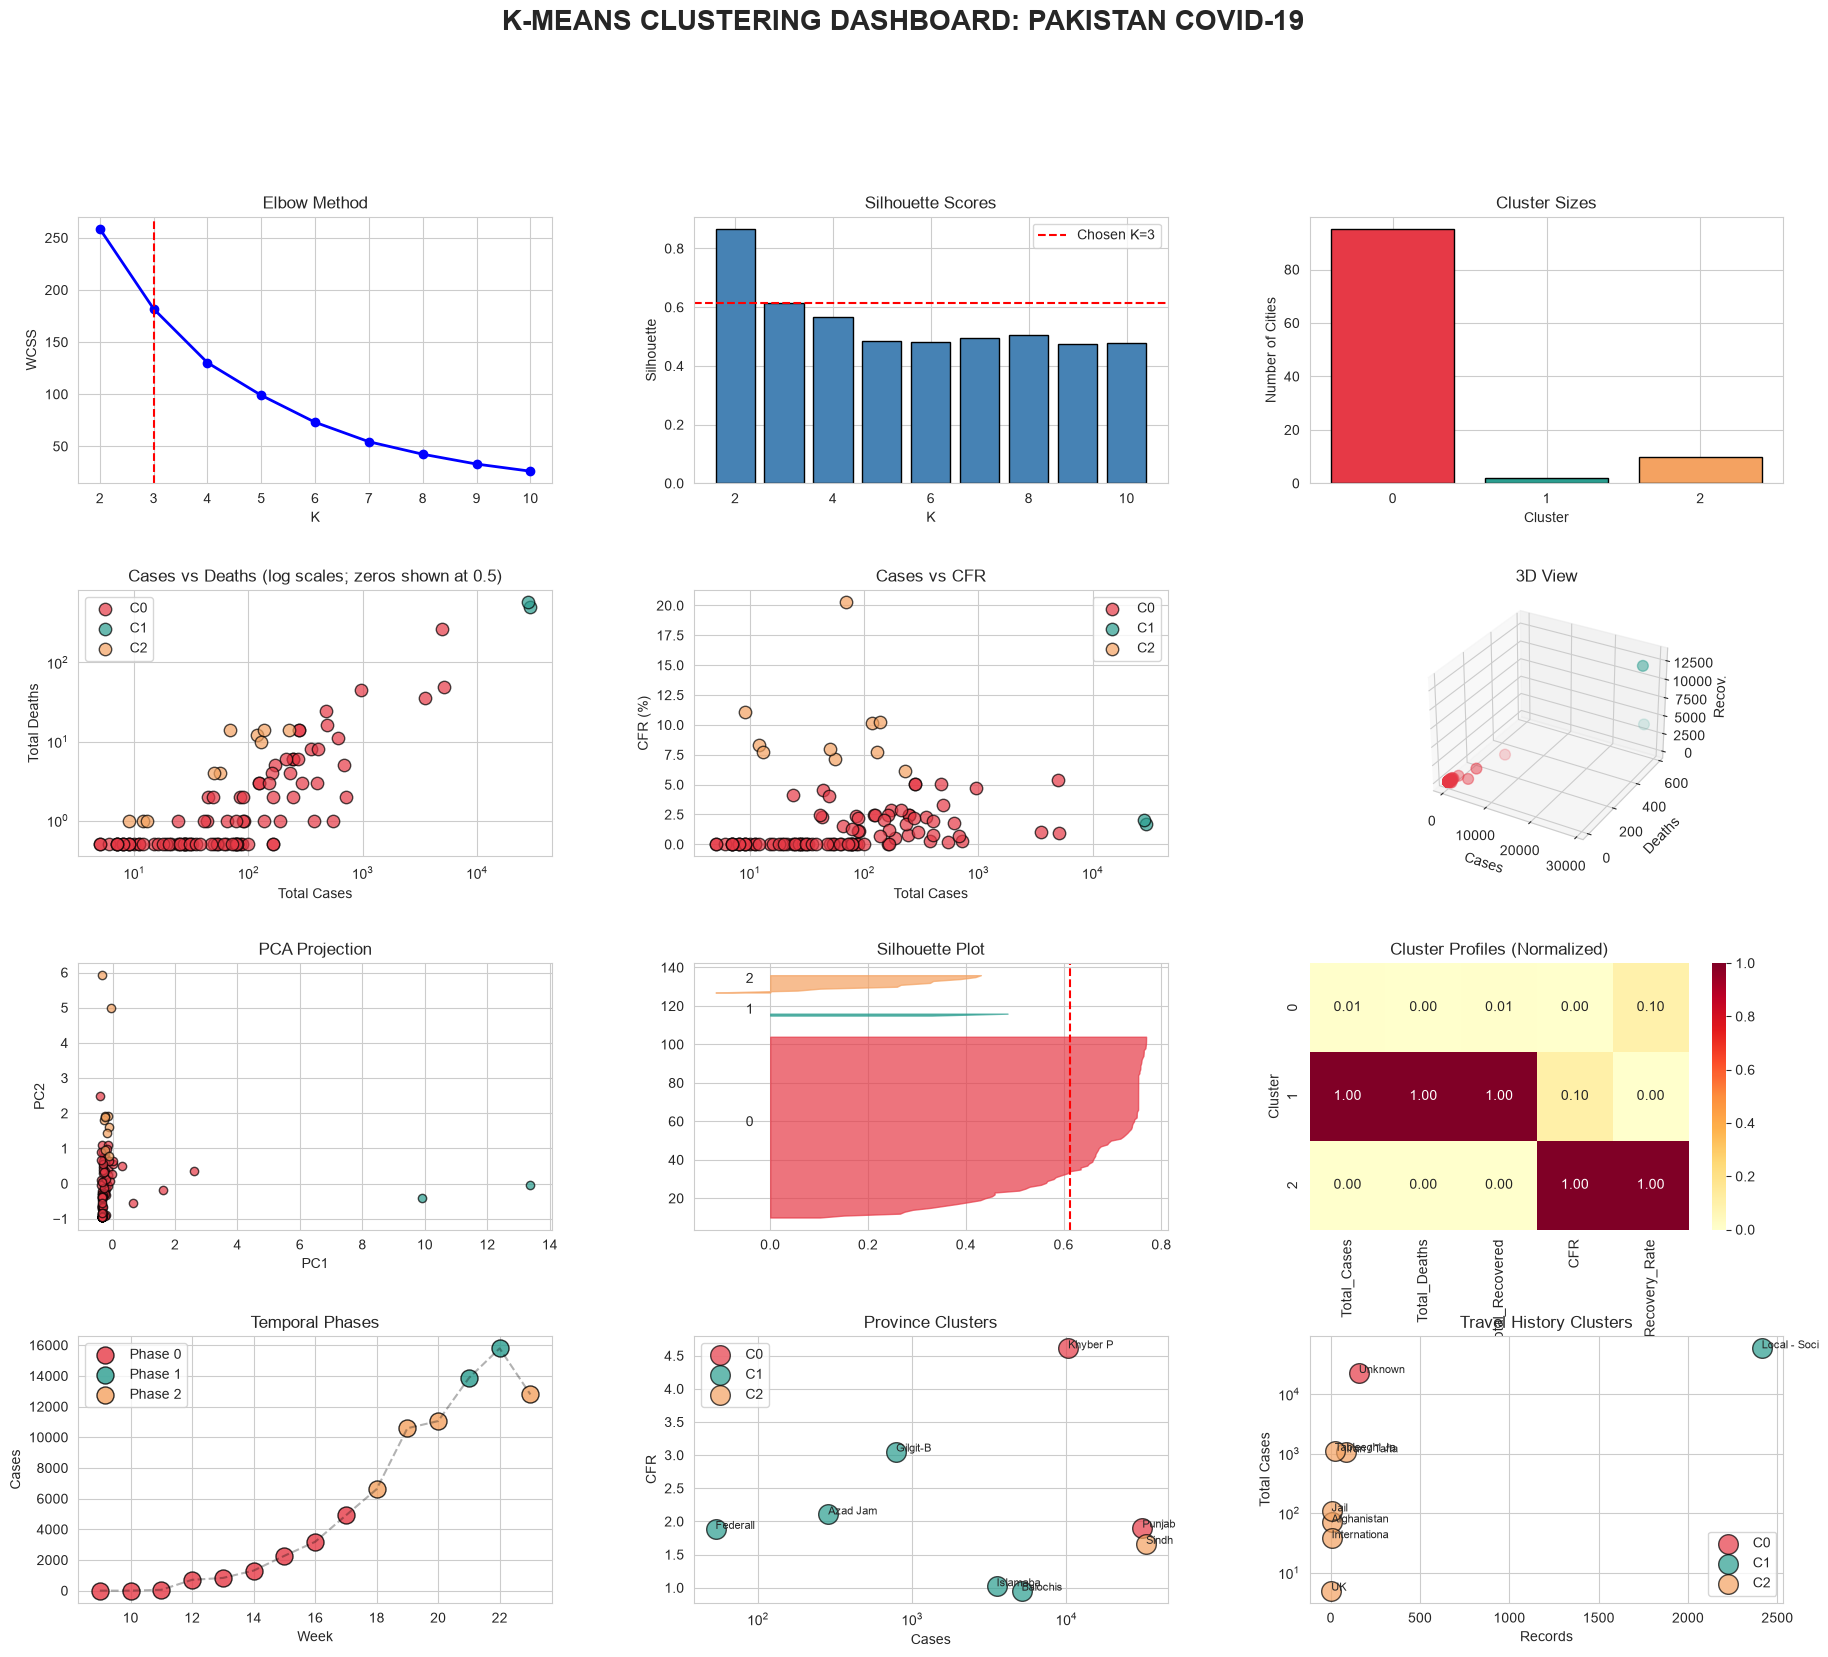

In [43]:
fig = plt.figure(figsize=(22, 18))
gs = fig.add_gridspec(4, 3, hspace=0.4, wspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(results_k["K"], results_k["WCSS"], "bo-", linewidth=2)
ax1.axvline(x=K_OPTIMAL, color="red", linestyle="--")
ax1.set(title="Elbow Method", xlabel="K", ylabel="WCSS")

ax2 = fig.add_subplot(gs[0, 1])
ax2.bar(results_k["K"], results_k["Silhouette"], color="steelblue", edgecolor="black")
ax2.axhline(y=sil, color="red", linestyle="--", label=f"Chosen K={K_OPTIMAL}")
ax2.set(title="Silhouette Scores", xlabel="K", ylabel="Silhouette")
ax2.legend()

ax3 = fig.add_subplot(gs[0, 2])
sizes = city_agg["Cluster"].value_counts().sort_index()
ax3.bar(sizes.index, sizes.values, color=colors, edgecolor="black")
ax3.set(title="Cluster Sizes", xlabel="Cluster", ylabel="Number of Cities")
ax3.set_xticks(sizes.index)

ax4 = fig.add_subplot(gs[1, 0])
for c in range(K_OPTIMAL):
    s = city_agg[city_agg["Cluster"] == c]
    ax4.scatter(s["Total_Cases"].clip(lower=0.5), s["Total_Deaths"].clip(lower=0.5), c=colors[c], s=80, alpha=0.7, edgecolors="black", label=f"C{c}")
ax4.set_xscale("log"); ax4.set_yscale("log")
ax4.set(title="Cases vs Deaths (log scales; zeros shown at 0.5)", xlabel="Total Cases", ylabel="Total Deaths")
ax4.legend()

ax5 = fig.add_subplot(gs[1, 1])
for c in range(K_OPTIMAL):
    s = city_agg[city_agg["Cluster"] == c]
    ax5.scatter(s["Total_Cases"], s["CFR"], c=colors[c], s=80, alpha=0.7, edgecolors="black", label=f"C{c}")
ax5.set_xscale("log")
ax5.set(title="Cases vs CFR", xlabel="Total Cases", ylabel="CFR (%)")
ax5.legend()

ax6 = fig.add_subplot(gs[1, 2], projection="3d")
for c in range(K_OPTIMAL):
    s = city_agg[city_agg["Cluster"] == c]
    ax6.scatter(s["Total_Cases"], s["Total_Deaths"], s["Total_Recovered"], c=colors[c], s=60, alpha=0.7)
ax6.set(title="3D View", xlabel="Cases", ylabel="Deaths", zlabel="Recov.")

ax7 = fig.add_subplot(gs[2, 0])
for c in range(K_OPTIMAL):
    s = pca_df[pca_df["Cluster"] == c]
    ax7.scatter(s["PC1"], s["PC2"], c=colors[c], alpha=0.7, edgecolors="black")
ax7.set(title="PCA Projection", xlabel="PC1", ylabel="PC2")

ax8 = fig.add_subplot(gs[2, 1])
y_lower = 10
for c in range(K_OPTIMAL):
    c_sil = np.sort(silhouette_vals[city_agg["Cluster"] == c])
    y_upper = y_lower + len(c_sil)
    ax8.fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil, facecolor=colors[c], edgecolor=colors[c], alpha=0.7)
    ax8.text(-0.05, y_lower + 0.5 * len(c_sil), str(c), fontsize=10)
    y_lower = y_upper + 10
ax8.axvline(sil, color="red", linestyle="--")
ax8.set_title("Silhouette Plot")

ax9 = fig.add_subplot(gs[2, 2])
heat = city_agg.groupby("Cluster")[features].mean()
heat_norm = (heat - heat.min()) / (heat.max() - heat.min() + 1e-10)
sns.heatmap(heat_norm, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax9)
ax9.set_title("Cluster Profiles (Normalized)")

ax10 = fig.add_subplot(gs[3, 0])
for c in range(3):
    s = weekly[weekly["Phase"] == c]
    ax10.scatter(s["Week"], s["Cases"], c=colors[c], s=150, alpha=0.8, edgecolors="black", label=f"Phase {c}")
ax10.plot(weekly["Week"], weekly["Cases"], "k--", alpha=0.3)
ax10.set(title="Temporal Phases", xlabel="Week", ylabel="Cases")
ax10.legend()

ax11 = fig.add_subplot(gs[3, 1])
for c in range(3):
    s = province_agg[province_agg["Cluster_Prov"] == c]
    ax11.scatter(s["Total_Cases"], s["CFR"], s=200, c=colors[c], alpha=0.7, edgecolors="black", label=f"C{c}")
for _, row in province_agg.iterrows():
    ax11.annotate(row["Province"][:8], (row["Total_Cases"], row["CFR"]), fontsize=8)
ax11.set_xscale("log")
ax11.set(title="Province Clusters", xlabel="Cases", ylabel="CFR")
ax11.legend()

ax12 = fig.add_subplot(gs[3, 2])
for c in range(3):
    s = travel_agg[travel_agg["Cluster_Travel"] == c]
    ax12.scatter(s["Records"], s["Total_Cases"], s=200, c=colors[c], alpha=0.7, edgecolors="black", label=f"C{c}")
for _, row in travel_agg.iterrows():
    ax12.annotate(row["Travel_history"][:12], (row["Records"], row["Total_Cases"]), fontsize=8)
ax12.set_yscale("log")
ax12.set(title="Travel History Clusters", xlabel="Records", ylabel="Total Cases")
ax12.legend()

plt.suptitle("K-MEANS CLUSTERING DASHBOARD: PAKISTAN COVID-19", fontsize=20, fontweight="bold", y=0.995)
save_fig("clustering_dashboard.png")
plt.show()

## 17. Advanced Clustering Techniques

In [44]:
# 17.1 DBSCAN (density based): label -1 = outlier / noise
dbscan = DBSCAN(eps=1.5, min_samples=3)
city_agg["DBSCAN"] = dbscan.fit_predict(X_city_scaled)
print("DBSCAN clusters (-1 = noise):")
print(city_agg["DBSCAN"].value_counts().sort_index().to_string())
print("Cities marked as noise:", ", ".join(city_agg.loc[city_agg["DBSCAN"] == -1, "City"]) or "none")

DBSCAN clusters (-1 = noise):
DBSCAN
-1      6
 0    101
Cities marked as noise: Astore, Karachi, Lahore, Matiari, Peshawar, Tando Allahyar


In [45]:
# 17.2 Gaussian Mixture Model (soft clustering)
gmm = GaussianMixture(n_components=3, random_state=42)
city_agg["GMM_Cluster"] = gmm.fit_predict(X_city_scaled)
probs = gmm.predict_proba(X_city_scaled)
print("GMM cluster sizes:", np.bincount(city_agg["GMM_Cluster"]).tolist())
print("\nGMM cluster probabilities (first 5 cities):")
print(pd.concat([city_agg[["City"]].head(), pd.DataFrame(probs, columns=["P_C0", "P_C1", "P_C2"]).head()], axis=1).round(3).to_string(index=False))

GMM cluster sizes: [81, 2, 24]

GMM cluster probabilities (first 5 cities):
         City  P_C0  P_C1  P_C2
   Abbottabad 0.000   0.0 1.000
       Astore 0.000   0.0 1.000
       Attock 0.998   0.0 0.002
        Badin 0.000   0.0 1.000
Bahawal Nagar 0.997   0.0 0.003


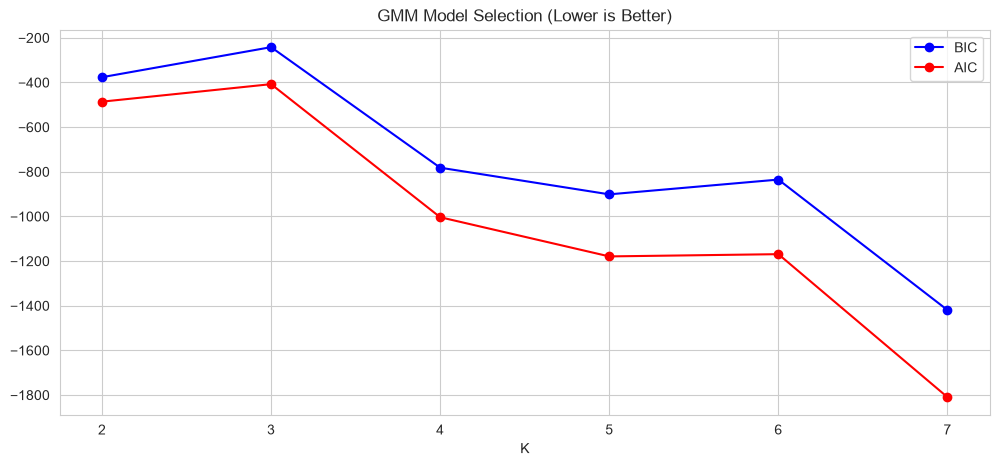

Lowest BIC at K = 7 | lowest AIC at K = 7


In [46]:
# 17.3 Optimal number of components for the GMM via BIC / AIC
ks = list(range(2, 8))
bic_scores, aic_scores = [], []
for k in ks:
    g = GaussianMixture(n_components=k, random_state=42).fit(X_city_scaled)
    bic_scores.append(g.bic(X_city_scaled)); aic_scores.append(g.aic(X_city_scaled))
plt.figure(figsize=(12, 5))
plt.plot(ks, bic_scores, "bo-", label="BIC")
plt.plot(ks, aic_scores, "ro-", label="AIC")
plt.title("GMM Model Selection (Lower is Better)")
plt.xlabel("K"); plt.legend()
save_fig("clustering_gmm_bic.png")
plt.show()
print("Lowest BIC at K =", ks[int(np.argmin(bic_scores))], "| lowest AIC at K =", ks[int(np.argmin(aic_scores))])

## 18. Extra Checks: Log Transform, K-Means from Scratch, Stability

This section matches the Excel workbook (`KMeans_City` and related sheets): three features (Cases, Deaths, Recovered), all 117 cities, `log(1 + x)` then z-scores, and farthest-first starting centroids.

In [47]:
FEATS3 = ["Cases", "Deaths", "Recovered"]
cities3 = df_unclipped.groupby("City")[FEATS3].sum().sort_values("Cases", ascending=False)

def prepare(frame, log=True):
    x = frame[FEATS3].clip(lower=0).astype(float)
    if log:
        x = np.log1p(x)
    return ((x - x.mean()) / x.std(ddof=1)).to_numpy()

def farthest_first(Zm, k):
    idx = [0]
    while len(idx) < k:
        d = np.min(((Zm[:, None, :] - Zm[idx][None]) ** 2).sum(2), axis=1)
        idx.append(int(d.argmax()))
    return idx

def run_kmeans(Zm, k):
    return KMeans(n_clusters=k, init=Zm[farthest_first(Zm, k)], n_init=1, max_iter=300, random_state=42).fit(Zm)

Z_log, Z_raw = prepare(cities3), prepare(cities3, log=False)
km_log, km_raw = run_kmeans(Z_log, 3), run_kmeans(Z_raw, 3)
print(f"{len(cities3)} cities (all of them, no minimum-cases filter)")
print("Cluster sizes with raw counts :", np.bincount(km_raw.labels_).tolist(), "| mean silhouette", round(silhouette_score(Z_raw, km_raw.labels_), 3))
print("Cluster sizes with log(1 + x) :", np.bincount(km_log.labels_).tolist(), "| mean silhouette", round(silhouette_score(Z_log, km_log.labels_), 3))
for c in range(3):
    members = cities3.index[km_raw.labels_ == c]
    if len(members) <= 3:
        print(f"  raw-count cluster with only {len(members)} city/cities: {', '.join(members)}")
print("Agreement between raw and log solutions (adjusted Rand index):", round(adjusted_rand_score(km_raw.labels_, km_log.labels_), 3))
print(f"\nLog-transformed solution: WCSS {km_log.inertia_:.4f} (the Excel sheet KMeans_City shows the same value when the log switch is 1)")

114 cities (all of them, no minimum-cases filter)
Cluster sizes with raw counts : [1, 112, 1] | mean silhouette 0.961
Cluster sizes with log(1 + x) : [6, 61, 47] | mean silhouette 0.474
  raw-count cluster with only 1 city/cities: Karachi
  raw-count cluster with only 1 city/cities: Lahore
Agreement between raw and log solutions (adjusted Rand index): 0.053

Log-transformed solution: WCSS 93.2502 (the Excel sheet KMeans_City shows the same value when the log switch is 1)


In [48]:
def kmeans_scratch(Zm, start_rows, max_iter=50):
    centroids = Zm[start_rows].copy()
    labels = None
    for it in range(1, max_iter + 1):
        dist = np.sqrt(((Zm[:, None, :] - centroids[None]) ** 2).sum(axis=2))      # distance to each centroid
        new_labels = dist.argmin(axis=1)                                            # assign to the nearest centroid
        changed = len(Zm) if labels is None else int((new_labels != labels).sum())
        print(f"  iteration {it}: {changed} points reassigned")
        if labels is not None and changed == 0:
            break
        labels = new_labels
        centroids = np.array([Zm[labels == k].mean(axis=0) if (labels == k).any() else centroids[k] for k in range(len(centroids))])
    return labels, centroids, sum(((Zm[labels == k] - centroids[k]) ** 2).sum() for k in range(len(centroids)))

start = farthest_first(Z_log, 3)
print("Starting centroids:", list(cities3.index[start]))
labels_s, cent_s, wcss_s = kmeans_scratch(Z_log, start)
print(f"\nFrom scratch WCSS {wcss_s:.4f} | scikit-learn WCSS {km_log.inertia_:.4f}")
print("Identical cluster assignments:", bool((labels_s == km_log.labels_).all()))

Starting centroids: ['Karachi', 'Kolai Pallas', 'Larkana']
  iteration 1: 114 points reassigned
  iteration 2: 10 points reassigned
  iteration 3: 1 points reassigned
  iteration 4: 1 points reassigned
  iteration 5: 0 points reassigned

From scratch WCSS 93.2502 | scikit-learn WCSS 93.2502
Identical cluster assignments: True


In [49]:
reference = km_log.labels_
scores = [adjusted_rand_score(reference, KMeans(n_clusters=3, init="random", n_init=1, random_state=s).fit(Z_log).labels_) for s in range(20)]
print("Stability over 20 random starts (adjusted Rand index vs the farthest-first solution)")
print(f"  min {min(scores):.3f} | mean {np.mean(scores):.3f} | max {max(scores):.3f}")
print("1.0 = same grouping. Lower values mean a few cities move between neighbouring tiers depending on the start.")

Stability over 20 random starts (adjusted Rand index vs the farthest-first solution)
  min 0.345 | mean 0.589 | max 1.000
1.0 = same grouping. Lower values mean a few cities move between neighbouring tiers depending on the start.


## 19. Summary and Comparison with Excel

| Aspect | Excel | Python (scikit-learn) |
|:--|:--|:--|
| Built-in K-Means | No (add-in or formulas) | Yes |
| Manual implementation | Yes (the KMeans_ sheets use formulas) | Yes (Section 18) |
| Standardisation | STANDARDIZE or (x - AVERAGE) / STDEV | StandardScaler |
| Elbow method | Repeat per K and chart (Elbow_Silhouette) | Loop over K |
| Silhouette | Formula-based (Distance_Matrix) | Built in |
| 3D plot, PCA, radar | No | Yes |
| Hierarchical, DBSCAN, GMM | No | Yes |
| Interactive charts | No | Yes (Plotly) |

**Points to state when presenting the results**
- Cluster numbers are arbitrary. The names (Epicenter, Hotspot, Low-Burden) come from average cases.
- The guide's raw-count features let a handful of very large cities dominate; Section 18 shows the log-transformed version used in Excel.
- The choice of K is a judgement. When the metrics disagree, the output of Section 13 says so; explain the choice using the elbow plot and the interpretation.
- Province (8 rows) and travel-history (a few rows) clusters are small samples: read them as tiers, not as findings.
- Outputs are in `outputs/clustering/`: PNG figures, `Clustering_Report.xlsx`, `city_clusters.csv`, `province_clusters.csv` and the interactive HTML (when Plotly is installed).

# PART C: Dimensionality Reduction (PCA)

Principal Component Analysis on the Pakistan COVID-19 data: city profiles, the daily series and provinces. Run it after Part 0 (it only needs the cleaned `df`).

| Section | Content |
|:--|:--|
| C1-C3 | Setup, aggregated datasets (city / daily / province), the maths of PCA from scratch |
| C4-C7 | Is PCA justified? Correlations, Bartlett and KMO tests, VIF, distributions, standardisation, outliers |
| C8-C12 | Full PCA fit, scree and cumulative variance, how many components, loadings, bootstrap check of the loadings |
| C13-C18 | Biplot, 2D by province and by CFR, 3D, interactive Plotly, K-Means in PC space and the comparison with raw features |
| C19-C22 | Temporal PCA (daily), Kernel PCA, PCA vs t-SNE, other methods (Isomap, LLE, ICA, NMF, Incremental PCA, UMAP if installed), PCA vs LDA |
| C23-C26 | Reconstruction / denoising, feature contributions, log and winsorised variants, anomaly detection |
| C27-C29 | 10-panel dashboard, export (Excel, CSV, PNG, HTML), interpretation computed from your data, quality metrics |

Outputs are written to `outputs/pca/`. The text in C28-C29 is computed from the results, so it always matches the numbers above it.

Every city feature here is a count or a ratio, and Karachi and Lahore are far larger than the other cities. Expect PC1 to be a "size" axis. Sections C23 and C25 show how much that depends on the scaling choice.

In [50]:
# ============================================================
# C1. PCA SETUP
# ============================================================
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import IncrementalPCA, KernelPCA, FastICA, NMF
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.manifold import TSNE, Isomap, LocallyLinearEmbedding
from sklearn.metrics import mean_squared_error
from scipy.stats import chi2
try:
    import plotly.graph_objects as go
except ImportError:
    go = None
try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

OUT_PCA = BASE / "outputs" / "pca"
if SAVE_OUTPUTS:
    OUT_PCA.mkdir(parents=True, exist_ok=True)

def save_pca(name):
    if SAVE_OUTPUTS:
        plt.savefig(OUT_PCA / name, dpi=150, bbox_inches="tight")

PC_MARKERS = ["o", "s", "^", "D", "v", "P", "*", "X", "<", ">"]
PCA_CLUSTER_COLORS = ["#E63946", "#2A9D8F", "#F4A261"]
print(f"plotly available: {HAS_PLOTLY} | umap available: {HAS_UMAP}")
print("Outputs to:", OUT_PCA if SAVE_OUTPUTS else "(not saving)")

plotly available: True | umap available: False
Outputs to: D:\DA projects\Covid-19-portfolio\outputs\pca


## C2. Aggregated Datasets (City, Daily, Province)

In [51]:
# Row-level derived features (df is the cleaned data from Part 0)
dfp = df.copy()
dfp["CFR"] = np.where(dfp["Cases"] > 0, dfp["Deaths"] / dfp["Cases"] * 100, 0)
dfp["Recovery_Rate"] = np.where(dfp["Cases"] > 0, dfp["Recovered"] / dfp["Cases"] * 100, 0)

def add_rates(d):
    d["CFR"] = np.where(d["Total_Cases"] > 0, d["Total_Deaths"] / d["Total_Cases"] * 100, 0)
    d["Recovery_Rate"] = np.where(d["Total_Cases"] > 0, d["Total_Recovered"] / d["Total_Cases"] * 100, 0)
    return d

AGG = dict(Total_Cases=("Cases", "sum"), Total_Deaths=("Deaths", "sum"), Total_Recovered=("Recovered", "sum"), Total_Active=("Active", "sum"),
           Records=("Cases", "count"), Avg_Daily_Cases=("Cases", "mean"), Max_Daily_Cases=("Cases", "max"))

# A. City level
pcity = add_rates(dfp.groupby(["City", "Province"]).agg(**AGG).reset_index())
n_all = len(pcity)
pcity = pcity[pcity["Total_Cases"] >= 10].reset_index(drop=True)
print(f"Cities for PCA: {len(pcity)} of {n_all} (cities with at least 10 cases)")

# B. Daily
pdaily = dfp.groupby("Date").agg(Cases=("Cases", "sum"), Deaths=("Deaths", "sum"), Recovered=("Recovered", "sum")).reset_index()
pdaily["Active"] = pdaily["Cases"] - pdaily["Deaths"] - pdaily["Recovered"]
pdaily["Day_Num"] = (pdaily["Date"] - pdaily["Date"].min()).dt.days + 1
for c_ in ["Cases", "Deaths", "Recovered"]:
    pdaily[f"Cumulative_{c_}"] = pdaily[c_].cumsum()
pdaily["CFR"] = np.where(pdaily["Cumulative_Cases"] > 0, pdaily["Cumulative_Deaths"] / pdaily["Cumulative_Cases"] * 100, 0)
pdaily["Recovery_Rate"] = np.where(pdaily["Cumulative_Cases"] > 0, pdaily["Cumulative_Recovered"] / pdaily["Cumulative_Cases"] * 100, 0)

# C. Province
pprov = add_rates(dfp.groupby("Province").agg(**AGG).reset_index())

feats = ["Total_Cases", "Total_Deaths", "Total_Recovered", "Total_Active", "CFR", "Recovery_Rate", "Avg_Daily_Cases", "Max_Daily_Cases"]
X_pcafeat = pcity[feats].copy()
print("Missing values in the PCA features:", int(X_pcafeat.isna().sum().sum()))
print(f"Daily rows: {len(pdaily)} | Provinces: {len(pprov)}")
print(pcity.head().to_string())

Cities for PCA: 93 of 120 (cities with at least 10 cases)
Missing values in the PCA features: 0
Daily rows: 91 | Provinces: 8
            City            Province  Total_Cases  Total_Deaths  Total_Recovered  Total_Active  Records  Avg_Daily_Cases  Max_Daily_Cases        CFR  Recovery_Rate
0     Abbottabad  Khyber Pakhtunkhwa          279            14               44           221       49         5.693878               32   5.017921      15.770609
1         Astore    Gilgit-Baltistan           69            14               62            -7       27         2.555556               16  20.289855      89.855072
2         Attock              Punjab           15             0                0            15        3         5.000000               13   0.000000       0.000000
3          Badin               Sindh           56             4               11            41       19         2.947368               16   7.142857      19.642857
4  Bahawal Nagar              Punjab           21     

## C3. The Maths of PCA from Scratch

PCA is the eigen-decomposition of the covariance matrix of the standardised data. Doing it by hand with NumPy must give exactly the numbers scikit-learn gives later (eigenvalues = explained variance, eigenvectors = loadings up to sign).

In [52]:
Xz = (X_pcafeat - X_pcafeat.mean()) / X_pcafeat.std(ddof=0)             # centred and scaled (population std, like StandardScaler)
cov = (Xz.T @ Xz) / (len(Xz) - 1)                                       # covariance matrix of standardised data (= correlation matrix)
eigval, eigvec = np.linalg.eigh(cov.values)
order_ = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order_], eigvec[:, order_]
print("Eigenvalues (manual):", np.round(eigval, 4))
print("Share of variance (%):", np.round(eigval / eigval.sum() * 100, 2))
print("Sum of eigenvalues = number of features:", round(eigval.sum(), 6))
Z_manual = Xz.values @ eigvec[:, :2]                                    # Z = X . V_k
print("First city scores PC1/PC2 (manual):", np.round(Z_manual[0], 4))

Eigenvalues (manual): [ 5.6779  1.3051  0.7311  0.2952  0.0579  0.0141  0.0057 -0.    ]
Share of variance (%): [ 7.021e+01  1.614e+01  9.040e+00  3.650e+00  7.200e-01  1.700e-01
  7.000e-02 -0.000e+00]
Sum of eigenvalues = number of features: 8.086957
First city scores PC1/PC2 (manual): [0.3549 0.3626]


## C4. Is PCA Justified? Correlation Analysis

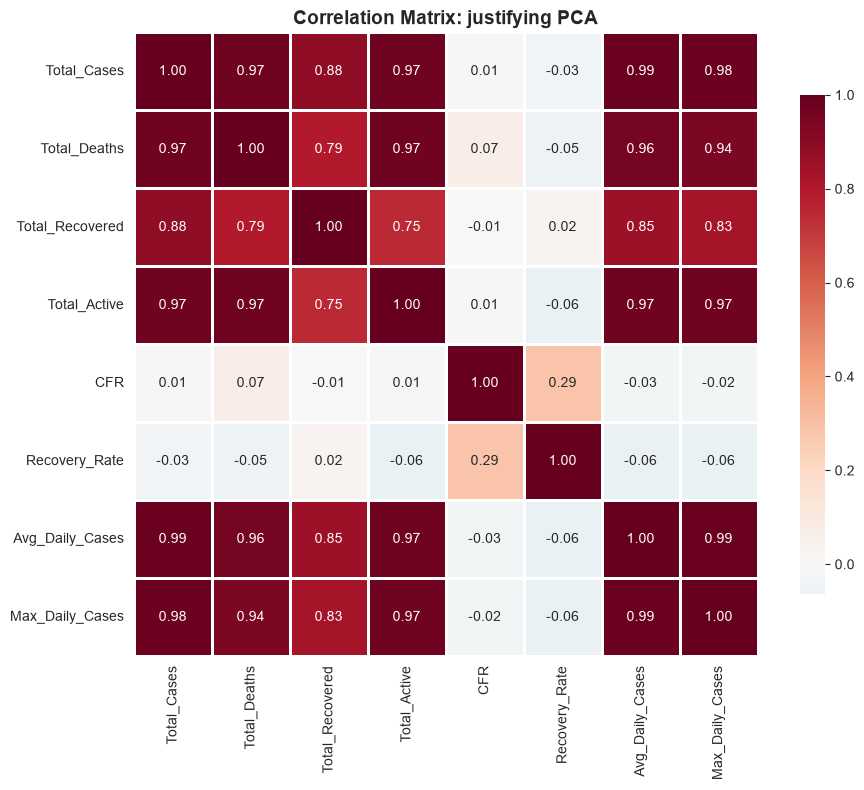

High correlations (|r| > 0.7):
  Total_Cases <-> Total_Deaths: 0.967
  Total_Cases <-> Total_Recovered: 0.880
  Total_Cases <-> Total_Active: 0.974
  Total_Cases <-> Avg_Daily_Cases: 0.990
  Total_Cases <-> Max_Daily_Cases: 0.979
  Total_Deaths <-> Total_Recovered: 0.790
  Total_Deaths <-> Total_Active: 0.970
  Total_Deaths <-> Avg_Daily_Cases: 0.957
  Total_Deaths <-> Max_Daily_Cases: 0.941
  Total_Recovered <-> Total_Active: 0.750
  Total_Recovered <-> Avg_Daily_Cases: 0.854
  Total_Recovered <-> Max_Daily_Cases: 0.828
  Total_Active <-> Avg_Daily_Cases: 0.972
  Total_Active <-> Max_Daily_Cases: 0.971
  Avg_Daily_Cases <-> Max_Daily_Cases: 0.991

Found 15 highly correlated pairs of 28
-> PCA is appropriate: the features are largely redundant


In [53]:
fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = X_pcafeat.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, linewidths=1, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation Matrix: justifying PCA", fontsize=14, fontweight="bold")
plt.tight_layout()
save_pca("pca_correlation.png")
plt.show()

high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.7:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], val))
print("High correlations (|r| > 0.7):")
for a, b, v in high_corr_pairs:
    print(f"  {a} <-> {b}: {v:.3f}")
print(f"\nFound {len(high_corr_pairs)} highly correlated pairs of {len(corr_matrix) * (len(corr_matrix) - 1) // 2}")
print("-> PCA is appropriate: the features are largely redundant" if len(high_corr_pairs) >= 3 else "-> Few redundant pairs: PCA would give limited compression")

## C5. Formal Checks: Bartlett, KMO and VIF

In [54]:
R = corr_matrix.values
n_obs, p_var = len(X_pcafeat), R.shape[0]

# Bartlett's test of sphericity: H0 = the correlation matrix is the identity (no correlation to exploit)
sign, logdet = np.linalg.slogdet(R)
chi_sq = -(n_obs - 1 - (2 * p_var + 5) / 6) * logdet
df_b = p_var * (p_var - 1) / 2
p_bartlett = chi2.sf(chi_sq, df_b)

# Kaiser-Meyer-Olkin measure of sampling adequacy (>= 0.6 is acceptable for PCA)
invR = np.linalg.pinv(R)
partial = -invR / np.sqrt(np.outer(np.diag(invR), np.diag(invR)))
np.fill_diagonal(partial, 0)
r2 = (R - np.eye(p_var)) ** 2
kmo_per = r2.sum(axis=0) / (r2.sum(axis=0) + (partial ** 2).sum(axis=0))
kmo_total = r2.sum() / (r2.sum() + (partial ** 2).sum())

# Variance inflation factors: diagonal of the inverse correlation matrix
vif = pd.Series(np.diag(invR), index=feats, name="VIF")

print(f"Bartlett sphericity: chi-square = {chi_sq:,.1f}, df = {df_b:.0f}, p = {p_bartlett:.3g} -> {'correlations are significant' if p_bartlett < 0.05 else 'not significant'}")
print(f"KMO overall = {kmo_total:.3f} ({'marvellous' if kmo_total >= .9 else 'meritorious' if kmo_total >= .8 else 'middling' if kmo_total >= .7 else 'mediocre' if kmo_total >= .6 else 'unacceptable (< 0.6)'})")
print("\nPer-feature KMO and VIF (VIF > 10 = serious multicollinearity):")
print(pd.DataFrame({"KMO": kmo_per, "VIF": vif.values}, index=feats).round(2).to_string())

Bartlett sphericity: chi-square = 4,247.2, df = 28, p = 0 -> correlations are significant
KMO overall = 0.770 (middling)

Per-feature KMO and VIF (VIF > 10 = serious multicollinearity):
                  KMO     VIF
Total_Cases      0.73   14.33
Total_Deaths     0.78   27.53
Total_Recovered  0.85    4.12
Total_Active     0.72   27.11
CFR              0.26    1.26
Recovery_Rate    0.39    1.14
Avg_Daily_Cases  0.80  124.90
Max_Daily_Cases  0.82   73.16


## C6. Feature Distributions

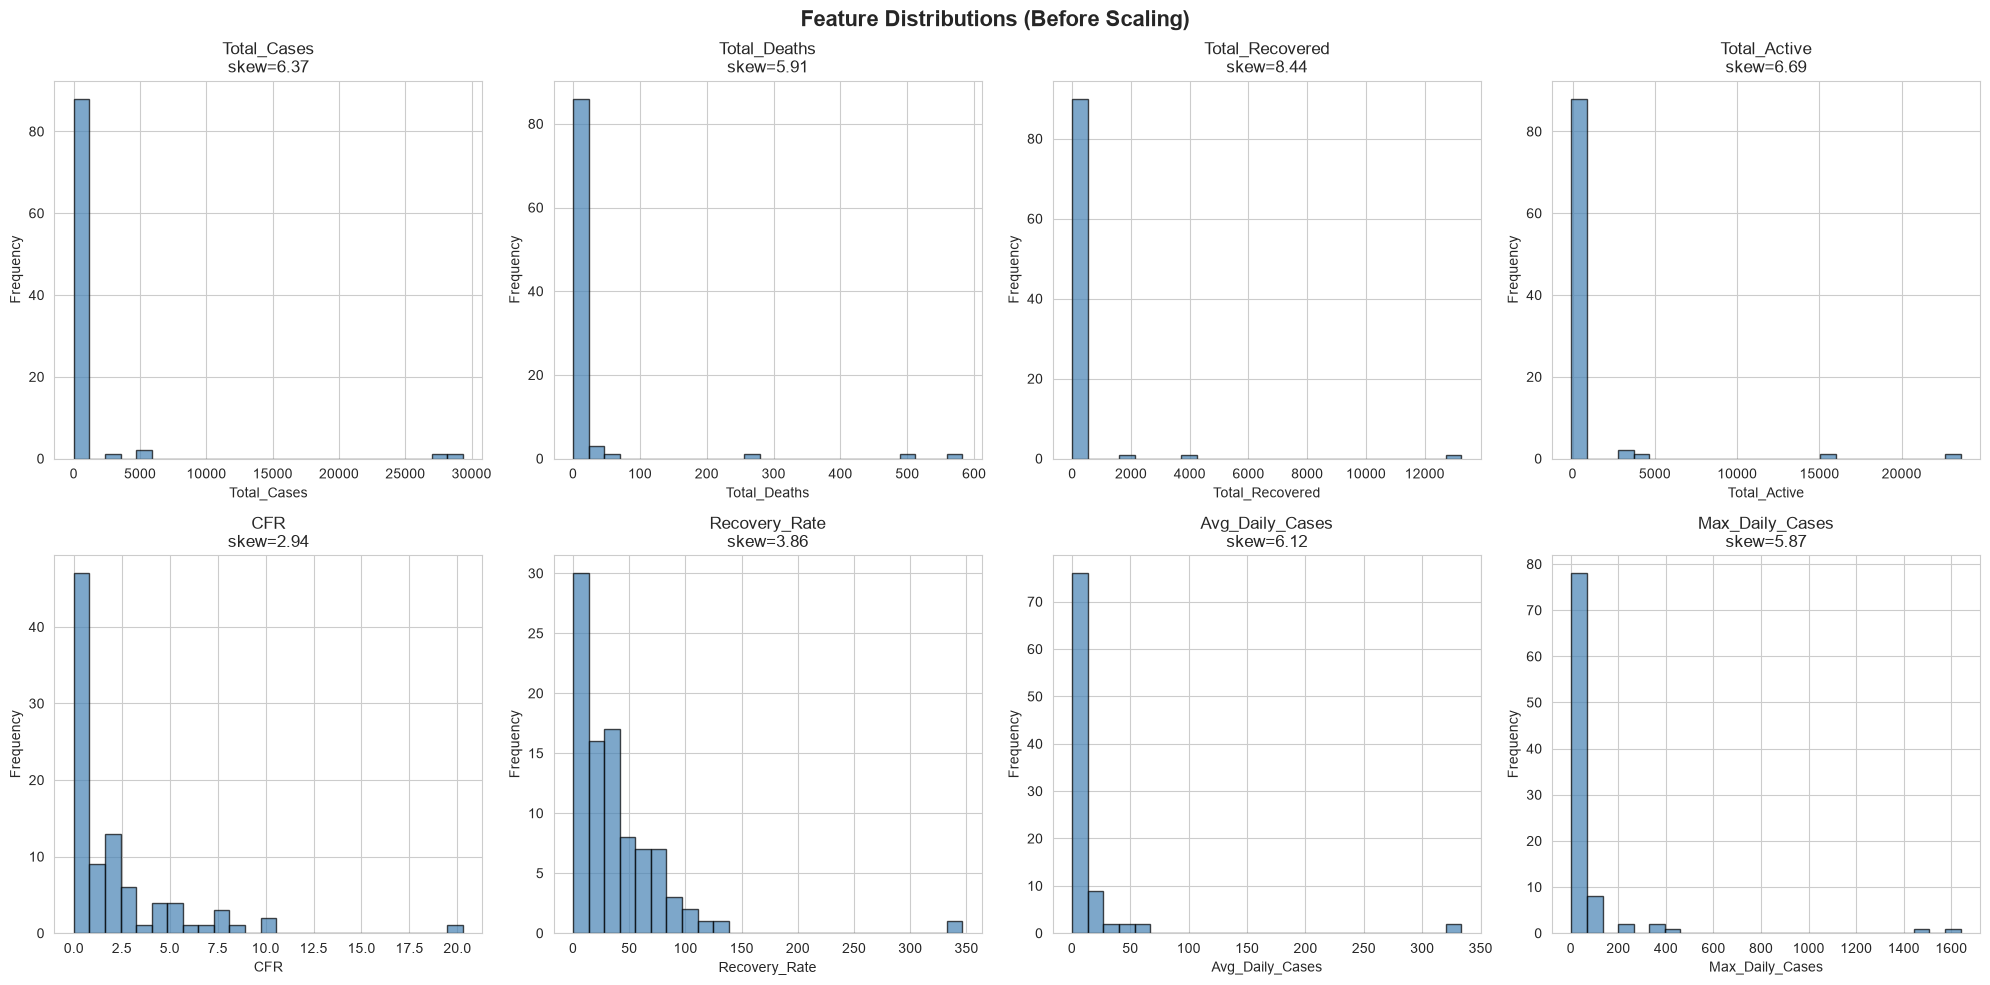

Skewness above 2 means a long right tail: a few huge cities dominate the variance. See C25 for a log-transformed version.


In [55]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, feat in enumerate(feats):
    axes[i].hist(X_pcafeat[feat], bins=25, color="steelblue", edgecolor="black", alpha=0.7)
    axes[i].set_title(f"{feat}\nskew={X_pcafeat[feat].skew():.2f}")
    axes[i].set_xlabel(feat); axes[i].set_ylabel("Frequency")
plt.suptitle("Feature Distributions (Before Scaling)", fontsize=16, fontweight="bold")
plt.tight_layout()
save_pca("pca_distributions.png")
plt.show()
print("Skewness above 2 means a long right tail: a few huge cities dominate the variance. See C25 for a log-transformed version.")

## C7. Preprocessing: Standardisation and Outliers

PCA is variance-based, so a feature measured in thousands (cases) would swamp one measured in percent (CFR) unless every feature is put on the same scale first.

In [56]:
scaler_pca = StandardScaler()
X_sc = scaler_pca.fit_transform(X_pcafeat)
X_sc_df = pd.DataFrame(X_sc, columns=feats)
print("Before standardisation:")
print(X_pcafeat.describe().round(2).loc[["mean", "std", "min", "max"]].to_string())
print("\nAfter standardisation (means ~ 0, standard deviations ~ 1):")
print(X_sc_df.describe().round(2).loc[["mean", "std", "min", "max"]].to_string())

def detect_outliers(series, k=3):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - k * iqr) | (series > q3 + k * iqr)

outlier_summary = pd.DataFrame({"Feature": feats, "Outliers": [int(detect_outliers(X_pcafeat[f]).sum()) for f in feats],
                                "Outlier_%": [detect_outliers(X_pcafeat[f]).mean() * 100 for f in feats]})
print("\nOutlier summary (3 x IQR rule):")
print(outlier_summary.round(1).to_string(index=False))
print("Cities that are outliers on Total_Cases:", ", ".join(pcity.loc[detect_outliers(X_pcafeat["Total_Cases"]), "City"]) or "none")

Before standardisation:
      Total_Cases  Total_Deaths  Total_Recovered  Total_Active    CFR  Recovery_Rate  Avg_Daily_Cases  Max_Daily_Cases
mean       901.69         18.56           265.68        617.45   1.98          36.57            15.83            76.38
std       4219.34         82.97          1433.63       2954.02   3.14          45.04            48.31           233.17
min         10.00          0.00             0.00        -69.00   0.00           0.00             0.29             3.00
max      29346.00        582.00         13248.00      23580.00  20.29         346.15           333.51          1639.00

After standardisation (means ~ 0, standard deviations ~ 1):
      Total_Cases  Total_Deaths  Total_Recovered  Total_Active   CFR  Recovery_Rate  Avg_Daily_Cases  Max_Daily_Cases
mean        -0.00          0.00            -0.00         -0.00 -0.00          -0.00             0.00             0.00
std          1.01          1.01             1.01          1.01  1.01           1.01 

## C8. Fitting PCA

In [57]:
pca_full = PCA(random_state=42).fit(X_sc)
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)
pca_summary = pd.DataFrame({"Component": [f"PC{i + 1}" for i in range(len(explained_var))], "Eigenvalue": pca_full.explained_variance_,
                            "Variance Explained (%)": explained_var * 100, "Cumulative Variance (%)": cumulative_var * 100})
print("=" * 70); print("PCA SUMMARY"); print("=" * 70)
print(pca_summary.round(4).to_string(index=False))
for threshold in [0.80, 0.90, 0.95, 0.99]:
    print(f"Components for {threshold * 100:.0f}% variance: {int(np.argmax(cumulative_var >= threshold)) + 1}")
print("\nCheck against the manual eigen-decomposition (C3): max difference in eigenvalues =",
      f"{np.abs(np.sort(pca_full.explained_variance_)[::-1] - eigval).max():.2e}")

PCA SUMMARY
Component  Eigenvalue  Variance Explained (%)  Cumulative Variance (%)
      PC1      5.6779                 70.2110                  70.2110
      PC2      1.3051                 16.1380                  86.3491
      PC3      0.7311                  9.0402                  95.3893
      PC4      0.2952                  3.6508                  99.0401
      PC5      0.0579                  0.7155                  99.7556
      PC6      0.0141                  0.1744                  99.9300
      PC7      0.0057                  0.0700                 100.0000
      PC8      0.0000                  0.0000                 100.0000
Components for 80% variance: 2
Components for 90% variance: 3
Components for 95% variance: 3
Components for 99% variance: 4

Check against the manual eigen-decomposition (C3): max difference in eigenvalues = 7.69e-16


## C9. Scree Plot and Cumulative Variance

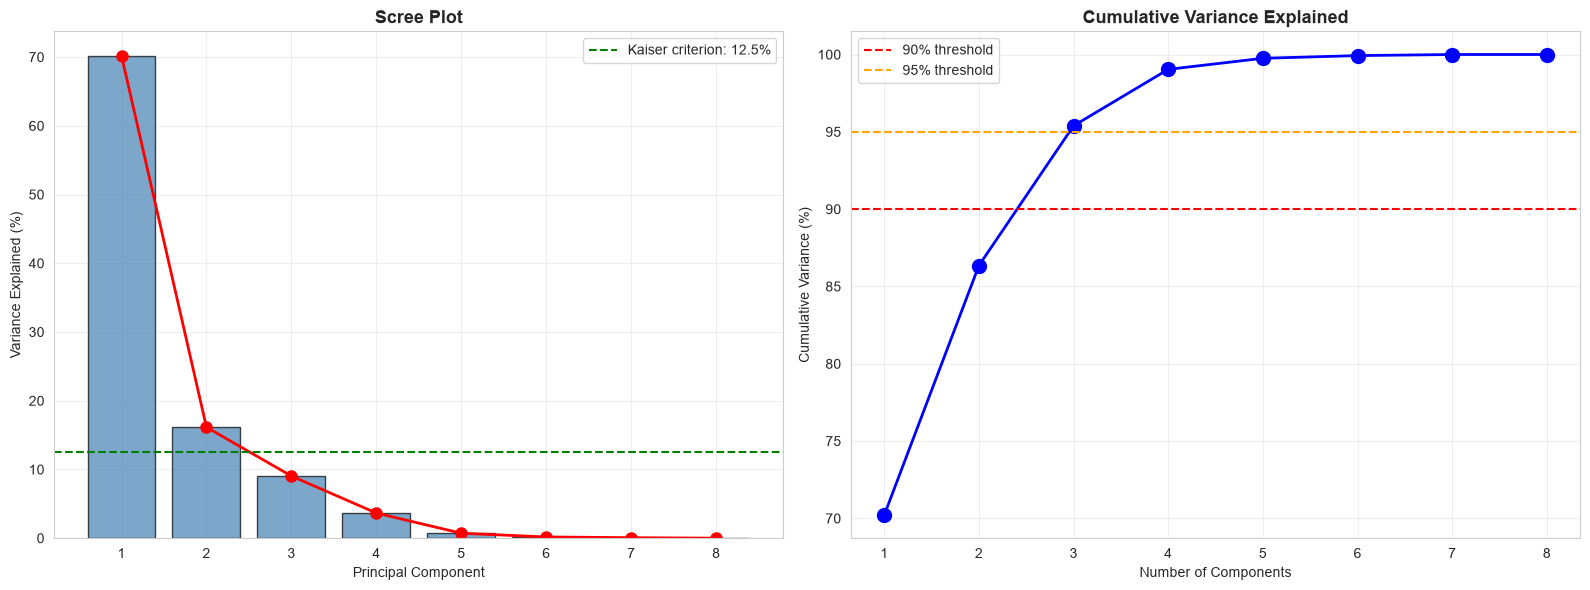

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
k_ = range(1, len(explained_var) + 1)
axes[0].bar(k_, explained_var * 100, color="steelblue", edgecolor="black", alpha=0.7)
axes[0].plot(k_, explained_var * 100, "ro-", markersize=8, linewidth=2)
axes[0].axhline(y=100 / len(explained_var), color="green", linestyle="--", label=f"Kaiser criterion: {100 / len(explained_var):.1f}%")
axes[0].set_title("Scree Plot", fontsize=13, fontweight="bold"); axes[0].set_xlabel("Principal Component"); axes[0].set_ylabel("Variance Explained (%)")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(k_, cumulative_var * 100, "bo-", markersize=10, linewidth=2)
axes[1].axhline(y=90, color="red", linestyle="--", label="90% threshold")
axes[1].axhline(y=95, color="orange", linestyle="--", label="95% threshold")
axes[1].set_title("Cumulative Variance Explained", fontsize=13, fontweight="bold"); axes[1].set_xlabel("Number of Components"); axes[1].set_ylabel("Cumulative Variance (%)")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
save_pca("pca_scree.png")
plt.show()

## C10. How Many Components?

In [59]:
n_kaiser = int((pca_full.explained_variance_ > 1).sum())          # eigenvalue > 1 (on standardised data)
n_90 = int(np.argmax(cumulative_var >= 0.90)) + 1
n_95 = int(np.argmax(cumulative_var >= 0.95)) + 1
second_diffs = np.diff(np.diff(explained_var))
elbow = int(np.argmax(second_diffs)) + 2

# Parallel analysis: keep components whose eigenvalue beats the 95th percentile of eigenvalues from random data of the same shape
rng = np.random.default_rng(42)
rand_eig = np.array([np.linalg.eigvalsh(np.corrcoef(rng.standard_normal(X_sc.shape), rowvar=False))[::-1] for _ in range(300)])
n_parallel = int((pca_full.explained_variance_ > np.percentile(rand_eig, 95, axis=0)).sum())

print("=" * 60); print("OPTIMAL NUMBER OF COMPONENTS"); print("=" * 60)
print(f"Kaiser (eigenvalue > 1): {n_kaiser}\n90% variance: {n_90}\n95% variance: {n_95}\nElbow method: {elbow}\nParallel analysis: {n_parallel}")
n_components_optimal = 2        # 2 for visualisation; the criteria above say how much the 2D picture leaves out
print(f"\nUsing 2 components for visualisation: they explain {cumulative_var[1] * 100:.2f}% of the variance (3 explain {cumulative_var[2] * 100:.2f}%).")

OPTIMAL NUMBER OF COMPONENTS
Kaiser (eigenvalue > 1): 2
90% variance: 3
95% variance: 3
Elbow method: 2
Parallel analysis: 1

Using 2 components for visualisation: they explain 86.35% of the variance (3 explain 95.39%).


## C11. Loadings: Which Features Drive Each Component?

Component loadings (feature weights per PC):
                    PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8
Total_Cases      0.4213  0.0116  0.0152  0.0154  0.0460  0.4426 -0.0356  0.7891
Total_Deaths     0.4097  0.0389 -0.0821 -0.2310  0.7450 -0.4414 -0.1428 -0.0155
Total_Recovered  0.3692  0.0407  0.1264  0.8677  0.1027  0.0745 -0.0714 -0.2681
Total_Active     0.4110 -0.0043 -0.0374 -0.3926 -0.0050  0.6084 -0.0122 -0.5525
CFR              0.0011  0.7072 -0.6978  0.0780 -0.0800  0.0115  0.0182  0.0000
Recovery_Rate   -0.0218  0.7039  0.6988 -0.1241  0.0045 -0.0173  0.0048  0.0000
Avg_Daily_Cases  0.4196 -0.0245  0.0167 -0.0552 -0.2699 -0.3042  0.8091  0.0000
Max_Daily_Cases  0.4158 -0.0220  0.0120 -0.1215 -0.5942 -0.3749 -0.5640 -0.0000


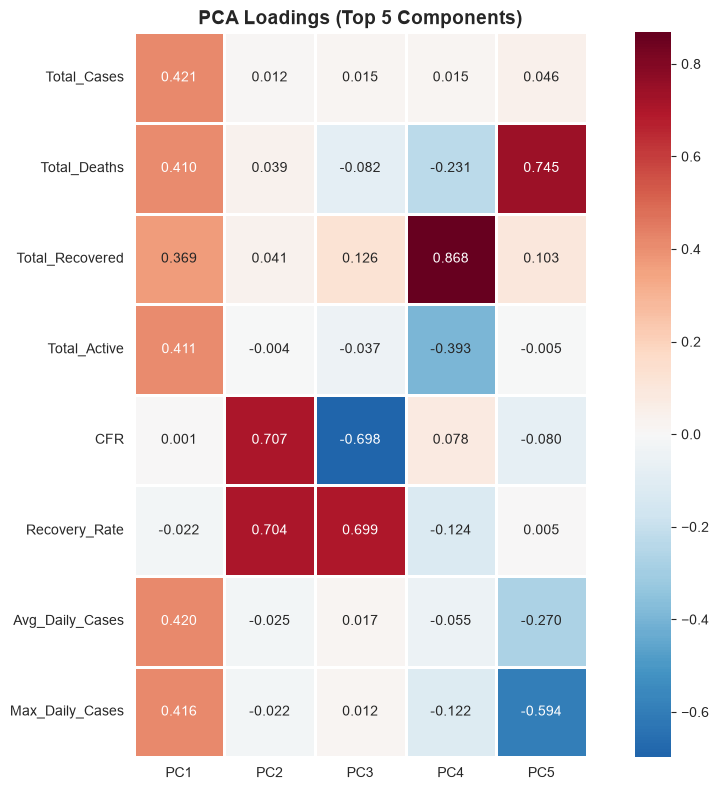


Interpretation of PC1 (explains 70.2%):
  Total_Cases         : +0.4213
  Avg_Daily_Cases     : +0.4196
  Max_Daily_Cases     : +0.4158
  Total_Active        : +0.4110
  Total_Deaths        : +0.4097
  Total_Recovered     : +0.3692
  Recovery_Rate       : -0.0218
  CFR                 : +0.0011

Interpretation of PC2 (explains 16.1%):
  CFR                 : +0.7072
  Recovery_Rate       : +0.7039
  Total_Recovered     : +0.0407
  Total_Deaths        : +0.0389
  Avg_Daily_Cases     : -0.0245
  Max_Daily_Cases     : -0.0220
  Total_Cases         : +0.0116
  Total_Active        : -0.0043

Interpretation of PC3 (explains 9.0%):
  Recovery_Rate       : +0.6988
  CFR                 : -0.6978
  Total_Recovered     : +0.1264
  Total_Deaths        : -0.0821
  Total_Active        : -0.0374
  Avg_Daily_Cases     : +0.0167
  Total_Cases         : +0.0152
  Max_Daily_Cases     : +0.0120


In [60]:
loadings_df = pd.DataFrame(pca_full.components_.T, columns=[f"PC{i + 1}" for i in range(len(explained_var))], index=feats)
print("Component loadings (feature weights per PC):")
print(loadings_df.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(loadings_df.iloc[:, :5], annot=True, fmt=".3f", cmap="RdBu_r", center=0, square=True, linewidths=1, ax=ax)
ax.set_title("PCA Loadings (Top 5 Components)", fontsize=14, fontweight="bold")
plt.tight_layout()
save_pca("pca_loadings_heatmap.png")
plt.show()
for pc in ["PC1", "PC2", "PC3"]:
    print(f"\nInterpretation of {pc} (explains {explained_var[int(pc[2:]) - 1] * 100:.1f}%):")
    for feat, val in loadings_df[pc].sort_values(key=abs, ascending=False).items():
        print(f"  {feat:20s}: {val:+.4f}")

## C12. Are the Loadings Reliable? Bootstrap

The cities are resampled 300 times, PCA is refitted each time and the signs are aligned to the original. A loading whose 95% interval excludes zero is a stable contribution.

In [61]:
rng = np.random.default_rng(42)
B_ = 300
boot = np.zeros((B_, len(feats), 2))
for b in range(B_):
    idx = rng.integers(0, len(X_sc), len(X_sc))
    comp = PCA(n_components=2, random_state=42).fit(X_sc[idx]).components_.T
    for j in range(2):
        s = np.sign(np.dot(comp[:, j], loadings_df.iloc[:, j].values)) or 1
        boot[b, :, j] = comp[:, j] * s
rows = []
for j in range(2):
    lo, hi = np.percentile(boot[:, :, j], [2.5, 97.5], axis=0)
    for i, f in enumerate(feats):
        rows.append({"PC": f"PC{j + 1}", "Feature": f, "Loading": loadings_df.iloc[i, j], "CI low": lo[i], "CI high": hi[i], "Stable (CI excludes 0)": bool(lo[i] > 0 or hi[i] < 0)})
boot_df = pd.DataFrame(rows)
print(boot_df.round(3).to_string(index=False))
print(f"\nPC1: {boot_df[boot_df.PC == 'PC1']['Stable (CI excludes 0)'].sum()} of {len(feats)} loadings stable | PC2: {boot_df[boot_df.PC == 'PC2']['Stable (CI excludes 0)'].sum()} of {len(feats)}")

 PC         Feature  Loading  CI low  CI high  Stable (CI excludes 0)
PC1     Total_Cases    0.421   0.004    0.423                    True
PC1    Total_Deaths    0.410  -0.015    0.462                   False
PC1 Total_Recovered    0.369  -0.010    0.546                   False
PC1    Total_Active    0.411   0.010    0.495                    True
PC1             CFR    0.001  -0.728    0.328                   False
PC1   Recovery_Rate   -0.022  -0.886    0.031                   False
PC1 Avg_Daily_Cases    0.420   0.018    0.425                    True
PC1 Max_Daily_Cases    0.416   0.014    0.443                    True
PC2     Total_Cases    0.012  -0.044    0.084                   False
PC2    Total_Deaths    0.039  -0.179    0.158                   False
PC2 Total_Recovered    0.041  -0.062    0.240                   False
PC2    Total_Active   -0.004  -0.199    0.099                   False
PC2             CFR    0.707  -0.267    0.982                   False
PC2   Recovery_Rate 

## C13. Biplot: Features and Cities Together

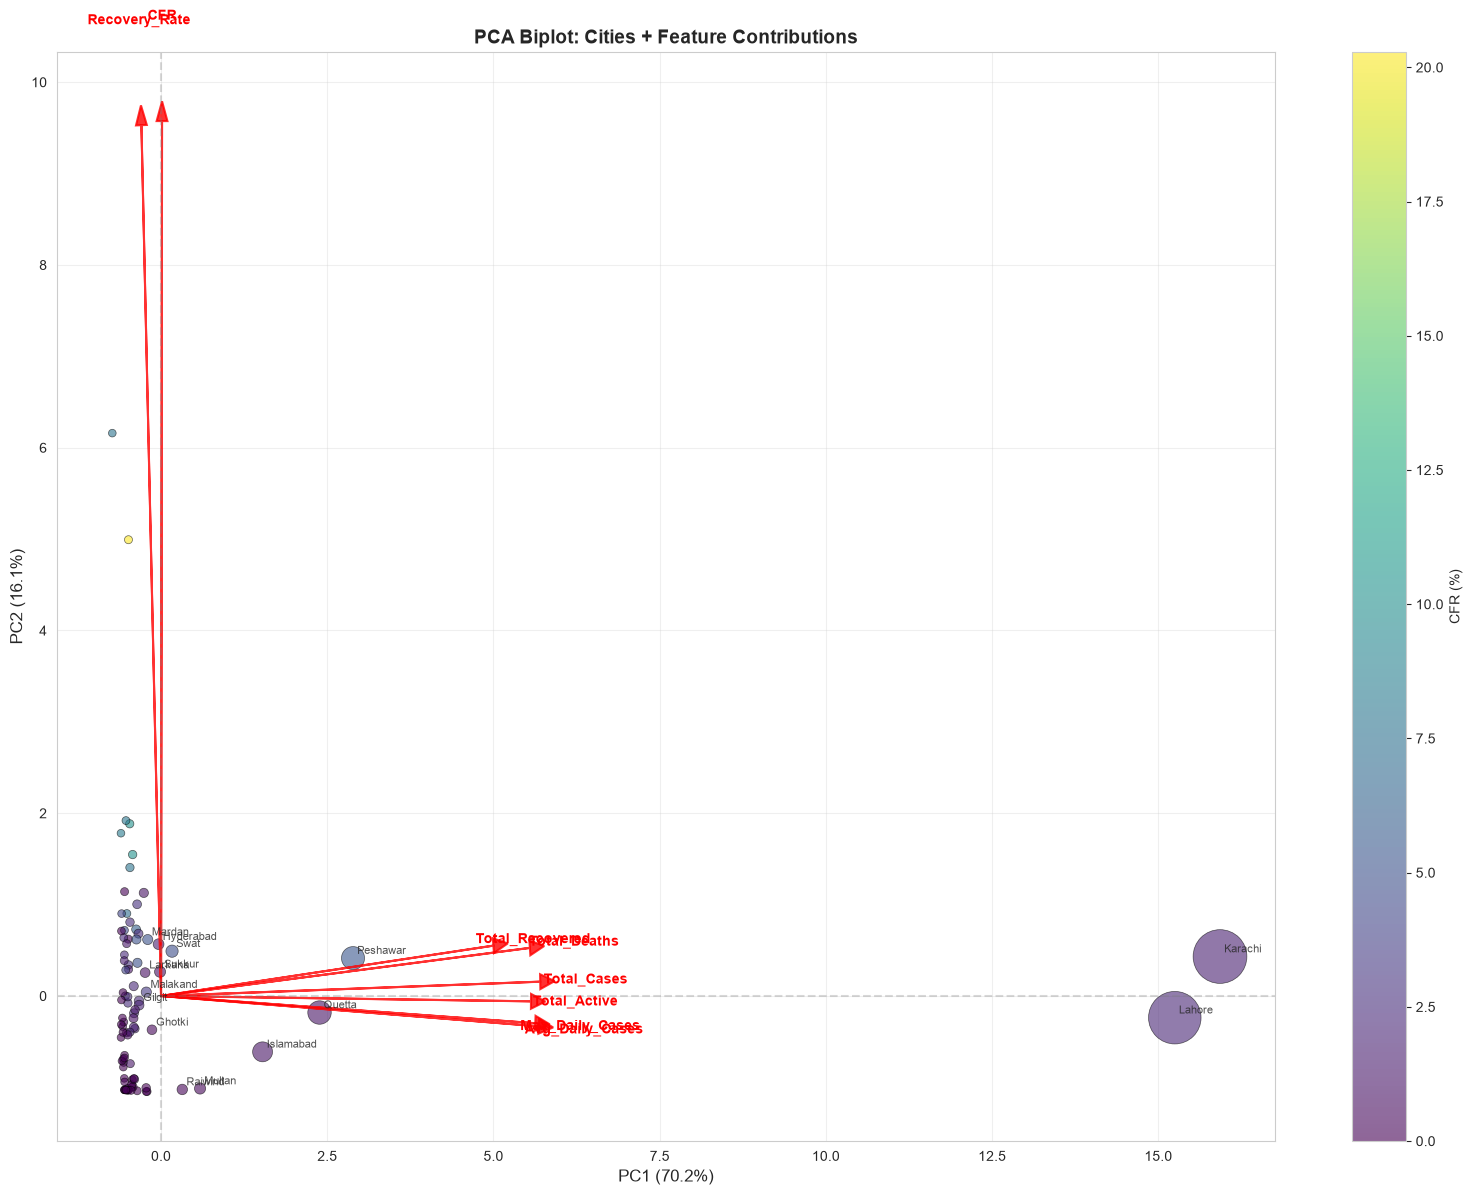

In [62]:
pca_2d = PCA(n_components=2, random_state=42)
X_pc2 = pca_2d.fit_transform(X_sc)
pc_df = pd.DataFrame(X_pc2, columns=["PC1", "PC2"])
pc_df["City"] = pcity["City"].values
pc_df["Province"] = pcity["Province"].values
pc_df["Cases"] = pcity["Total_Cases"].values
pc_df["Deaths"] = pcity["Total_Deaths"].values
pc_df["CFR"] = pcity["CFR"].values

provs_pca = list(pc_df["Province"].unique())
PC_COLORS = plt.cm.tab10(np.linspace(0, 1, max(len(provs_pca), 2)))
loadings_2d = pca_2d.components_.T[:, :2]
arrow_scale = 0.85 * np.abs(X_pc2).max()                  # arrows scaled to the size of the point cloud, whatever it is

fig, ax = plt.subplots(figsize=(16, 12))
sc_ = ax.scatter(pc_df["PC1"], pc_df["PC2"], s=pc_df["Cases"] / 20 + 30, c=pc_df["CFR"], cmap="viridis", alpha=0.6, edgecolors="black", linewidth=0.5)
for i, feat in enumerate(feats):
    ax.arrow(0, 0, loadings_2d[i, 0] * arrow_scale, loadings_2d[i, 1] * arrow_scale, head_width=arrow_scale * 0.012, head_length=arrow_scale * 0.016,
             fc="red", ec="red", linewidth=1.5, alpha=0.8)
    ax.text(loadings_2d[i, 0] * arrow_scale * 1.12, loadings_2d[i, 1] * arrow_scale * 1.12, feat, color="red", fontsize=10, fontweight="bold", ha="center", va="center")
for _, row in pc_df.nlargest(15, "Cases").iterrows():
    ax.annotate(row["City"], (row["PC1"], row["PC2"]), fontsize=8, alpha=0.8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="gray", linestyle="--", alpha=0.3); ax.axvline(0, color="gray", linestyle="--", alpha=0.3)
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.1f}%)", fontsize=12); ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.1f}%)", fontsize=12)
ax.set_title("PCA Biplot: Cities + Feature Contributions", fontsize=14, fontweight="bold"); ax.grid(alpha=0.3)
plt.colorbar(sc_, label="CFR (%)", ax=ax)
plt.tight_layout()
save_pca("pca_biplot.png")
plt.show()

## C14. 2D Projections

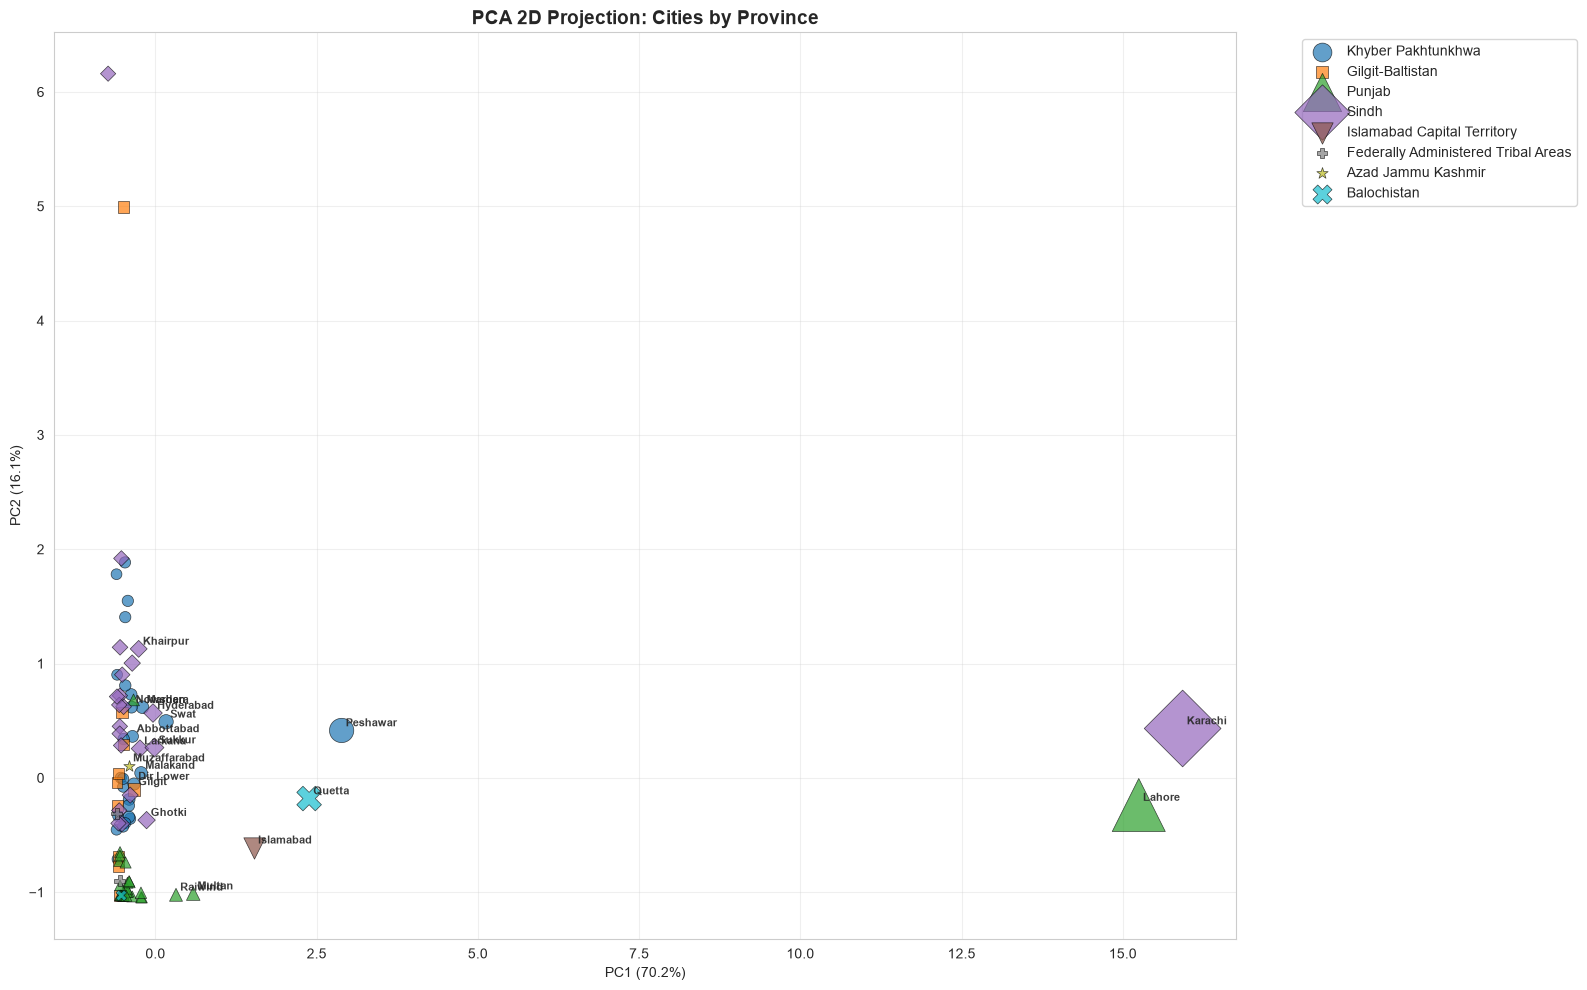

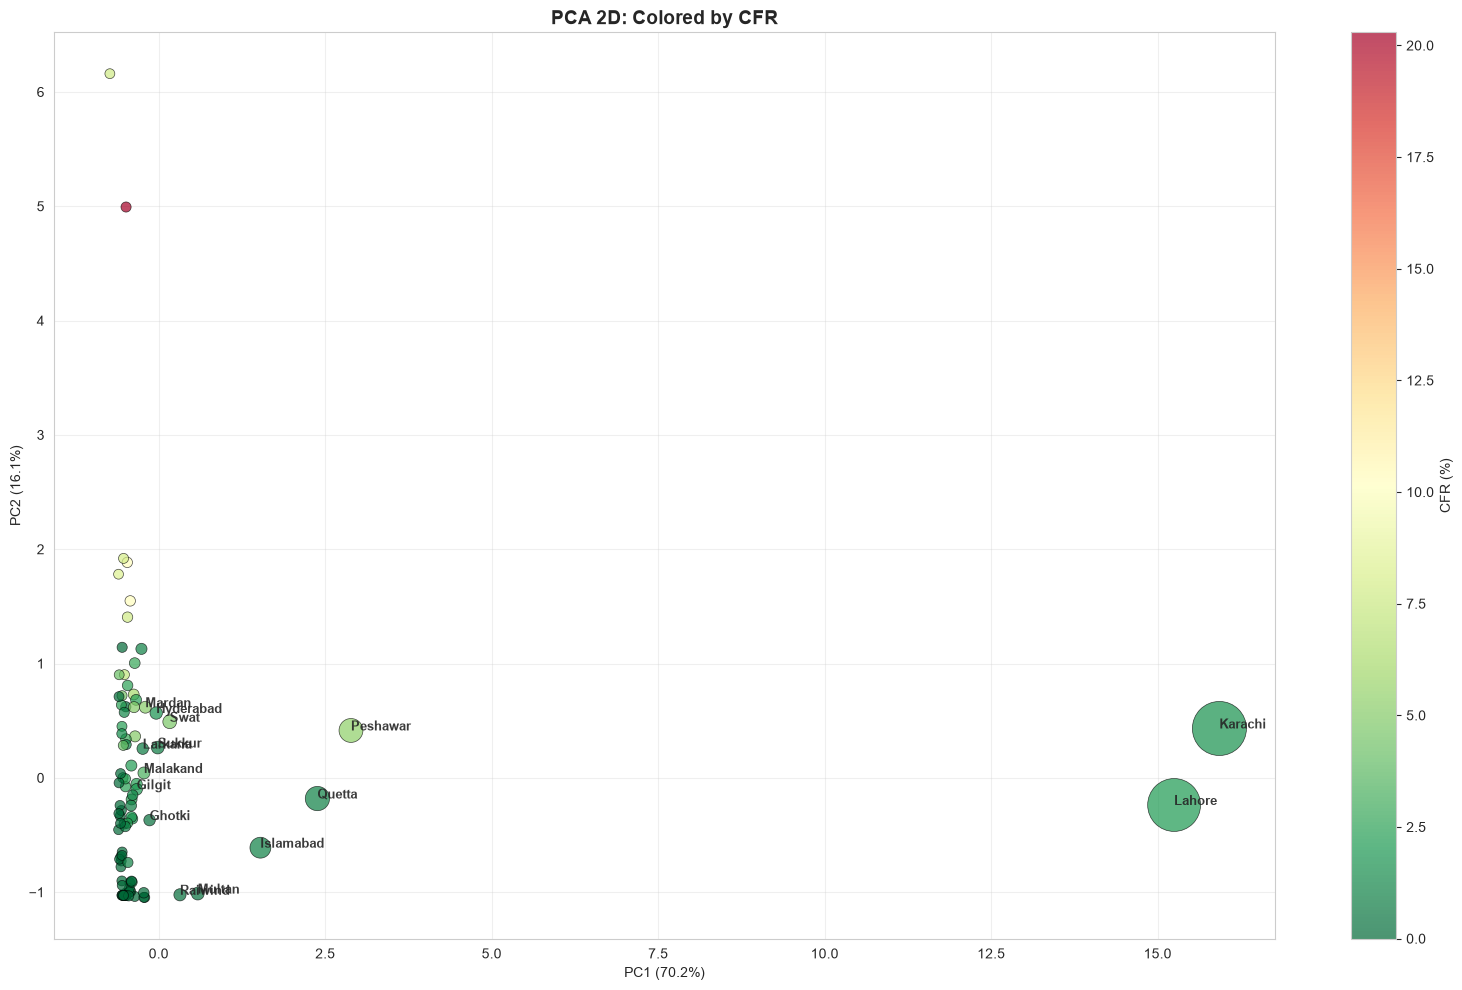

In [63]:
fig, ax = plt.subplots(figsize=(16, 10))
for i, prov in enumerate(provs_pca):
    sub = pc_df[pc_df["Province"] == prov]
    ax.scatter(sub["PC1"], sub["PC2"], c=[PC_COLORS[i]], marker=PC_MARKERS[i % len(PC_MARKERS)], s=sub["Cases"] / 20 + 60, alpha=0.7,
               edgecolors="black", linewidth=0.5, label=prov)
for _, row in pc_df.nlargest(20, "Cases").iterrows():
    ax.annotate(row["City"], (row["PC1"], row["PC2"]), fontsize=8, alpha=0.9, fontweight="bold", xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.1f}%)"); ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.1f}%)")
ax.set_title("PCA 2D Projection: Cities by Province", fontsize=14, fontweight="bold")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout()
save_pca("pca_2d_by_province.png")
plt.show()

fig, ax = plt.subplots(figsize=(16, 10))
sc_ = ax.scatter(pc_df["PC1"], pc_df["PC2"], s=pc_df["Cases"] / 20 + 50, c=pc_df["CFR"], cmap="RdYlGn_r", alpha=0.7, edgecolors="black", linewidth=0.5)
for _, row in pc_df.nlargest(15, "Cases").iterrows():
    ax.annotate(row["City"], (row["PC1"], row["PC2"]), fontsize=9, fontweight="bold", alpha=0.9)
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.1f}%)"); ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.1f}%)")
ax.set_title("PCA 2D: Colored by CFR", fontsize=14, fontweight="bold"); ax.grid(alpha=0.3)
plt.colorbar(sc_, label="CFR (%)")
plt.tight_layout()
save_pca("pca_2d_cfr.png")
plt.show()

## C15. 3D Projection

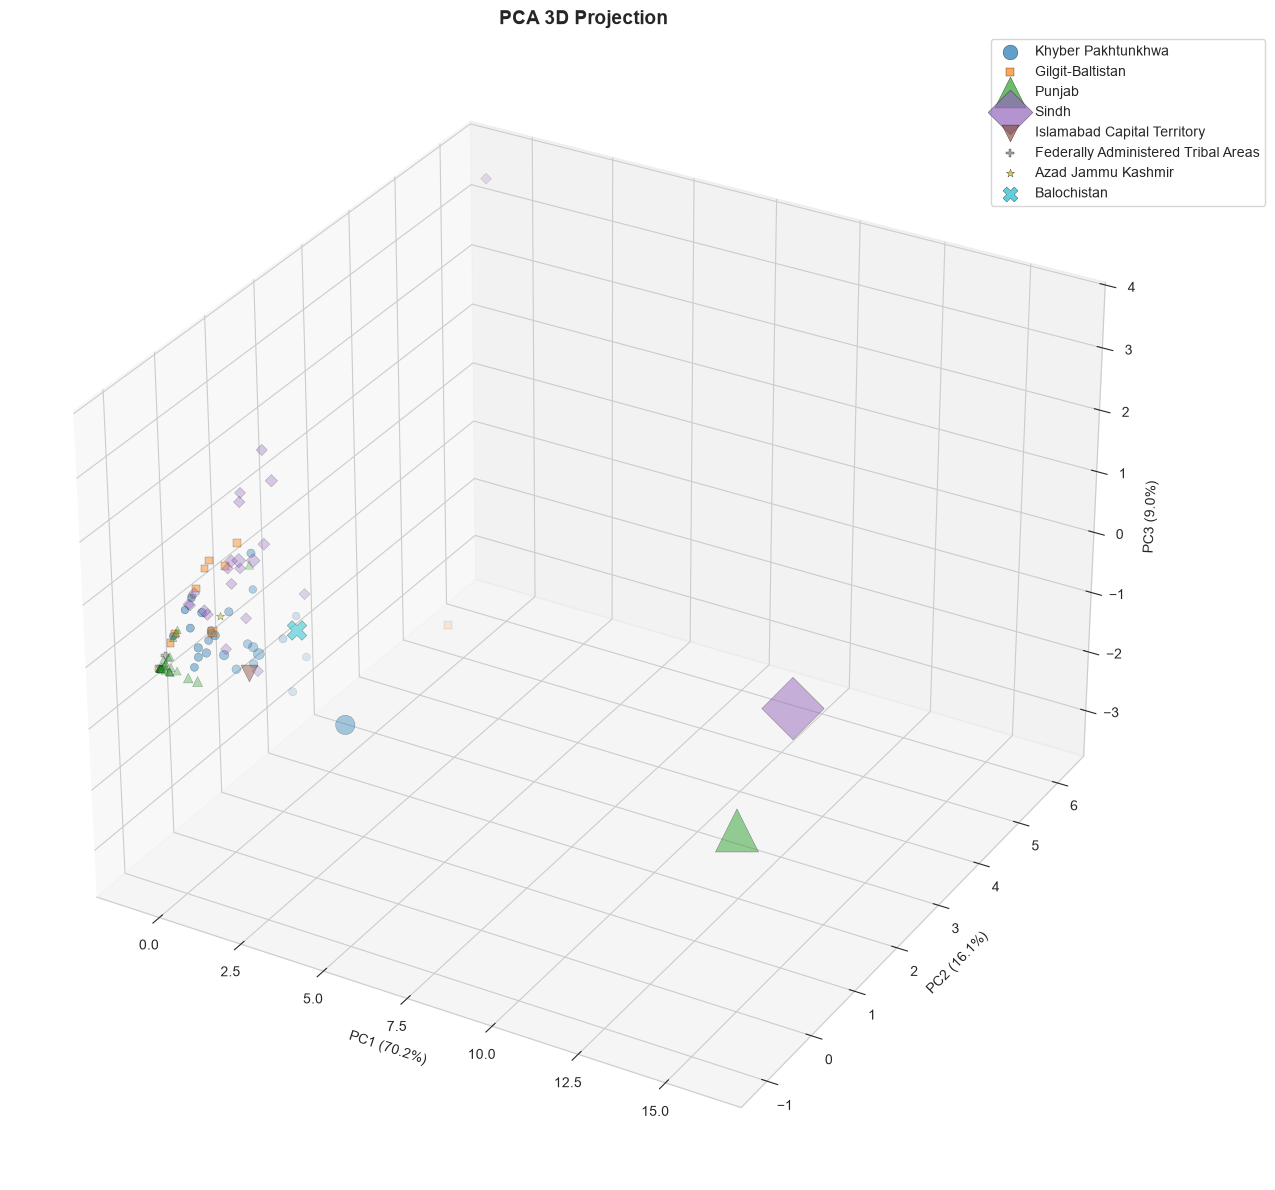

3D projection explains 95.39% of the variance


In [64]:
pca_3d = PCA(n_components=3, random_state=42)
X_pc3 = pca_3d.fit_transform(X_sc)
pc3_df = pd.DataFrame(X_pc3, columns=["PC1", "PC2", "PC3"])
for col, src in [("City", "City"), ("Province", "Province"), ("Cases", "Total_Cases"), ("CFR", "CFR")]:
    pc3_df[col] = pcity[src].values

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection="3d")
for i, prov in enumerate(provs_pca):
    sub = pc3_df[pc3_df["Province"] == prov]
    ax.scatter(sub["PC1"], sub["PC2"], sub["PC3"], c=[PC_COLORS[i]], marker=PC_MARKERS[i % len(PC_MARKERS)], s=sub["Cases"] / 30 + 30, alpha=0.7,
               edgecolors="black", linewidth=0.3, label=prov)
ax.set_xlabel(f"PC1 ({pca_3d.explained_variance_ratio_[0] * 100:.1f}%)"); ax.set_ylabel(f"PC2 ({pca_3d.explained_variance_ratio_[1] * 100:.1f}%)")
ax.set_zlabel(f"PC3 ({pca_3d.explained_variance_ratio_[2] * 100:.1f}%)")
ax.set_title("PCA 3D Projection", fontsize=14, fontweight="bold"); ax.legend(bbox_to_anchor=(1.1, 1))
plt.tight_layout()
save_pca("pca_3d.png")
plt.show()
print(f"3D projection explains {pca_3d.explained_variance_ratio_.sum() * 100:.2f}% of the variance")

## C16. Interactive 3D (Plotly)

In [65]:
if HAS_PLOTLY:
    fig = px.scatter_3d(pc3_df, x="PC1", y="PC2", z="PC3", color="Province", size=pc3_df["Cases"].clip(lower=1), hover_name="City", hover_data=["CFR", "Cases"],
                        title=f"Interactive 3D PCA (explains {pca_3d.explained_variance_ratio_.sum() * 100:.1f}% of variance)")
    fig.update_layout(height=800)
    if SAVE_OUTPUTS:
        fig.write_html(OUT_PCA / "pca_3d_interactive.html", include_plotlyjs="cdn")
    try:
        fig.show()
    except ValueError as e:
        print("Plotly chart could not be shown inside the notebook:", e)
        print("Run 'pip install nbformat', or open outputs/pca/pca_3d_interactive.html in your browser.")
else:
    print("plotly is not installed: run 'pip install plotly' to enable the interactive chart.")

Plotly chart could not be shown inside the notebook: Mime type rendering requires nbformat>=4.2.0 but it is not installed
Run 'pip install nbformat', or open outputs/pca/pca_3d_interactive.html in your browser.


## C17. K-Means in PC Space

Silhouette score (K = 3 in PC space): 0.8046


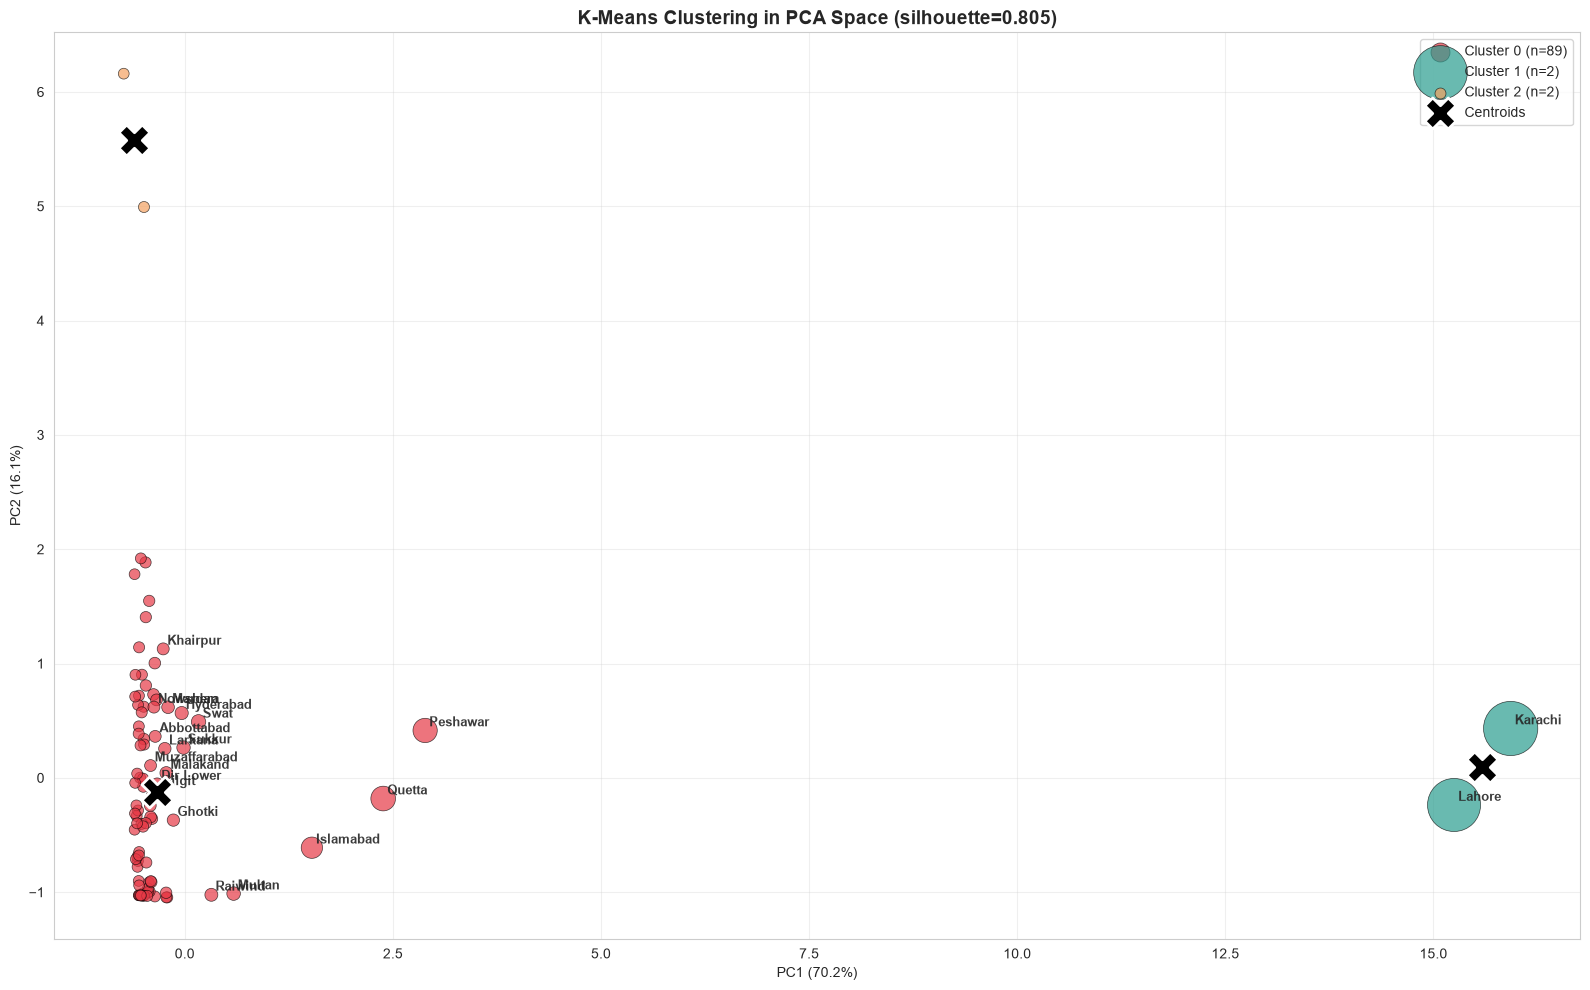


Cluster profiles (original features, mean):
             Total_Cases  Total_Deaths  Total_Recovered  Total_Active    CFR  Recovery_Rate  Avg_Daily_Cases  Max_Daily_Cases
PCA_Cluster                                                                                                                  
0                 296.79          7.09            84.27        205.43   1.71          32.66             9.10            44.46
1               28680.50        540.00          8550.50      19590.00   1.89          29.45           329.79          1563.00
2                  41.00          7.50            53.50        -20.00  13.99         218.00             1.74            10.00

Biggest cities in each cluster:
  Cluster 0: Quetta, Peshawar, Islamabad, Swat, Multan
  Cluster 1: Karachi, Lahore
  Cluster 2: Astore, Matiari


In [66]:
kmeans_pca = KMeans(n_clusters=3, init="k-means++", n_init=20, random_state=42)
pc_df["Cluster"] = kmeans_pca.fit_predict(pc_df[["PC1", "PC2"]])
sil_k3 = silhouette_score(pc_df[["PC1", "PC2"]], pc_df["Cluster"])
print(f"Silhouette score (K = 3 in PC space): {sil_k3:.4f}")

fig, ax = plt.subplots(figsize=(16, 10))
for c_ in range(3):
    sub = pc_df[pc_df["Cluster"] == c_]
    ax.scatter(sub["PC1"], sub["PC2"], c=PCA_CLUSTER_COLORS[c_], s=sub["Cases"] / 20 + 60, alpha=0.7, edgecolors="black", linewidth=0.5, label=f"Cluster {c_} (n={len(sub)})")
cent = kmeans_pca.cluster_centers_
ax.scatter(cent[:, 0], cent[:, 1], marker="X", s=500, c="black", edgecolors="white", linewidth=2, label="Centroids", zorder=10)
for _, row in pc_df.nlargest(20, "Cases").iterrows():
    ax.annotate(row["City"], (row["PC1"], row["PC2"]), fontsize=9, fontweight="bold", alpha=0.9, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.1f}%)"); ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.1f}%)")
ax.set_title(f"K-Means Clustering in PCA Space (silhouette={sil_k3:.3f})", fontsize=14, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
save_pca("pca_kmeans.png")
plt.show()

pcity["PCA_Cluster"] = pc_df["Cluster"].values
print("\nCluster profiles (original features, mean):")
print(pcity.groupby("PCA_Cluster")[feats].mean().round(2).to_string())
print("\nBiggest cities in each cluster:")
for c_ in range(3):
    print(f"  Cluster {c_}: " + ", ".join(pcity[pcity.PCA_Cluster == c_].nlargest(5, "Total_Cases")["City"]))

## C18. Clustering With and Without PCA

In [67]:
kmeans_orig = KMeans(n_clusters=3, n_init=20, random_state=42)
pcity["Orig_Cluster"] = kmeans_orig.fit_predict(X_sc)
print("Cluster agreement (rows = original features, columns = PCA space):")
print(pd.crosstab(pcity["Orig_Cluster"], pcity["PCA_Cluster"]))
sil_orig = silhouette_score(X_sc, pcity["Orig_Cluster"])
sil_pca = silhouette_score(pc_df[["PC1", "PC2"]], pc_df["Cluster"])
ari = adjusted_rand_score(pcity["Orig_Cluster"], pcity["PCA_Cluster"])
print(f"\nSilhouette, original features: {sil_orig:.4f}\nSilhouette, PCA features: {sil_pca:.4f}\nAdjusted Rand index between the two clusterings: {ari:.3f}")
print("The silhouettes are computed in different spaces (8 dimensions vs 2), so compare them with care; the Rand index shows how similar the groupings are.")

Cluster agreement (rows = original features, columns = PCA space):
PCA_Cluster    0  1  2
Orig_Cluster          
0              6  0  2
1             83  0  0
2              0  2  0

Silhouette, original features: 0.5970
Silhouette, PCA features: 0.8046
Adjusted Rand index between the two clusterings: 0.521
The silhouettes are computed in different spaces (8 dimensions vs 2), so compare them with care; the Rand index shows how similar the groupings are.


## C19. Temporal PCA (Daily Data)

Daily PCA: variance explained
  PC1:  79.44% (cumulative  79.44%)
  PC2:   8.85% (cumulative  88.28%)
  PC3:   6.66% (cumulative  94.94%)
  PC4:   2.70% (cumulative  97.64%)
  PC5:   1.06% (cumulative  98.70%)
  PC6:   0.93% (cumulative  99.63%)
  PC7:   0.37% (cumulative 100.00%)
  PC8:   0.00% (cumulative 100.00%)
  PC9:   0.00% (cumulative 100.00%)


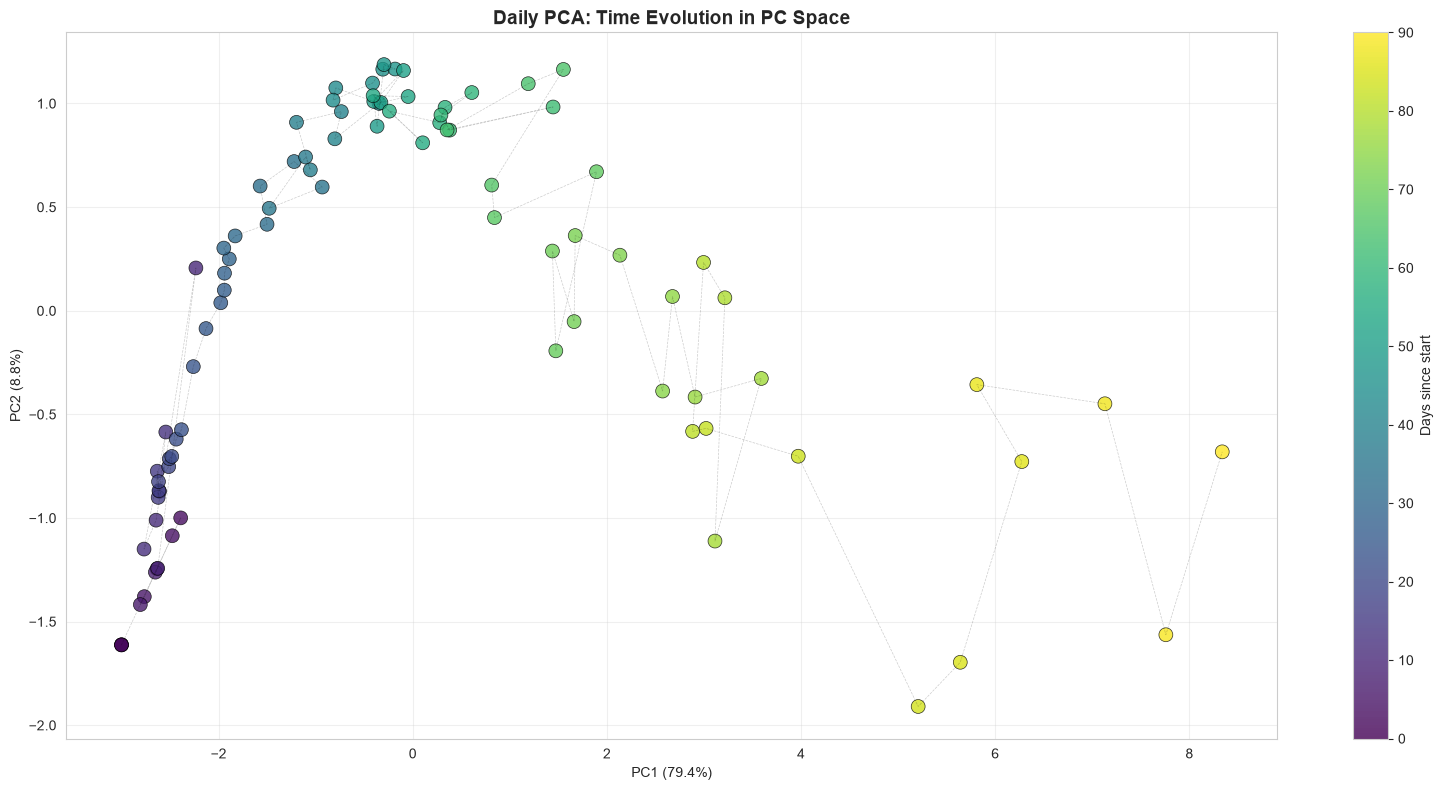

Most of the daily structure is one dimension: PC1 = 79%. The cumulative columns grow every day, so PC1 is essentially 'how far into the outbreak we are'.


In [68]:
daily_features = ["Cases", "Deaths", "Recovered", "Active", "Cumulative_Cases", "Cumulative_Deaths", "Cumulative_Recovered", "CFR", "Recovery_Rate"]
scaler_daily = StandardScaler()
X_daily_scaled = scaler_daily.fit_transform(pdaily[daily_features])
pca_daily = PCA(random_state=42).fit(X_daily_scaled)
daily_var = pca_daily.explained_variance_ratio_
daily_cum = np.cumsum(daily_var)
print("Daily PCA: variance explained")
for i, (v, c_) in enumerate(zip(daily_var, daily_cum)):
    print(f"  PC{i + 1}: {v * 100:6.2f}% (cumulative {c_ * 100:6.2f}%)")
daily_pca_df = pd.DataFrame(pca_daily.transform(X_daily_scaled)[:, :2], columns=["PC1", "PC2"])
daily_pca_df["Date"] = pdaily["Date"].values
daily_pca_df["Cases"] = pdaily["Cases"].values
daily_pca_df["Month"] = pdaily["Date"].dt.strftime("%b").values

fig, ax = plt.subplots(figsize=(16, 8))
sc_ = ax.scatter(daily_pca_df["PC1"], daily_pca_df["PC2"], c=np.arange(len(daily_pca_df)), cmap="viridis", s=100, edgecolors="black", linewidth=0.5, alpha=0.8)
ax.plot(daily_pca_df["PC1"], daily_pca_df["PC2"], "k--", alpha=0.2, linewidth=0.5)
ax.set_xlabel(f"PC1 ({daily_var[0] * 100:.1f}%)"); ax.set_ylabel(f"PC2 ({daily_var[1] * 100:.1f}%)")
ax.set_title("Daily PCA: Time Evolution in PC Space", fontsize=14, fontweight="bold"); ax.grid(alpha=0.3)
plt.colorbar(sc_, label="Days since start")
plt.tight_layout()
save_pca("pca_temporal.png")
plt.show()
print(f"Most of the daily structure is one dimension: PC1 = {daily_var[0] * 100:.0f}%. The cumulative columns grow every day, so PC1 is essentially 'how far into the outbreak we are'.")

## C20. Kernel PCA (Non-linear)

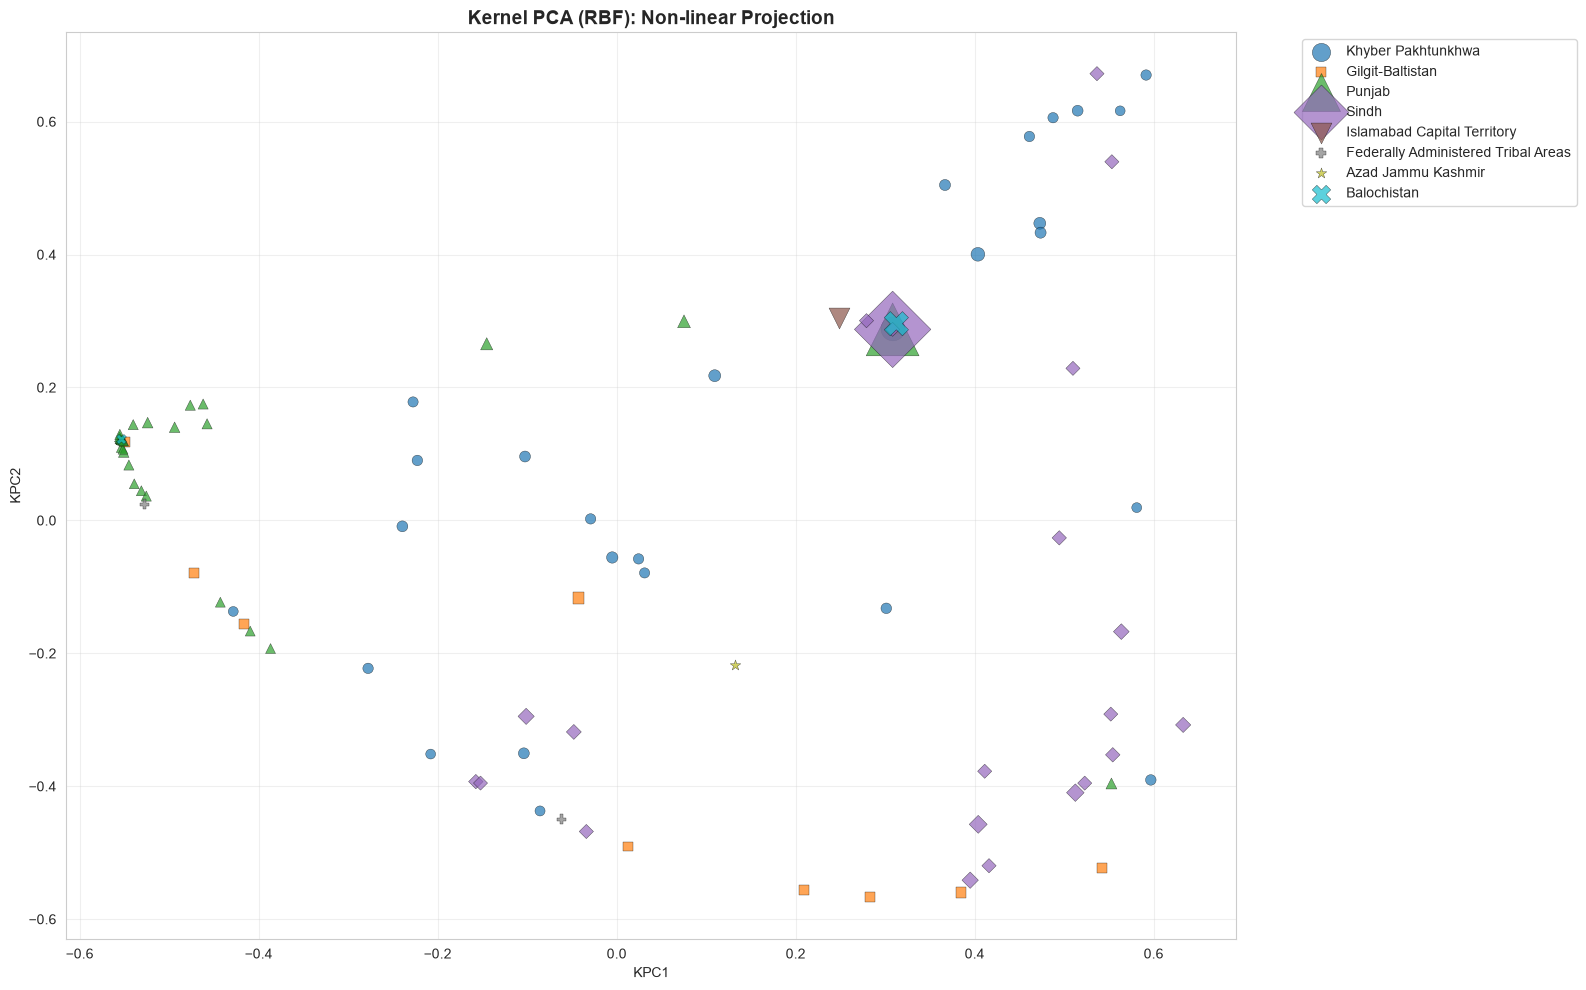

Kernel PCA has no loadings or variance percentage, so it is harder to interpret; gamma = 0.5 is a fixed choice, not tuned.


In [69]:
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=0.5, random_state=42)
X_kpca = kpca.fit_transform(X_sc)
kpca_df = pd.DataFrame(X_kpca, columns=["KPC1", "KPC2"])
for col, src in [("City", "City"), ("Province", "Province"), ("Cases", "Total_Cases")]:
    kpca_df[col] = pcity[src].values
fig, ax = plt.subplots(figsize=(16, 10))
for i, prov in enumerate(provs_pca):
    sub = kpca_df[kpca_df["Province"] == prov]
    ax.scatter(sub["KPC1"], sub["KPC2"], c=[PC_COLORS[i]], marker=PC_MARKERS[i % len(PC_MARKERS)], s=sub["Cases"] / 20 + 50, alpha=0.7, edgecolors="black", linewidth=0.3, label=prov)
ax.set_xlabel("KPC1"); ax.set_ylabel("KPC2")
ax.set_title("Kernel PCA (RBF): Non-linear Projection", fontsize=14, fontweight="bold"); ax.legend(bbox_to_anchor=(1.05, 1)); ax.grid(alpha=0.3)
plt.tight_layout()
save_pca("pca_kernel.png")
plt.show()
print("Kernel PCA has no loadings or variance percentage, so it is harder to interpret; gamma = 0.5 is a fixed choice, not tuned.")

## C21. PCA vs t-SNE

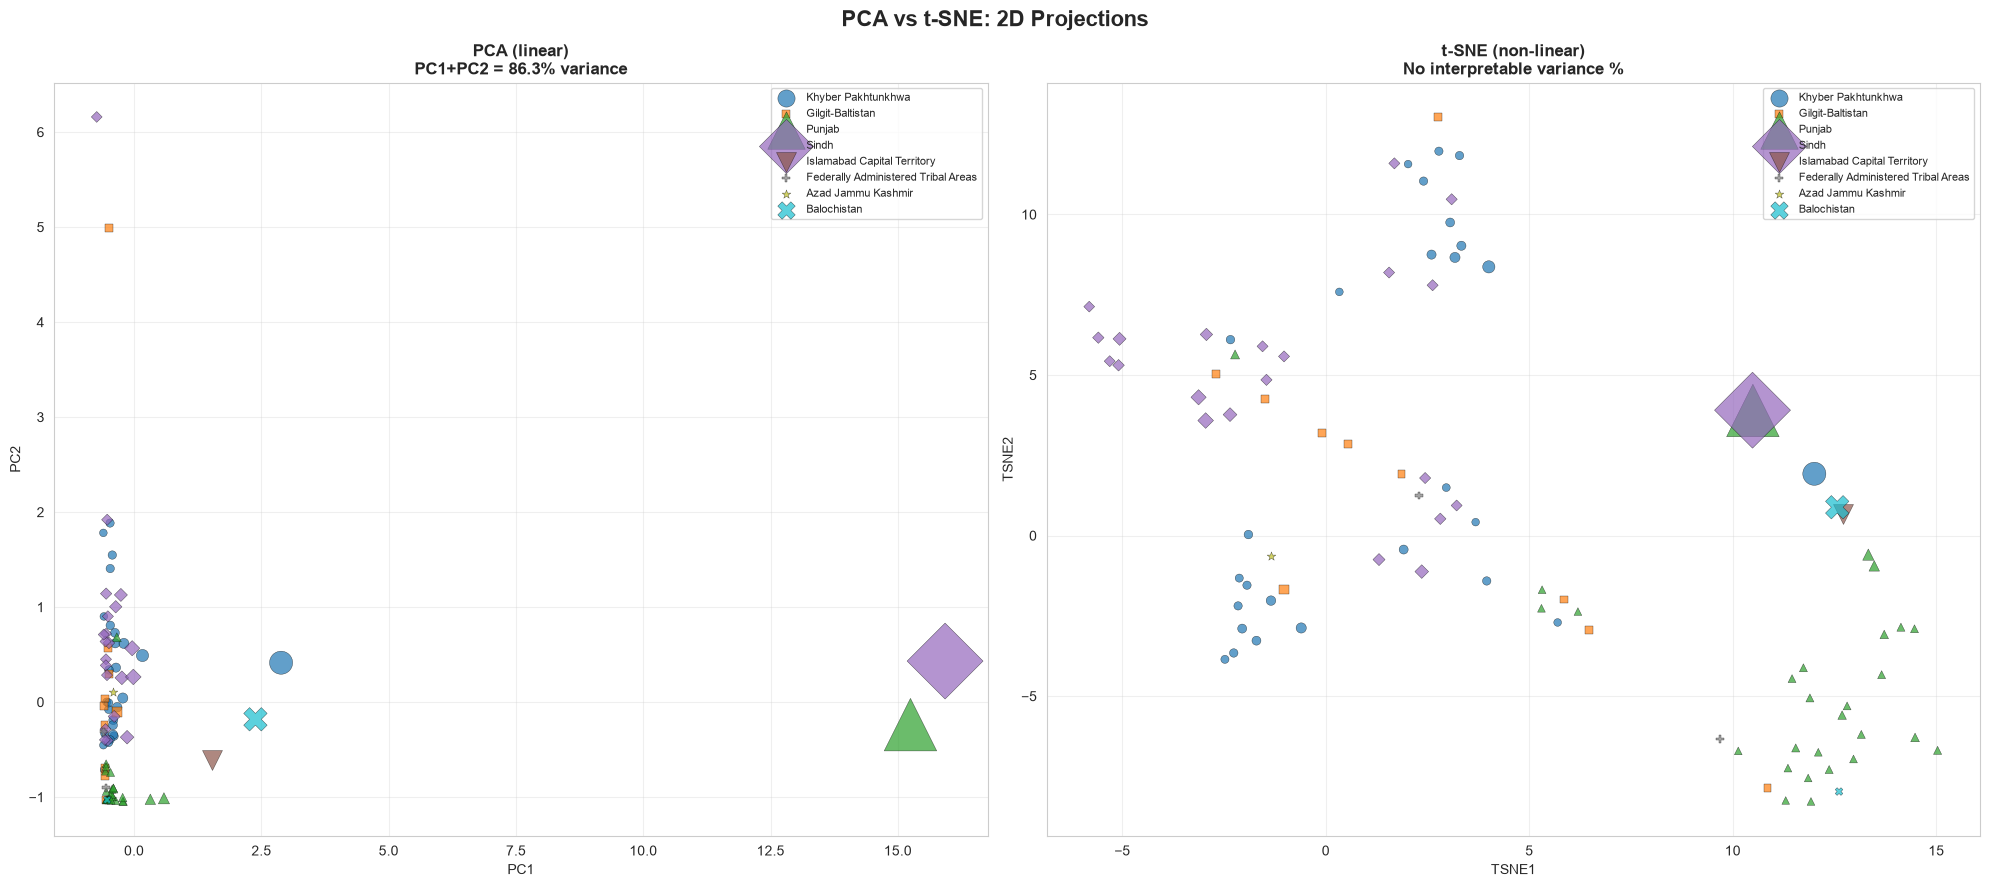

Nearest-neighbour preservation (k=5): PCA 0.57 | t-SNE 0.80


In [70]:
perp = float(min(15, max(2, (len(X_sc) - 1) / 3 - 1)))
try:
    tsne = TSNE(n_components=2, random_state=42, perplexity=perp, max_iter=1000)       # scikit-learn >= 1.5
except TypeError:
    tsne = TSNE(n_components=2, random_state=42, perplexity=perp, n_iter=1000)         # older versions
X_tsne = tsne.fit_transform(X_sc)
tsne_df = pd.DataFrame(X_tsne, columns=["TSNE1", "TSNE2"])
for col, src in [("City", "City"), ("Province", "Province"), ("Cases", "Total_Cases")]:
    tsne_df[col] = pcity[src].values
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, d, x, y, ttl in [(axes[0], pc_df, "PC1", "PC2", f"PCA (linear)\nPC1+PC2 = {pca_2d.explained_variance_ratio_.sum() * 100:.1f}% variance"),
                         (axes[1], tsne_df, "TSNE1", "TSNE2", "t-SNE (non-linear)\nNo interpretable variance %")]:
    for i, prov in enumerate(provs_pca):
        sub = d[d["Province"] == prov]
        ax.scatter(sub[x], sub[y], c=[PC_COLORS[i]], marker=PC_MARKERS[i % len(PC_MARKERS)], s=sub["Cases"] / 20 + 30, alpha=0.7, edgecolors="black", linewidth=0.3, label=prov)
    ax.set_title(ttl, fontweight="bold"); ax.set_xlabel(x); ax.set_ylabel(y); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.suptitle("PCA vs t-SNE: 2D Projections", fontsize=16, fontweight="bold")
plt.tight_layout()
save_pca("pca_vs_tsne.png")
plt.show()

# How well does each 2D map preserve the neighbourhoods of the 8-dimensional data? (share of the 5 nearest neighbours kept)
from sklearn.neighbors import NearestNeighbors
def neighbour_overlap(Xhigh, Xlow, k=5):
    a = NearestNeighbors(n_neighbors=k + 1).fit(Xhigh).kneighbors(Xhigh, return_distance=False)[:, 1:]
    b = NearestNeighbors(n_neighbors=k + 1).fit(Xlow).kneighbors(Xlow, return_distance=False)[:, 1:]
    return np.mean([len(set(x) & set(y)) / k for x, y in zip(a, b)])
print(f"Nearest-neighbour preservation (k=5): PCA {neighbour_overlap(X_sc, X_pc2):.2f} | t-SNE {neighbour_overlap(X_sc, X_tsne):.2f}")

## C22. Other Dimensionality-Reduction Methods

Isomap, Locally Linear Embedding, ICA, NMF, Incremental PCA and (if installed) UMAP, all on the same standardised city data.

UMAP is not installed (pip install umap-learn): skipped.


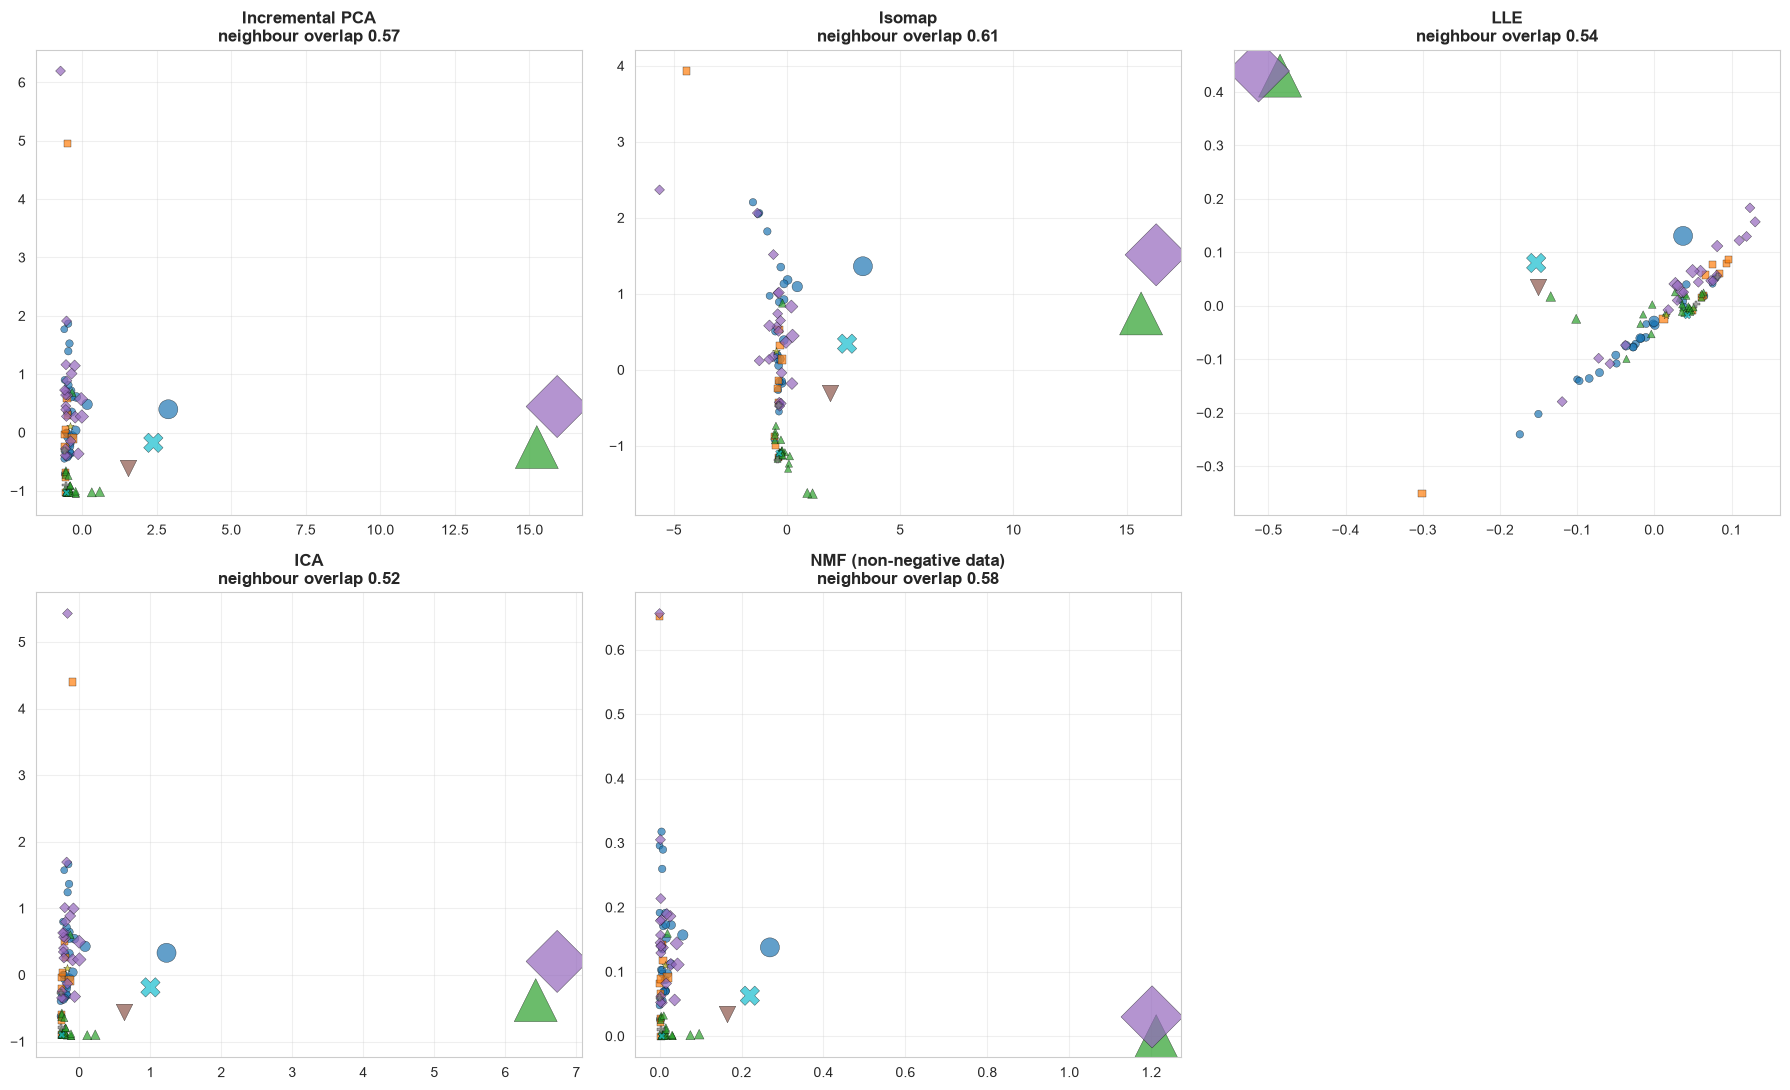

Incremental PCA reproduces PCA (it fits in batches, useful for data that does not fit in memory). Isomap and LLE follow curved structure; ICA finds independent sources; NMF needs non-negative data (min-max scaled here).
Largest difference between Incremental PCA and PCA scores (ignoring sign): 0.036


In [71]:
nn = min(10, len(X_sc) - 1)
methods = {}
methods["Incremental PCA"] = IncrementalPCA(n_components=2, batch_size=max(10, len(X_sc) // 3)).fit_transform(X_sc)
methods["Isomap"] = Isomap(n_neighbors=nn, n_components=2).fit_transform(X_sc)
methods["LLE"] = LocallyLinearEmbedding(n_neighbors=nn, n_components=2, random_state=42).fit_transform(X_sc)
methods["ICA"] = FastICA(n_components=2, random_state=42, max_iter=1000).fit_transform(X_sc)
methods["NMF (non-negative data)"] = NMF(n_components=2, init="nndsvda", random_state=42, max_iter=1000).fit_transform(MinMaxScaler().fit_transform(X_pcafeat))
if HAS_UMAP:
    methods["UMAP"] = umap.UMAP(n_components=2, n_neighbors=nn, random_state=42).fit_transform(X_sc)
else:
    print("UMAP is not installed (pip install umap-learn): skipped.")
n_m = len(methods)
fig, axes = plt.subplots(2, (n_m + 1) // 2, figsize=(6 * ((n_m + 1) // 2), 11))
axes = np.atleast_1d(axes).flatten()
for ax, (name, emb) in zip(axes, methods.items()):
    for i, prov in enumerate(provs_pca):
        m_ = (pcity["Province"] == prov).values
        ax.scatter(emb[m_, 0], emb[m_, 1], c=[PC_COLORS[i]], marker=PC_MARKERS[i % len(PC_MARKERS)], s=pcity["Total_Cases"].values[m_] / 30 + 25, alpha=0.7, edgecolors="black", linewidth=0.3)
    ax.set_title(f"{name}\nneighbour overlap {neighbour_overlap(X_sc, emb):.2f}", fontweight="bold"); ax.grid(alpha=0.3)
for ax in axes[n_m:]:
    ax.axis("off")
plt.tight_layout()
save_pca("pca_other_methods.png")
plt.show()
print("Incremental PCA reproduces PCA (it fits in batches, useful for data that does not fit in memory). Isomap and LLE follow curved structure; ICA finds independent sources; NMF needs non-negative data (min-max scaled here).")
inc_diff = np.abs(np.abs(methods["Incremental PCA"]) - np.abs(X_pc2)).max()
print(f"Largest difference between Incremental PCA and PCA scores (ignoring sign): {inc_diff:.3f}")

## C23. PCA vs LDA (Supervised vs Unsupervised)

The class is High CFR (> 2%). CFR is one of the features, so LDA on all features separates the classes almost trivially. The second LDA leaves CFR out to show a fairer picture.

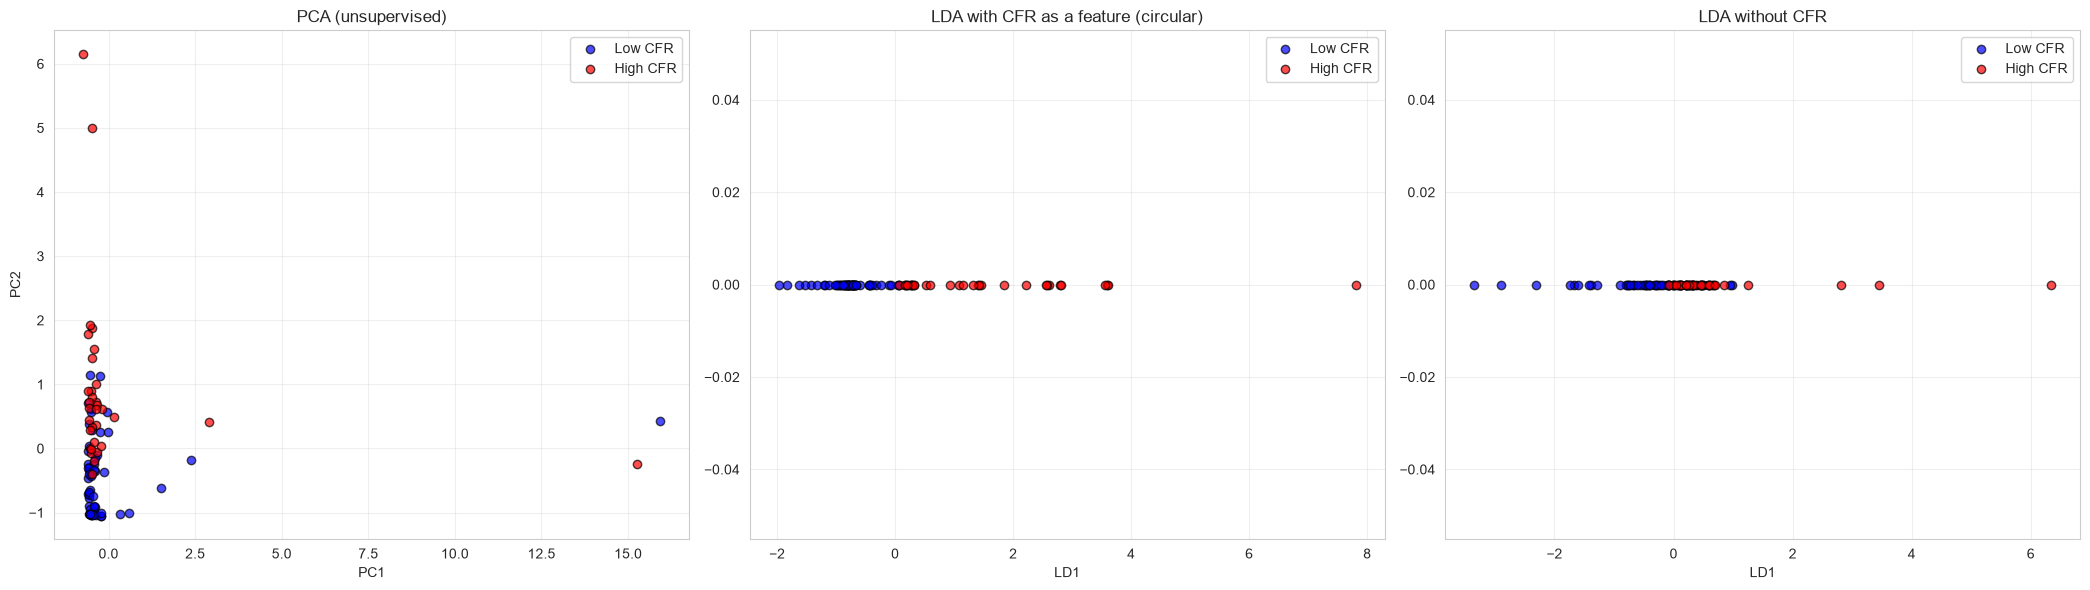

High-CFR cities: 32 of 93
LDA accuracy (training), all features: 84.95% | without CFR: 68.82% | majority-class baseline: 65.59%


In [72]:
y_class = (pcity["CFR"] > 2).astype(int)
if y_class.sum() > 5 and (1 - y_class).sum() > 5:
    lda = LDA(n_components=1)
    X_lda = lda.fit_transform(X_sc, y_class)
    no_cfr = [i for i, f in enumerate(feats) if f != "CFR"]
    lda2 = LDA(n_components=1)
    X_lda2 = lda2.fit_transform(X_sc[:, no_cfr], y_class)
    fig, axes = plt.subplots(1, 3, figsize=(21, 6))
    for k_, (lab, col) in enumerate([("Low CFR", "blue"), ("High CFR", "red")]):
        m_ = (y_class == k_).values
        axes[0].scatter(pc_df["PC1"][m_], pc_df["PC2"][m_], c=col, label=lab, alpha=0.7, edgecolors="black")
        axes[1].scatter(X_lda[m_, 0], np.zeros(m_.sum()), c=col, label=lab, alpha=0.7, edgecolors="black")
        axes[2].scatter(X_lda2[m_, 0], np.zeros(m_.sum()), c=col, label=lab, alpha=0.7, edgecolors="black")
    for ax, ttl, xl in zip(axes, ["PCA (unsupervised)", "LDA with CFR as a feature (circular)", "LDA without CFR"], ["PC1", "LD1", "LD1"]):
        ax.set_title(ttl); ax.set_xlabel(xl); ax.legend(); ax.grid(alpha=0.3)
    axes[0].set_ylabel("PC2")
    plt.tight_layout()
    save_pca("pca_vs_lda.png")
    plt.show()
    print(f"High-CFR cities: {int(y_class.sum())} of {len(y_class)}")
    print(f"LDA accuracy (training), all features: {lda.score(X_sc, y_class):.2%} | without CFR: {lda2.score(X_sc[:, no_cfr], y_class):.2%} | majority-class baseline: {max(y_class.mean(), 1 - y_class.mean()):.2%}")
else:
    print("Not enough cities in each CFR class for LDA.")

## C24. Reconstruction and Denoising

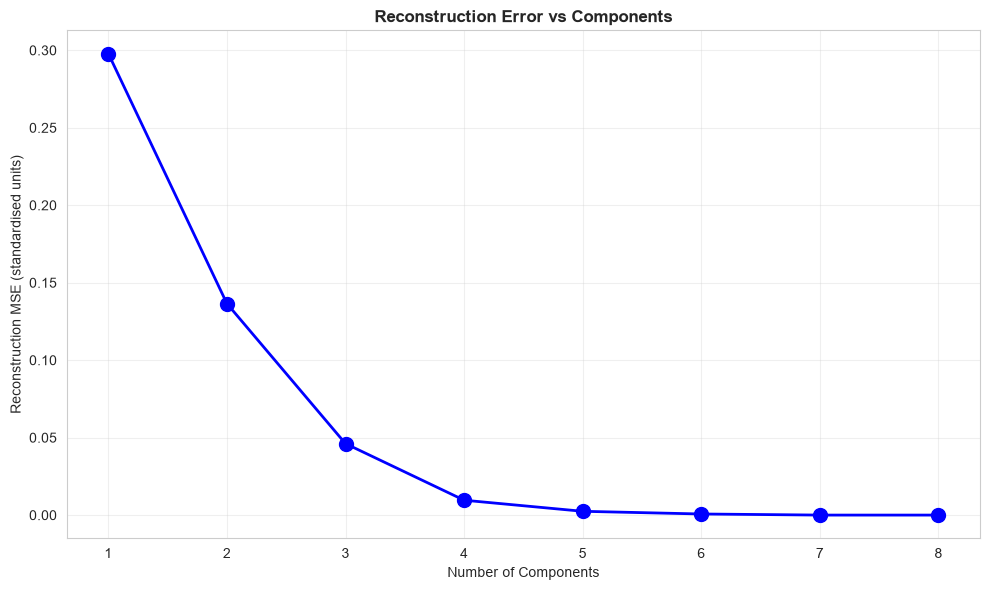

Reconstruction MSE by components:
  1 components: MSE = 0.297890
  2 components: MSE = 0.136509
  3 components: MSE = 0.046107
  4 components: MSE = 0.009599
  5 components: MSE = 0.002444
  6 components: MSE = 0.000700
  7 components: MSE = 0.000000
  8 components: MSE = 0.000000

With 2 components the average squared reconstruction error is 0.137 (the total variance per feature is 1.0), i.e. 13.7% of the information is lost.


In [73]:
components_range = list(range(1, len(feats) + 1))
reconstruction_errors = []
for n in components_range:
    p_n = PCA(n_components=n, random_state=42).fit(X_sc)
    reconstruction_errors.append(mean_squared_error(X_sc, p_n.inverse_transform(p_n.transform(X_sc))))
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(components_range, reconstruction_errors, "bo-", linewidth=2, markersize=10)
ax.set_xlabel("Number of Components"); ax.set_ylabel("Reconstruction MSE (standardised units)")
ax.set_title("Reconstruction Error vs Components", fontweight="bold"); ax.grid(alpha=0.3)
plt.tight_layout()
save_pca("pca_reconstruction.png")
plt.show()
print("Reconstruction MSE by components:")
for n, mse in zip(components_range, reconstruction_errors):
    print(f"  {n} components: MSE = {mse:.6f}")
mse_2 = reconstruction_errors[1]
print(f"\nWith 2 components the average squared reconstruction error is {mse_2:.3f} (the total variance per feature is 1.0), i.e. {mse_2 * 100:.1f}% of the information is lost.")

## C25. Feature Contributions to the Components

Feature contribution to each PC (%):
                   PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
Total_Cases      17.75   0.01   0.02   0.02   0.21  19.59   0.13  62.27
Total_Deaths     16.79   0.15   0.67   5.34  55.50  19.49   2.04   0.02
Total_Recovered  13.63   0.17   1.60  75.30   1.05   0.56   0.51   7.19
Total_Active     16.89   0.00   0.14  15.41   0.00  37.02   0.01  30.52
CFR               0.00  50.01  48.69   0.61   0.64   0.01   0.03   0.00
Recovery_Rate     0.05  49.55  48.83   1.54   0.00   0.03   0.00   0.00
Avg_Daily_Cases  17.61   0.06   0.03   0.30   7.29   9.25  65.46   0.00
Max_Daily_Cases  17.29   0.05   0.01   1.48  35.31  14.06  31.81   0.00


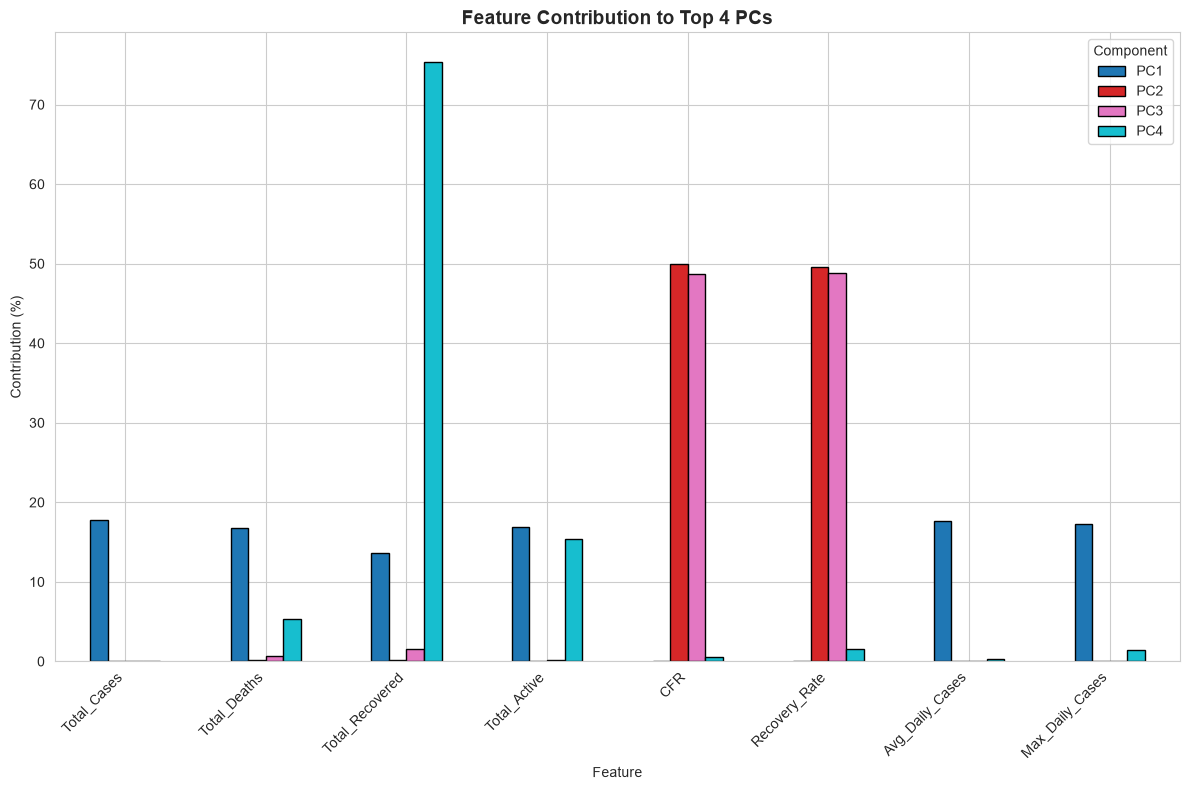

Contributions of each PC add to: [100.]


In [74]:
contribution_pct = (loadings_df ** 2).div((loadings_df ** 2).sum(axis=0), axis=1) * 100     # each column (PC) adds to 100%
print("Feature contribution to each PC (%):")
print(contribution_pct.round(2).to_string())
fig, ax = plt.subplots(figsize=(12, 8))
contribution_pct.iloc[:, :4].plot(kind="bar", ax=ax, colormap="tab10", edgecolor="black")
ax.set_title("Feature Contribution to Top 4 PCs", fontsize=14, fontweight="bold"); ax.set_xlabel("Feature"); ax.set_ylabel("Contribution (%)")
ax.legend(title="Component"); plt.xticks(rotation=45, ha="right")
plt.tight_layout()
save_pca("pca_contribution.png")
plt.show()
# Squared loadings of a PC add to 100% and, for a unit-length loading vector, equal the squared coefficient: check
print("Contributions of each PC add to:", contribution_pct.sum().round(1).unique())

## C26. Does the Scaling Choice Matter? Raw, Log and Winsorised

The guide standardises the raw counts. The counts are heavily right-skewed, so this section repeats the PCA after a log(1 + x) transform of the count features and after winsorising (capping) the 5% most extreme values, and compares variance explained and clustering.

        Version  PC1 %  PC2 %  PC1+PC2 %  Kaiser components  K=3 silhouette (2 PCs)  Smallest K=3 cluster                              Top PC1 features
    Raw (guide)  70.21  16.14      86.35                  2                    0.80                     2 Total_Cases, Avg_Daily_Cases, Max_Daily_Cases
Log(1+x) counts  57.35  23.70      81.05                  2                    0.40                     5    Total_Cases, Max_Daily_Cases, Total_Deaths
Winsorised 5/95  63.99  18.52      82.51                  2                    0.48                     5    Total_Cases, Total_Active, Max_Daily_Cases


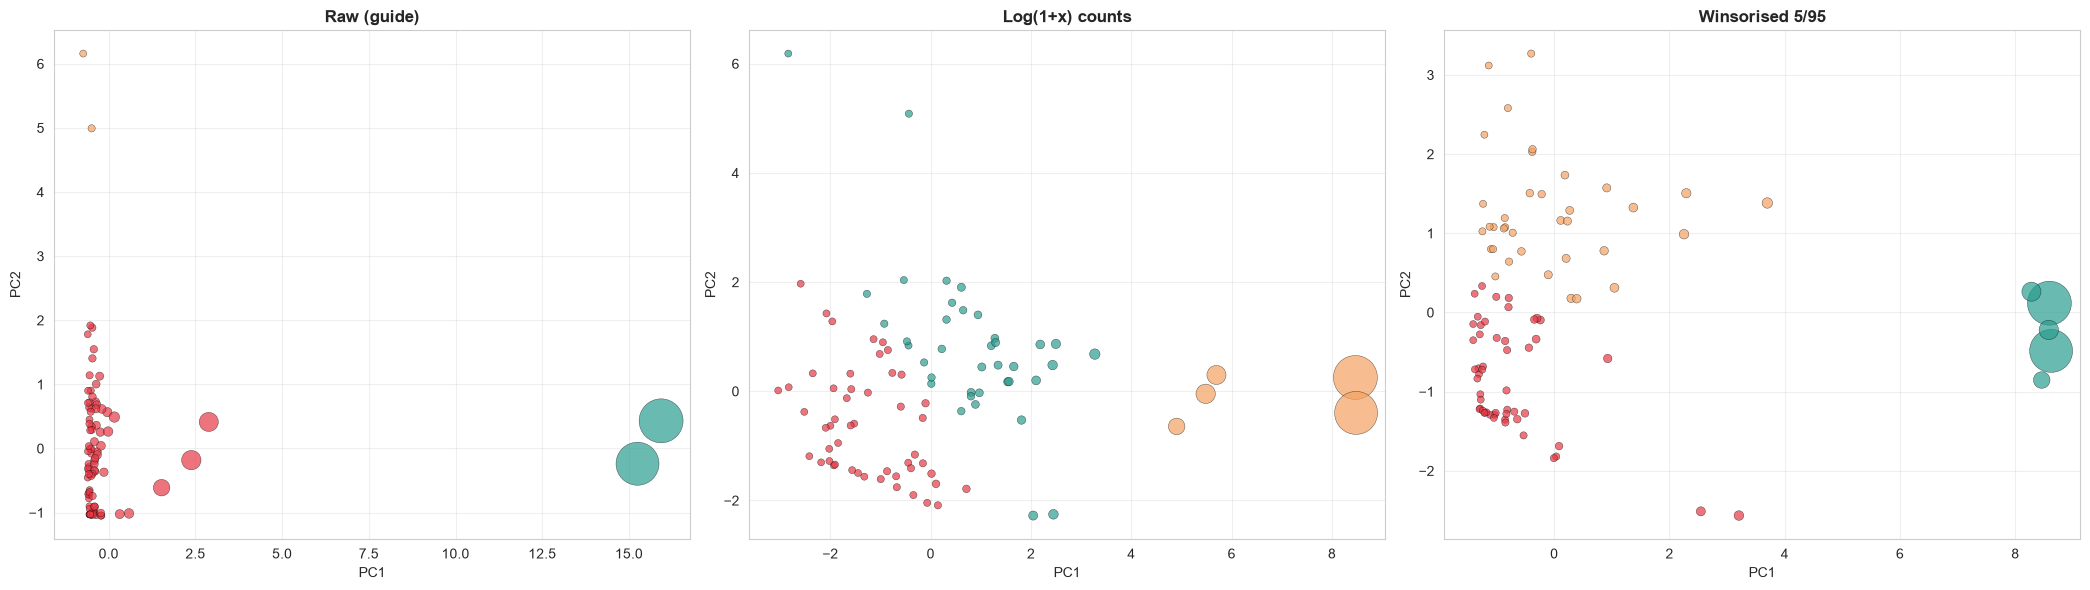

In [75]:
count_cols = ["Total_Cases", "Total_Deaths", "Total_Recovered", "Total_Active", "Avg_Daily_Cases", "Max_Daily_Cases"]
Xlog = X_pcafeat.copy(); Xlog[count_cols] = np.log1p(Xlog[count_cols].clip(lower=0))
Xwin = X_pcafeat.copy()
for col in feats:
    lo, hi = Xwin[col].quantile([0.05, 0.95]); Xwin[col] = Xwin[col].clip(lo, hi)
variants = {"Raw (guide)": X_pcafeat, "Log(1+x) counts": Xlog, "Winsorised 5/95": Xwin}
rows, embeds = [], {}
for name, Xv in variants.items():
    Xs = StandardScaler().fit_transform(Xv)
    p_ = PCA(random_state=42).fit(Xs)
    Z = p_.transform(Xs)[:, :2]
    lab = KMeans(n_clusters=3, n_init=20, random_state=42).fit_predict(Z)
    top_pc1 = pd.Series(p_.components_[0], index=feats).abs().sort_values(ascending=False).index[:3].tolist()
    rows.append({"Version": name, "PC1 %": p_.explained_variance_ratio_[0] * 100, "PC2 %": p_.explained_variance_ratio_[1] * 100, "PC1+PC2 %": p_.explained_variance_ratio_[:2].sum() * 100,
                 "Kaiser components": int((p_.explained_variance_ > 1).sum()), "K=3 silhouette (2 PCs)": silhouette_score(Z, lab), "Smallest K=3 cluster": int(np.bincount(lab).min()),
                 "Top PC1 features": ", ".join(top_pc1)})
    embeds[name] = (Z, lab)
cmp_df = pd.DataFrame(rows)
print(cmp_df.round(2).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (name, (Z, lab)) in zip(axes, embeds.items()):
    ax.scatter(Z[:, 0], Z[:, 1], c=[PCA_CLUSTER_COLORS[l] for l in lab], s=pcity["Total_Cases"] / 30 + 25, alpha=0.7, edgecolors="black", linewidth=0.3)
    ax.set_title(name, fontweight="bold"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.grid(alpha=0.3)
plt.tight_layout()
save_pca("pca_scaling_variants.png")
plt.show()

## C27. Anomaly Detection in PC Space

Two complementary scores from the 2-component model: Hotelling T2 (how far a city is from the centre inside the PC plane) and SPE (how much of the city the 2 components fail to describe).

T2 limit (chi-square 99%, df=2): 9.21 | SPE limit (95th percentile): 5.25

Top cities by T2 (unusual size/profile):
        City           Province  Total_Cases   CFR    T2   SPE                               Flag
     Karachi              Sindh        29346  1.70 44.82 13.46 far from centre | poorly described
      Lahore             Punjab        28015  2.08 40.99 12.61 far from centre | poorly described
     Matiari              Sindh           13  7.69 29.16 13.01 far from centre | poorly described
      Astore   Gilgit-Baltistan           69 20.29 19.14 10.98 far from centre | poorly described
       Other              Sindh           50  8.00  2.87  0.66                                   
       Kohat Khyber Pakhtunkhwa          118 10.17  2.76  3.38                                   
Lakki Marwat Khyber Pakhtunkhwa           12  8.33  2.49  1.22                                   
    Mansehra Khyber Pakhtunkhwa          137 10.22  1.87  4.84                                   

T

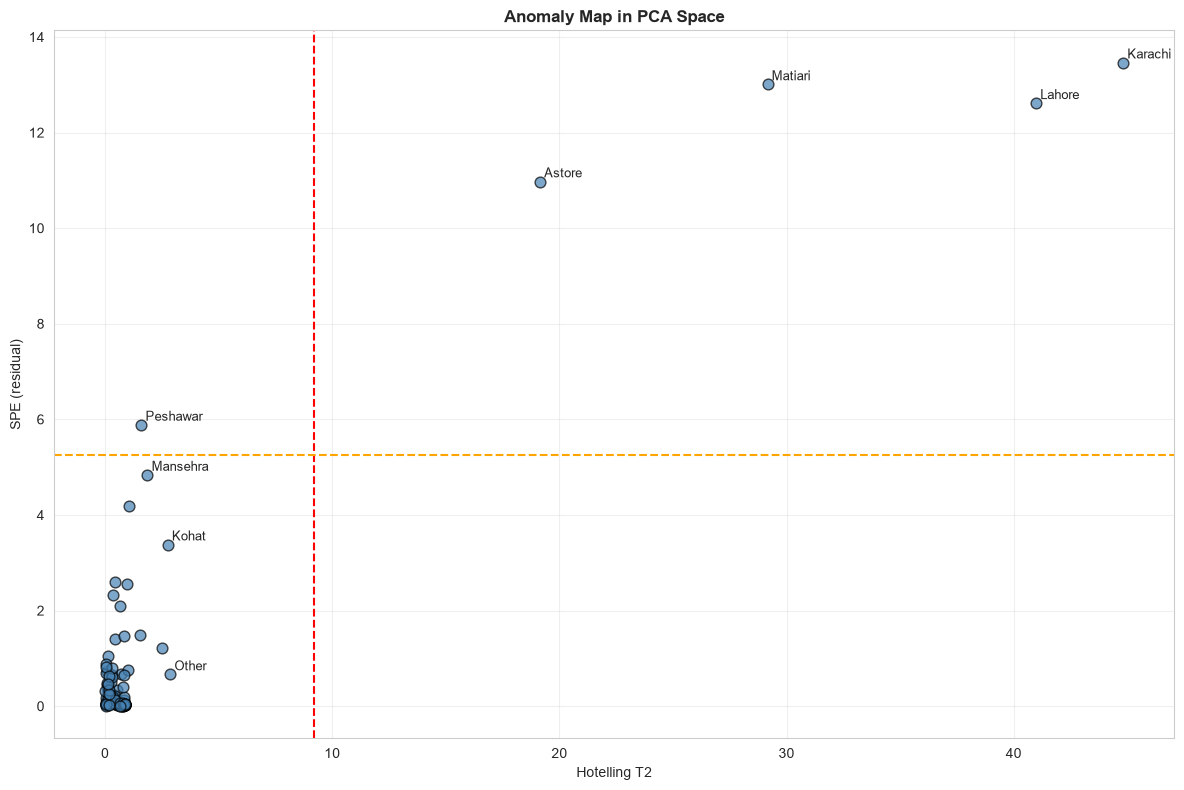

In [76]:
Z2 = pca_2d.transform(X_sc)
t2 = ((Z2 ** 2) / pca_2d.explained_variance_).sum(axis=1)
spe = ((X_sc - pca_2d.inverse_transform(Z2)) ** 2).sum(axis=1)
anom = pd.DataFrame({"City": pcity["City"], "Province": pcity["Province"], "Total_Cases": pcity["Total_Cases"], "CFR": pcity["CFR"].round(2),
                     "T2": t2, "SPE": spe})
t2_lim = chi2.ppf(0.99, 2)                              # approximate 99% limit for 2 components
spe_lim = np.percentile(spe, 95)
anom["Flag"] = np.where(anom["T2"] > t2_lim, "far from centre", "") + np.where(anom["SPE"] > spe_lim, " | poorly described", "")
print(f"T2 limit (chi-square 99%, df=2): {t2_lim:.2f} | SPE limit (95th percentile): {spe_lim:.2f}")
print("\nTop cities by T2 (unusual size/profile):")
print(anom.nlargest(8, "T2").round(2).to_string(index=False))
print("\nTop cities by SPE (profile not captured by PC1 and PC2):")
print(anom.nlargest(8, "SPE").round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(anom["T2"], anom["SPE"], s=60, c="steelblue", edgecolors="black", alpha=0.7)
ax.axvline(t2_lim, color="red", linestyle="--"); ax.axhline(spe_lim, color="orange", linestyle="--")
for _, r in pd.concat([anom.nlargest(6, "T2"), anom.nlargest(6, "SPE")]).drop_duplicates("City").iterrows():
    ax.annotate(r["City"], (r["T2"], r["SPE"]), fontsize=9, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Hotelling T2"); ax.set_ylabel("SPE (residual)"); ax.set_title("Anomaly Map in PCA Space", fontweight="bold"); ax.grid(alpha=0.3)
plt.tight_layout()
save_pca("pca_anomalies.png")
plt.show()

## C28. PCA Dashboard

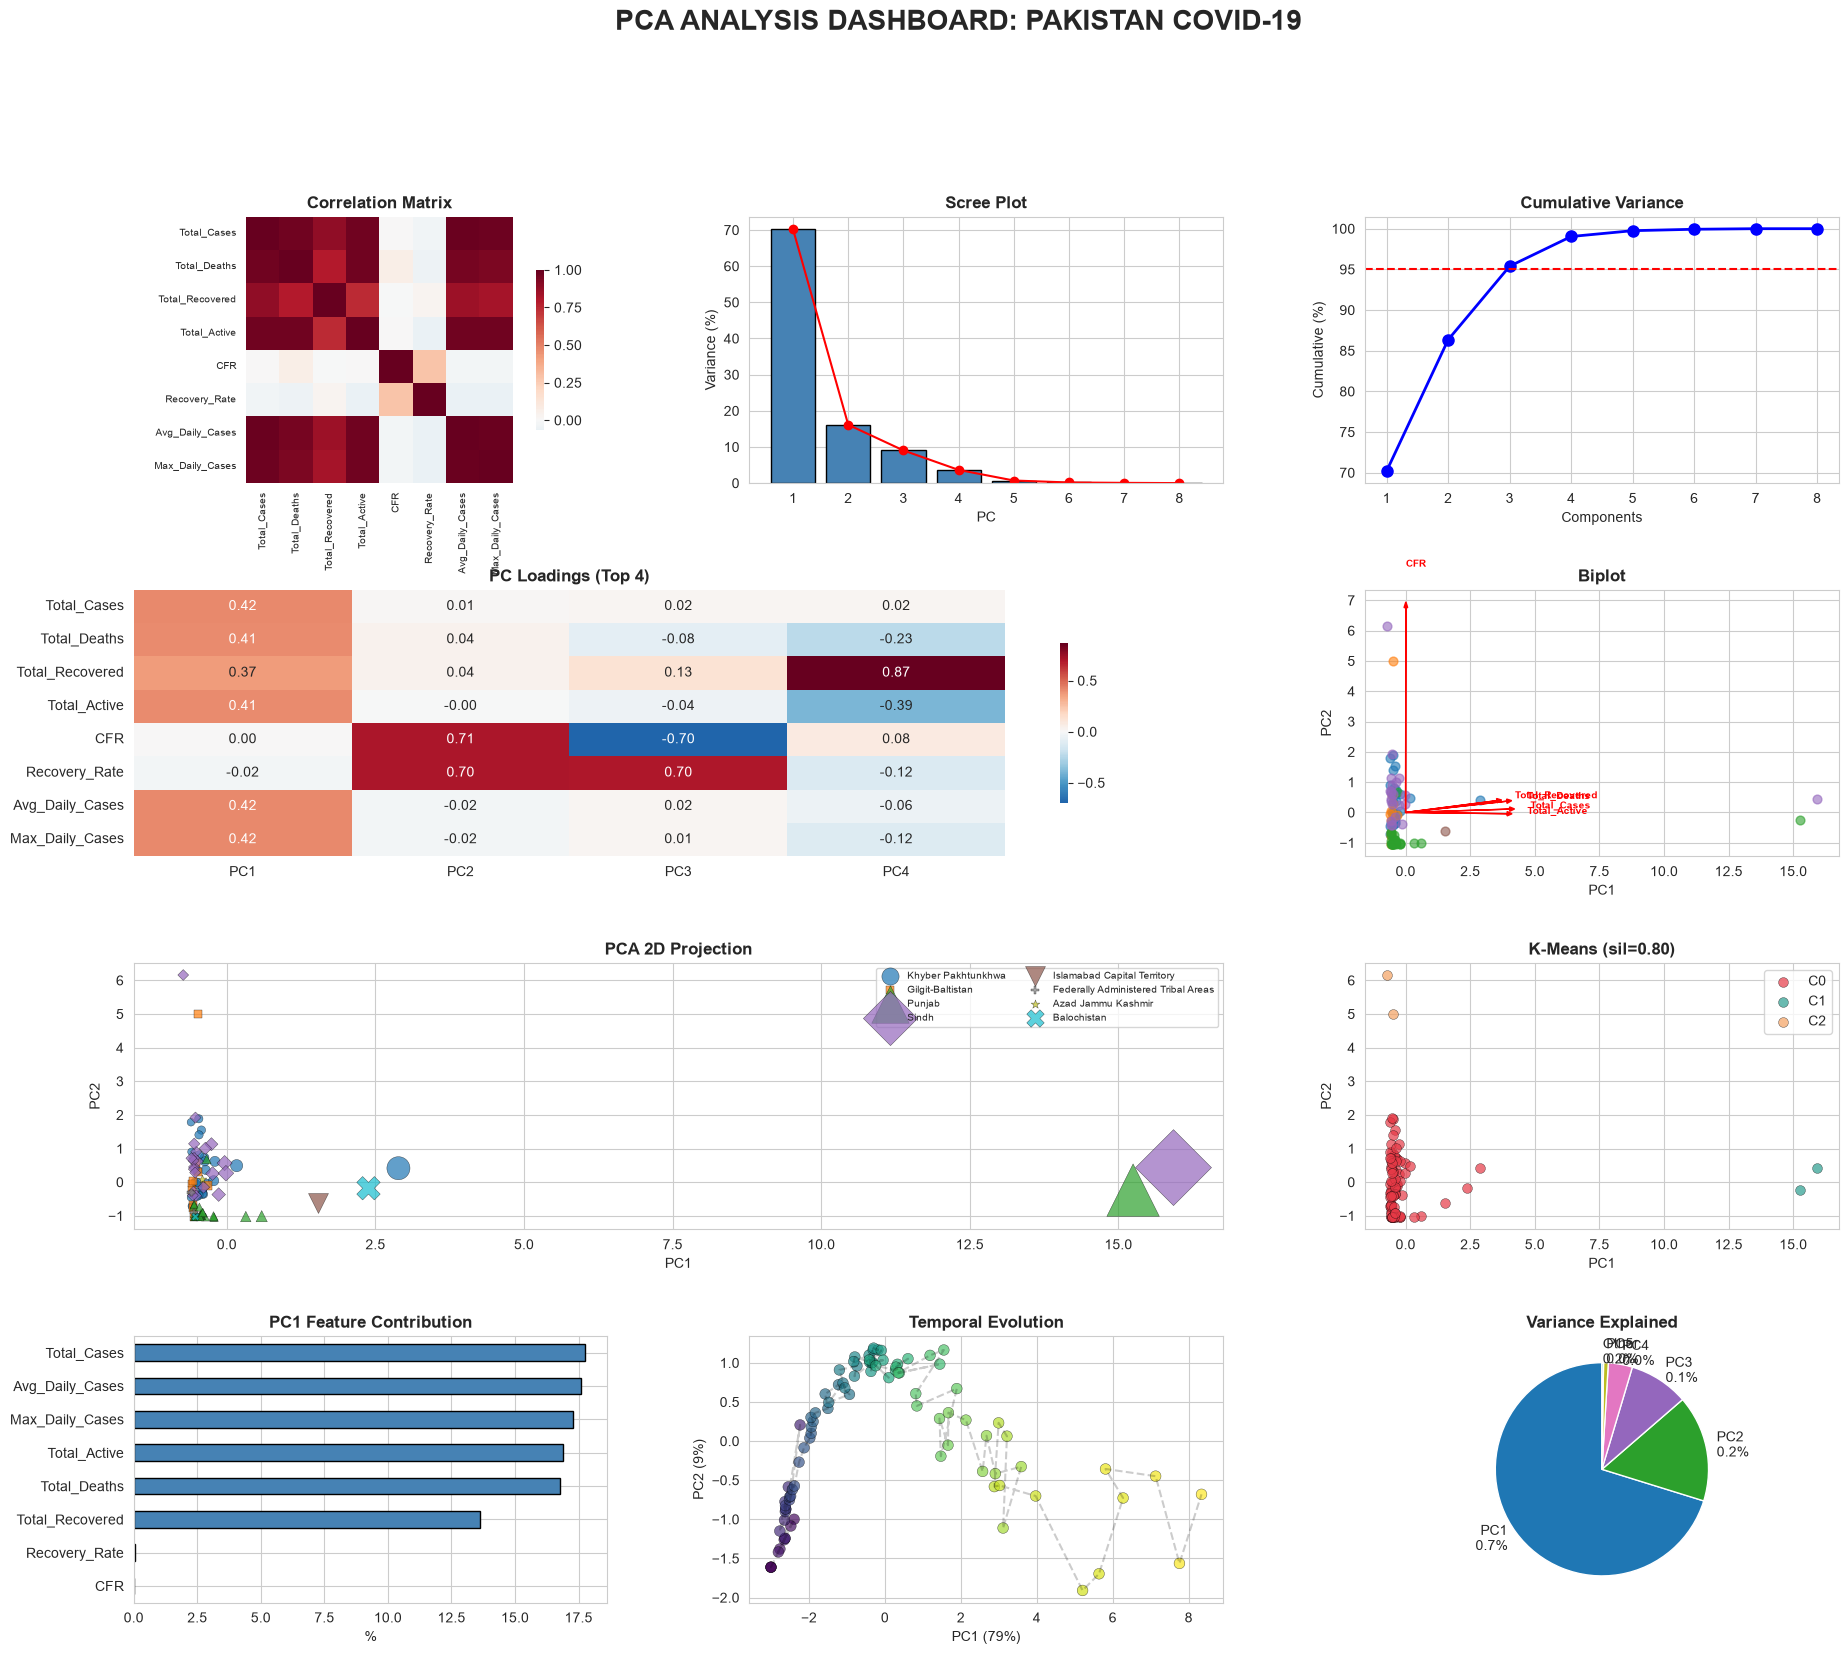

In [77]:
fig = plt.figure(figsize=(22, 18))
gs = fig.add_gridspec(4, 3, hspace=0.4, wspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
sns.heatmap(X_pcafeat.corr(), cmap="RdBu_r", center=0, ax=ax1, square=True, cbar_kws={"shrink": 0.6})
ax1.set_title("Correlation Matrix", fontweight="bold")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90, fontsize=7); ax1.set_yticklabels(ax1.get_yticklabels(), fontsize=7)

ax2 = fig.add_subplot(gs[0, 1])
ax2.bar(range(1, len(explained_var) + 1), explained_var * 100, color="steelblue", edgecolor="black")
ax2.plot(range(1, len(explained_var) + 1), explained_var * 100, "ro-")
ax2.set_title("Scree Plot", fontweight="bold"); ax2.set_xlabel("PC"); ax2.set_ylabel("Variance (%)")

ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(range(1, len(cumulative_var) + 1), cumulative_var * 100, "bo-", markersize=8, linewidth=2)
ax3.axhline(y=95, color="red", linestyle="--")
ax3.set_title("Cumulative Variance", fontweight="bold"); ax3.set_xlabel("Components"); ax3.set_ylabel("Cumulative (%)")

ax4 = fig.add_subplot(gs[1, :2])
sns.heatmap(loadings_df.iloc[:, :4], annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=False, ax=ax4, cbar_kws={"shrink": 0.6})
ax4.set_title("PC Loadings (Top 4)", fontweight="bold")

ax5 = fig.add_subplot(gs[1, 2])
for i, prov in enumerate(provs_pca[:5]):
    sub = pc_df[pc_df["Province"] == prov]
    ax5.scatter(sub["PC1"], sub["PC2"], c=[PC_COLORS[i]], alpha=0.6, s=40, label=prov)
sf = 0.6 * np.abs(X_pc2).max()
for i, feat in enumerate(feats[:5]):
    ax5.arrow(0, 0, loadings_2d[i, 0] * sf, loadings_2d[i, 1] * sf, head_width=sf * 0.015, head_length=sf * 0.02, fc="red", ec="red")
    ax5.text(loadings_2d[i, 0] * sf * 1.2, loadings_2d[i, 1] * sf * 1.2, feat, fontsize=7, color="red", fontweight="bold")
ax5.set_xlabel("PC1"); ax5.set_ylabel("PC2"); ax5.set_title("Biplot", fontweight="bold")

ax6 = fig.add_subplot(gs[2, :2])
for i, prov in enumerate(provs_pca):
    sub = pc_df[pc_df["Province"] == prov]
    ax6.scatter(sub["PC1"], sub["PC2"], c=[PC_COLORS[i]], marker=PC_MARKERS[i % len(PC_MARKERS)], s=sub["Cases"] / 20 + 30, alpha=0.7, edgecolors="black", linewidth=0.3, label=prov)
ax6.set_xlabel("PC1"); ax6.set_ylabel("PC2"); ax6.set_title("PCA 2D Projection", fontweight="bold"); ax6.legend(fontsize=7, ncol=2)

ax7 = fig.add_subplot(gs[2, 2])
for c_ in range(3):
    sub = pc_df[pc_df["Cluster"] == c_]
    ax7.scatter(sub["PC1"], sub["PC2"], c=PCA_CLUSTER_COLORS[c_], alpha=0.7, s=50, edgecolors="black", linewidth=0.3, label=f"C{c_}")
ax7.set_xlabel("PC1"); ax7.set_ylabel("PC2"); ax7.set_title(f"K-Means (sil={sil_k3:.2f})", fontweight="bold"); ax7.legend()

ax8 = fig.add_subplot(gs[3, 0])
contribution_pct["PC1"].sort_values(ascending=True).plot(kind="barh", ax=ax8, color="steelblue", edgecolor="black")
ax8.set_title("PC1 Feature Contribution", fontweight="bold"); ax8.set_xlabel("%")

ax9 = fig.add_subplot(gs[3, 1])
ax9.scatter(daily_pca_df["PC1"], daily_pca_df["PC2"], c=np.arange(len(daily_pca_df)), cmap="viridis", s=60, alpha=0.7, edgecolors="black", linewidth=0.3)
ax9.plot(daily_pca_df["PC1"], daily_pca_df["PC2"], "k--", alpha=0.2)
ax9.set_xlabel(f"PC1 ({daily_var[0] * 100:.0f}%)"); ax9.set_ylabel(f"PC2 ({daily_var[1] * 100:.0f}%)"); ax9.set_title("Temporal Evolution", fontweight="bold")

ax10 = fig.add_subplot(gs[3, 2])
top_pcs = explained_var[:5]
other = max(1 - top_pcs.sum(), 0)
ax10.pie(list(top_pcs * 100) + [other * 100], labels=[f"PC{i + 1}\n{v:.1f}%" for i, v in enumerate(top_pcs)] + [f"Other\n{other * 100:.1f}%"],
         startangle=90, colors=plt.cm.tab10(np.linspace(0, 1, 6)))
ax10.set_title("Variance Explained", fontweight="bold")

plt.suptitle("PCA ANALYSIS DASHBOARD: PAKISTAN COVID-19", fontsize=20, fontweight="bold", y=0.995)
save_pca("pca_dashboard.png")
plt.show()

## C29. Export Results

In [78]:
if SAVE_OUTPUTS:
    with pd.ExcelWriter(OUT_PCA / "PCA_Analysis_Report.xlsx", engine="openpyxl") as writer:
        pcity.to_excel(writer, sheet_name="City_Aggregates", index=False)
        pdaily.to_excel(writer, sheet_name="Daily", index=False)
        pprov.to_excel(writer, sheet_name="Province_Aggregates", index=False)
        pca_summary.to_excel(writer, sheet_name="Variance_Explained", index=False)
        loadings_df.to_excel(writer, sheet_name="PC_Loadings")
        boot_df.to_excel(writer, sheet_name="Loading_Bootstrap", index=False)
        pc_df.to_excel(writer, sheet_name="City_PCs", index=False)
        pcity[["City", "Province", "Total_Cases", "CFR", "PCA_Cluster"]].to_excel(writer, sheet_name="PCA_Clusters", index=False)
        contribution_pct.to_excel(writer, sheet_name="Contributions")
        daily_pca_df.to_excel(writer, sheet_name="Daily_PCA", index=False)
        cmp_df.to_excel(writer, sheet_name="Scaling_Variants", index=False)
        anom.to_excel(writer, sheet_name="Anomalies", index=False)
        pd.DataFrame({"Components": components_range, "Reconstruction_MSE": reconstruction_errors}).to_excel(writer, sheet_name="Reconstruction", index=False)
    print("Exported:", OUT_PCA / "PCA_Analysis_Report.xlsx")
    pc3_df.to_csv(OUT_PCA / "city_pca_coordinates.csv", index=False)
    print("Exported:", OUT_PCA / "city_pca_coordinates.csv", "(PC1, PC2, PC3 per city)")
else:
    print("SAVE_OUTPUTS is False: nothing exported.")

Exported: D:\DA projects\Covid-19-portfolio\outputs\pca\PCA_Analysis_Report.xlsx
Exported: D:\DA projects\Covid-19-portfolio\outputs\pca\city_pca_coordinates.csv (PC1, PC2, PC3 per city)


## C30. Interpretation (computed from your data)

In [79]:
print("=" * 70); print("KEY INSIGHTS"); print("=" * 70)
l1 = loadings_df["PC1"]; l2 = loadings_df["PC2"]; l3 = loadings_df["PC3"]
def top(l, k=3): return ", ".join(f"{f} ({v:+.2f})" for f, v in l.reindex(l.abs().sort_values(ascending=False).index)[:k].items())
size_feats = ["Total_Cases", "Total_Deaths", "Total_Recovered", "Avg_Daily_Cases", "Max_Daily_Cases", "Total_Active"]
print(f"1. PC1 explains {explained_var[0] * 100:.1f}% of the variance. Strongest loadings: {top(l1)}.")
print(f"   Share of PC1 coming from the six size features: {contribution_pct.loc[size_feats, 'PC1'].sum():.0f}% -> PC1 is the 'outbreak size' axis."
      if contribution_pct.loc[size_feats, "PC1"].sum() > 70 else f"   The size features carry {contribution_pct.loc[size_feats, 'PC1'].sum():.0f}% of PC1, so PC1 is only partly a size axis.")
print(f"2. PC2 explains {explained_var[1] * 100:.1f}%. Strongest loadings: {top(l2)}.")
rate_share = contribution_pct.loc[["CFR", "Recovery_Rate"], "PC2"].sum()
print(f"   CFR and Recovery_Rate supply {rate_share:.0f}% of PC2 -> {'a severity / outcome axis' if rate_share > 50 else 'a mixed axis (rates plus other features)'}.")
print(f"3. PC3 explains {explained_var[2] * 100:.1f}%. Strongest loadings: {top(l3)}.")
print(f"4. The first two PCs explain {cumulative_var[1] * 100:.1f}% and the first three {cumulative_var[2] * 100:.1f}%. Components needed: Kaiser {n_kaiser}, 90% {n_90}, 95% {n_95}, parallel analysis {n_parallel}.")
print(f"5. Cities furthest right on PC1: {', '.join(pc_df.nlargest(3, 'PC1')['City'])}; furthest left: {', '.join(pc_df.nsmallest(2, 'PC1')['City'])}.")
print(f"   {pc_df.nlargest(2, 'PC1')['City'].iloc[0]} and {pc_df.nlargest(2, 'PC1')['City'].iloc[1]} sit {np.abs(pc_df['PC1']).nlargest(2).mean() / pc_df['PC1'].abs().median():.0f}x further from the origin than the median city.")
print(f"6. K-Means in PC space (K=3): silhouette {sil_k3:.3f}; agreement with clustering on the original 8 features: adjusted Rand {ari:.2f}.")
print(f"   Cluster sizes: {', '.join(f'C{k}={v}' for k, v in pc_df['Cluster'].value_counts().sort_index().items())}.")
print(f"7. Reconstruction: 2 components lose {mse_2 * 100:.1f}% of the information (MSE {mse_2:.3f}).")
v_raw, v_log = cmp_df.iloc[0], cmp_df.iloc[1]
print(f"8. Scaling matters: PC1 explains {v_raw['PC1 %']:.0f}% on raw counts and {v_log['PC1 %']:.0f}% after a log transform; the smallest K=3 cluster has {int(v_raw['Smallest K=3 cluster'])} cities (raw) vs {int(v_log['Smallest K=3 cluster'])} (log).")
print(f"9. Bartlett p = {p_bartlett:.2g}, KMO = {kmo_total:.2f}, highest VIF = {vif.max():.0f} ({vif.idxmax()}) -> the features are strongly redundant; PCA is justified.")
print(f"10. Most unusual cities (T2): {', '.join(anom.nlargest(3, 'T2')['City'])}. Poorly described by 2 PCs (SPE): {', '.join(anom.nlargest(3, 'SPE')['City'])}.")
print(f"11. Daily series: PC1 holds {daily_var[0] * 100:.0f}% of the variance because the cumulative columns all rise together.")

KEY INSIGHTS
1. PC1 explains 70.2% of the variance. Strongest loadings: Total_Cases (+0.42), Avg_Daily_Cases (+0.42), Max_Daily_Cases (+0.42).
   Share of PC1 coming from the six size features: 100% -> PC1 is the 'outbreak size' axis.
2. PC2 explains 16.1%. Strongest loadings: CFR (+0.71), Recovery_Rate (+0.70), Total_Recovered (+0.04).
   CFR and Recovery_Rate supply 100% of PC2 -> a severity / outcome axis.
3. PC3 explains 9.0%. Strongest loadings: Recovery_Rate (+0.70), CFR (-0.70), Total_Recovered (+0.13).
4. The first two PCs explain 86.3% and the first three 95.4%. Components needed: Kaiser 2, 90% 3, 95% 3, parallel analysis 1.
5. Cities furthest right on PC1: Karachi, Lahore, Peshawar; furthest left: Matiari, Lakki Marwat.
   Karachi and Lahore sit 31x further from the origin than the median city.
6. K-Means in PC space (K=3): silhouette 0.805; agreement with clustering on the original 8 features: adjusted Rand 0.52.
   Cluster sizes: C0=89, C1=2, C2=2.
7. Reconstruction: 2 comp

## C31. Quality Metrics Against the Guide's Expected Ranges

In [80]:
q = pd.DataFrame([
    ("PC1 + PC2 variance", f"{cumulative_var[1] * 100:.1f}%", "75-90%", 75 <= cumulative_var[1] * 100 <= 100),
    ("PC1 + PC2 + PC3 variance", f"{cumulative_var[2] * 100:.1f}%", "85-95%", cumulative_var[2] * 100 >= 85),
    ("Kaiser components", str(n_kaiser), "2-3", 2 <= n_kaiser <= 3),
    ("Silhouette (K=3 in PC space)", f"{sil_k3:.3f}", "0.4-0.6", sil_k3 >= 0.4),
    ("Reconstruction MSE (2 components)", f"{mse_2:.3f}", "< 0.2", mse_2 < 0.2),
    ("KMO", f"{kmo_total:.2f}", ">= 0.6", kmo_total >= 0.6),
], columns=["Metric", "Your value", "Guide's typical range", "Within / better than range"])
print(q.to_string(index=False))
if pc_df["Cluster"].value_counts().min() <= 3:
    print(f"\nNote: the silhouette is high mainly because {int((pc_df['Cluster'].value_counts() <= 3).sum())} cluster(s) hold only a handful of giant cities (sizes {sorted(pc_df['Cluster'].value_counts().tolist())}). It rewards that split; it does not mean the 90 smaller cities form clean groups.")
print("\nA value outside the guide's range is not an error: the ranges are rules of thumb for generic data, and these counts are very skewed.")

                           Metric Your value Guide's typical range  Within / better than range
               PC1 + PC2 variance      86.3%                75-90%                        True
         PC1 + PC2 + PC3 variance      95.4%                85-95%                        True
                Kaiser components          2                   2-3                        True
     Silhouette (K=3 in PC space)      0.805               0.4-0.6                        True
Reconstruction MSE (2 components)      0.137                 < 0.2                        True
                              KMO       0.77                >= 0.6                        True

Note: the silhouette is high mainly because 2 cluster(s) hold only a handful of giant cities (sizes [2, 2, 89]). It rewards that split; it does not mean the 90 smaller cities form clean groups.

A value outside the guide's range is not an error: the ranges are rules of thumb for generic data, and these counts are very skewed.


## C32. Reference

**When to use PCA**

| Use PCA when | Do not use PCA when |
|:--|:--|
| Many correlated features | Features are already independent |
| You need to visualise high-dimensional data | Interpretability of each feature is critical |
| Multicollinearity in a regression | Categorical features dominate |
| Noise reduction is needed | Non-linear structure dominates (use t-SNE / UMAP / Isomap) |
| Feature reduction for ML | Outliers are the point of interest |
| You want latent patterns | Very small samples (n < p) |

**PCA and its relatives**

| Method | Type | Best for | Preserves |
|:--|:--|:--|:--|
| PCA | Linear | Global variance | Variance |
| Kernel PCA | Non-linear | Non-linear patterns | Kernel distances |
| t-SNE | Non-linear | Local neighbourhoods | Local structure |
| UMAP | Non-linear | Local and global | Manifold structure |
| LDA | Supervised | Class separation | Class discrimination |
| ICA | Linear | Source separation | Independence |
| NMF | Linear | Non-negative data | Additive parts |

**Formulas.** Covariance = XᵀX / (n-1) for centred X. Scores Z = X · V_k. Variance explained = λ_i / Σλ_j. Reconstruction X̂ = Z · V_kᵀ. Contribution of feature i to PC j = v_ij² / Σ_k v_kj².

**Checklist (all covered above):** data preparation (C2) | correlation, Bartlett, KMO, VIF, distributions (C4-C6) | standardisation and outliers (C7) | PCA fit, scree, number of components (C8-C10) | loadings, bootstrap significance, contributions (C11-C12, C25) | biplot, 2D, 3D, interactive, temporal, kernel, t-SNE and other methods (C13-C22) | K-Means in PC space and comparison (C17-C18) | reconstruction and limitations (C24, C26) | anomaly detection (C27) | export (C29).

**Limitations to report:** PCA is linear and variance-driven, so a handful of very large cities set the first axis; the city table has few rows relative to the number of cities per province; Kernel PCA gamma and t-SNE perplexity are not tuned; and the daily PCA is dominated by cumulative columns that rise together.